---
title: "XGBoost: SHAP and study-defined selection rules"
description: |
  Exact TreeSHAP for the accepted readmission and mortality XGBoost Cox models
  across five imputations fitted to complete development before internal CV,
  using all returned trees. Internal CV shares this imputation preprocessing.
  The complete saved sources support the original B500 rank stability rules
  and manuscript comparisons. Substantive changes require investigator review
  before downstream decisions. Figure 2, eFigure 2 and selection flowcharts use
  the reviewed sources; Table 1 remains a separate pending checkpoint.
date: last-modified
author: "Andres Gonzalez-Santa Cruz"
bibliography: [_lit/refs.bib]
csl: "_lit/american-medical-association.csl" # (Optional: citation style, e.g., APA)
toc: true
toc-location: left
toc-float: true
format:
  html:
    css: ["_lib/styles.scss", "_lib/prediction_metrics_compact.css"]
    code-fold: true
    embed-resources: true
    theme: 
      - journal #https://quarto.org/docs/output-formats/html-themes-more.html
    fig-cap-location: top  
    toc: true
    toc-location: left
execute:
  error: false       # Stop at the first execution error
  echo: true         # Show code in the output
  warning: true      # Show warnings
  message: true      # Show messages from the code
  freeze: auto       # Use cache to speed up rendering if there are no changes
editor: source
execute-dir: project
lightbox: auto
---


## Execution and review status
Both tuning winners and the predictor representation are accepted. The complete 50-model exact TreeSHAP stage has executed using all returned trees. This replay verifies and reuses the saved models, explanations, B500 rank analysis and residual interactions. Both scientific screening checkpoints are accepted; new substantive differences still require investigator review. The plots describe the updated sources. Table 1 remains a separate deferred checkpoint. Word and the original notebooks remain unchanged.

In [1]:
#| label: combined-config-and-environment
#| message: false
import time
t0 = time.perf_counter()
# Resolve every path from the project configuration before importing the scientific stack.
import os, sys, json, platform, importlib.metadata, gc, hashlib, pickle, functools, datetime, html
from pathlib import Path
root = Path.cwd().resolve()
while not (root / "config.yml").is_file():
    if root.parent == root:
        raise FileNotFoundError("config.yml was not found.")
    root = root.parent
import yaml
config = yaml.safe_load((root / "config.yml").read_text(encoding="utf-8"))
settings = config["xgboost_combined"]
threads = int(config["imputation"]["threads"])
for name in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[name] = str(threads)
def resolve_path(value):
    path = Path(value)
    return path.resolve() if path.is_absolute() else (root / path).resolve()
def source_path(name):
    return resolve_path(config["sources"][name])
assert Path(sys.prefix).name == config["runtime"]["xgboost_environment"], "Use the configured surv kernel."
assert threads == 2 and settings["mode"] in ("preflight", "pilot", "full")
assert settings["tree_policy"] == "all_returned_trees", "Use the investigator-approved tree policy."
assert int(settings["pilot_validation_rows"]) == 256
import numpy as np
import pandas as pd
import pyarrow as pa
pa.set_cpu_count(threads)
pa.set_io_thread_count(threads)
import psutil
import xgboost as xgb
import shap
from sksurv.linear_model.coxph import BreslowEstimator
from sksurv.metrics import brier_score, concordance_index_ipcw
from sksurv.util import Surv
from sklearn.model_selection import StratifiedKFold
from threadpoolctl import threadpool_limits, threadpool_info
from IPython.display import HTML, display
thread_limits = threadpool_limits(limits=threads)
seed = int(config["imputation"]["seed"])
np.random.seed(seed)
written = []
run_started = time.perf_counter()
def show_table(data, caption):
    safe_caption = html.escape(caption)
    table = data.to_html(index=False, escape=True, float_format=lambda x: f"{x:.6f}")
    display(HTML(f'<div role="region" tabindex="0" aria-label="{safe_caption}" style="max-height:420px;overflow:auto;max-width:100%;border:1px solid #ddd;padding:0.4rem"><strong>{safe_caption}</strong>{table}</div>'))
show_table(pd.DataFrame({"Item": ["Environment", "Mode", "Seed", "Native threads", "Available RAM (GiB)", "Tree policy"], "Value": [f"Python {platform.python_version()} / {Path(sys.prefix).name}", settings["mode"], seed, threads, round(psutil.virtual_memory().available / 2**30, 3), settings["tree_policy"]]}), "Preparation environment")
print(f"Elapsed: {(time.perf_counter() - t0) / 60:.3f} minutes")


C:\Users\andre\miniconda3\envs\surv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Item,Value
Environment,Python 3.11.14 / surv
Mode,full
Seed,2125
Native threads,2
Available RAM (GiB),56.856000
Tree policy,all_returned_trees


Elapsed: 0.038 minutes


## Reuse the approved preparation


In [2]:
#| label: combined-load-approved-helpers
#| message: false
t0 = time.perf_counter()
# Reuse labelled helpers from notebook 01; never execute its tuning stages.
shared_notebook = json.loads(source_path("readmission_notebook").read_text(encoding="utf-8"))
shared_sources = {}
for cell in shared_notebook["cells"]:
    source = "".join(cell.get("source", []))
    if cell["cell_type"] == "code" and source.startswith("#| label: "):
        label = source.splitlines()[0].split(": ", 1)[1]
        if label in shared_sources:
            raise ValueError(f"Duplicate shared label: {label}")
        shared_sources[label] = source
def run_shared(label):
    exec(compile(shared_sources[label], f"{source_path('readmission_notebook').name}:{label}", "exec"), globals())
for label in ["readm-predict-net-survival", "readm-encode-zero-time-labels", "readm-synthetic-probability-controls", "readm-audit-zero-time-labels", "readm-completed-data-and-artifacts"]:
    run_shared(label)
y_development_readm = y_development.copy()
y_development_death = Surv.from_arrays(development_data["death_event"].eq(1), development_data["death_time_from_disch_m"])
for outcome in [y_development_readm, y_development_death]:
    assert np.array_equal(xgboost_cox_labels(outcome) > 0, outcome["event"])
print("Both recorded endpoints retain their events, including time zero. No participant imputation was fitted.")
print(f"Elapsed: {(time.perf_counter() - t0) / 60:.3f} minutes")


Net survival and mean Brier functions ready; no cohort model fitted.
Elapsed: 0.000 minutes
Zero-time encoding changes only the XGBoost interface, for both events and censoring.
Elapsed: 0.000 minutes


Control,Result
Breslow versus hand calculation: maximum absolute error,1.11e-16
Brier versus direct MSE: maximum absolute error,0
Common margin shift,passed
"Bounded, nonincreasing survival",passed
Invalid probabilities and unsupported horizon,rejected


Elapsed: 0.000 minutes


Check,Count
Development participants,70521
Observed readmissions at time zero,40
Censored observations at time zero,4027
Recorded events lost by signed-time encoding,40


Event mismatches after the approved interface correction: 0
Analytical times, participants, events and time-zero ties are unchanged.
Elapsed: 0.001 minutes


Imputation,Development rows,Imputation predictors,Retained ML predictors,Missing predictors,Source
1,70521,39,36,0,outputs/objects/completed_imp1_2026-10-02_71f0ce969d33.parquet
2,70521,39,36,0,outputs/objects/completed_imp2_2026-10-02_71f0ce969d33.parquet
3,70521,39,36,0,outputs/objects/completed_imp3_2026-10-02_71f0ce969d33.parquet
4,70521,39,36,0,outputs/objects/completed_imp4_2026-10-02_71f0ce969d33.parquet
5,70521,39,36,0,outputs/objects/completed_imp5_2026-10-02_71f0ce969d33.parquet


No R subprocess or imputation fit is run here. Metadata, including center_id, never enters the predictor matrix.
Elapsed: 0.019 minutes
Both recorded endpoints retain their events, including time zero. No participant imputation was fitted.
Elapsed: 0.019 minutes


In [3]:
#| label: combined-verify-accepted-winners
#| message: false
t0 = time.perf_counter()
# Require the accepted, immutable result for each endpoint instead of copying parameters by hand.
accepted_winners = {}
acceptance_rows = []
for outcome, source_key in [("Readmission", "readmission_execution"), ("Death", "mortality_execution")]:
    record = json.loads(source_path(source_key).read_text(encoding="utf-8"))
    assert record["status"] == "complete_winner_accepted", f"{outcome} adoption checkpoint is open."
    acceptance = record["winner_acceptance"]
    winner_path = resolve_path(acceptance["winner"])
    assert file_sha256(winner_path) == acceptance["winner_sha256"]
    with winner_path.open("rb") as stream:
        bundle = pickle.load(stream)
    assert bundle["contract"]["data_contract"]["completed_sha256"] == completed_hashes
    assert bundle["contract"]["retained_predictors"] == retained_predictors
    assert bundle["contract"]["zero_time_label_months"] == settings["zero_time_label_months"]
    expected_params = acceptance.get("params", acceptance.get("selected_parameters"))
    assert bundle["params"] == expected_params
    accepted_winners[outcome] = bundle
    acceptance_rows.append({"Outcome": outcome, "Signature": bundle["signature"], "Artifact": winner_path.relative_to(root).as_posix(), "Acceptance": record["status"], **bundle["params"]})
show_table(pd.DataFrame(acceptance_rows), "Accepted parameters for the future combined fit")
print("The winning model-selection bundles were verified without modification or refitting.")
print(f"Elapsed: {(time.perf_counter() - t0) / 60:.3f} minutes")


Outcome,Signature,Artifact,Acceptance,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,reg_alpha,reg_lambda,gamma
Readmission,f53816455a8a,outputs/objects/xgb_readm_winner_2026-10-03_f53816455a8a.pkl,complete_winner_accepted,0.003938,9,10,0.827216,0.410145,0.001269,0.125946,0.036363
Death,1b598df5b837,outputs/objects/xgb_death_winner_2026-10-03_1b598df5b837.pkl,complete_winner_accepted,0.015938,5,13,0.687919,0.627864,0.047831,13.910425,0.890525


The winning model-selection bundles were verified without modification or refitting.
Elapsed: 0.000 minutes


## Historical source control
The active source bundle is explicitly pinned to 20260306_1821. Its SHAP matrices are used only as historical references. Reproducing a saved importance value verifies the aggregation convention; it does not make the historical imputations eligible as new model inputs.
The original pooled SHAP averages signed contributions across imputations for each participant, then averages the absolute pooled contribution across participants. Averaging absolute values before pooling would answer a different question.


In [4]:
#| label: combined-verify-historical-importance
#| message: false
t0 = time.perf_counter()
# Anchor the importance calculation to saved historical exports before generating new results.
with source_path("combined_original_shap").open("rb") as stream:
    historical_shap = pickle.load(stream)
historical_features = list(historical_shap["feature_names"])
historical_x = historical_shap["X_all"]
assert list(historical_x.columns) == historical_features and historical_x.index.is_unique
assert np.array_equal(historical_x.index, np.arange(len(development_data)))
historical_control_rows = []
for outcome, matrix_key, reference_key in [("Readmission", "shap_r_all", "combined_original_importance_readm"), ("Death", "shap_d_all", "combined_original_importance_death")]:
    values = np.asarray(historical_shap[matrix_key], dtype=float)
    assert values.shape == historical_x.shape and np.isfinite(values).all()
    recomputed = pd.Series(np.abs(values).mean(axis=0), index=historical_features)
    reference = pd.read_csv(source_path(reference_key)).set_index("feature")
    assert set(reference.index) == set(historical_features)
    previous = reference.loc[historical_features, "mean_abs_shap_log_hazard"].to_numpy()
    maximum_error = float(np.max(np.abs(recomputed.to_numpy() - previous)))
    assert np.allclose(recomputed.to_numpy(), previous, atol=1e-12, rtol=0)
    top_feature = recomputed.idxmax()
    historical_control_rows.append({"Outcome": outcome, "Historical leading feature": top_feature, "Saved importance": float(reference.at[top_feature, "mean_abs_shap_log_hazard"]), "Recomputed importance": float(recomputed[top_feature]), "Maximum absolute error": maximum_error, "Features checked": len(recomputed)})
show_table(pd.DataFrame(historical_control_rows), "Historical aggregation control; these are not new SHAP estimates")
historical_constant_features = historical_x.columns[historical_x.nunique(dropna=False) <= 1].tolist()
del values, historical_shap, historical_x
gc.collect()
print(f"Elapsed: {(time.perf_counter() - t0) / 60:.3f} minutes")


Outcome,Historical leading feature,Saved importance,Recomputed importance,Maximum absolute error,Features checked
Readmission,primary_sub_mod_cocaine_paste,0.090015,0.090015,0.000000,56
Death,adm_age_rec3,0.497441,0.497441,0.000000,56


Elapsed: 0.006 minutes


## Preserve the original combined folds


In [5]:
#| label: combined-freeze-original-shap-folds
#| message: false
t0 = time.perf_counter()
# Reconstruct programme-by-first-event strata exactly as in the original combined notebook.
plan_codes = development_data["plan_type_corr"].map({"pg-pab": 0, "pg-pr": 1, "m-pr": 2, "pg-pai": 3, "m-pai": 4})
assert plan_codes.notna().all()
yr, yd = y_development_readm, y_development_death
first_event = np.zeros(len(development_data), dtype=int)
first_event[yd["event"] & (~yr["event"] | (yd["time"] < yr["time"]))] = 1
first_event[yr["event"] & (~yd["event"] | (yr["time"] < yd["time"]))] = 2
strata = first_event * 10 + plan_codes.to_numpy(dtype=int)
assert pd.Series(strata).value_counts().min() >= settings["folds"]
splits = {"dual": list(StratifiedKFold(n_splits=settings["folds"], shuffle=True, random_state=seed).split(np.zeros(len(strata)), strata))}
with source_path("combined_original_folds").open("rb") as stream:
    historical_splits = pickle.load(stream)
assert len(historical_splits) == 25
fold_checks = []
membership = np.zeros(len(development_data), dtype=np.int8)
for fold, (training, validation) in enumerate(splits["dual"], start=1):
    assert not np.intersect1d(training, validation).size
    membership[validation] = fold
    for imputation in range(1, 6):
        original = [entry for entry in historical_splits if entry["imp_idx"] == imputation - 1 and entry["fold_idx"] == fold - 1]
        assert len(original) == 1
        assert np.array_equal(original[0]["train_indices"], training)
        assert np.array_equal(original[0]["val_indices"], validation)
        fold_checks.append({"Imputation": imputation, "Fold": fold, "Training": len(training), "Validation": len(validation), "Membership differences": 0})
assert np.all((membership >= 1) & (membership <= 5))
fold_manifest = development_data[["original_row_id"]].copy()
fold_manifest["combined_shap_fold"] = membership
fold_signature = fingerprint({"seed": seed, "manifest_sha256": hashlib.sha256(fold_manifest.to_csv(index=False).encode()).hexdigest(), "historical_sha256": file_sha256(source_path("combined_original_folds"))})
fold_path = artifact_path("xgb_combined_fold_manifest", fold_signature, ".parquet")
if fold_path.exists():
    pd.testing.assert_frame_equal(pd.read_parquet(fold_path), fold_manifest)
else:
    fold_manifest.to_parquet(fold_path, index=False)
    written.append(fold_path)
show_table(pd.DataFrame(fold_checks), "Original SHAP fold memberships, verified for every imputation")
print("Simultaneous recorded events retain the original stratum rule. Outcomes and inclusion are unchanged.")
print(f"Elapsed: {(time.perf_counter() - t0) / 60:.3f} minutes")


Imputation,Fold,Training,Validation,Membership differences
1,1,56416,14105,0
2,1,56416,14105,0
3,1,56416,14105,0
4,1,56416,14105,0
5,1,56416,14105,0
1,2,56417,14104,0
2,2,56417,14104,0
3,2,56417,14104,0
4,2,56417,14104,0
5,2,56417,14104,0


Simultaneous recorded events retain the original stratum rule. Outcomes and inclusion are unchanged.
Elapsed: 0.005 minutes


In [6]:
#| label: combined-verify-current-encoding
#| message: false
t0 = time.perf_counter()
# Verify the accepted training-only encoder on all completed datasets and original SHAP folds.
run_shared("readm-training-only-encoding")
encoding_rows = []
encoded_features = None
for imputation in range(1, 6):
    for fold in range(1, 6):
        x_train, x_valid, _, _, metadata = encoded_fold("dual", fold, imputation)
        assert not metadata["refitted"] and metadata["fit_scope"] == "complete_development_before_cv"
        if encoded_features is None:
            encoded_features = list(x_train.columns)
        assert list(x_train.columns) == list(x_valid.columns) == encoded_features
        assert len(x_train) + len(x_valid) == len(development_data)
        assert not set(metadata_names + outcome_names).intersection(encoded_features)
        encoding_rows.append({"Imputation": imputation, "Fold": fold, "Features": len(encoded_features), "Missing training": int(x_train.isna().sum().sum()), "Missing validation": int(x_valid.isna().sum().sum())})
removed = sorted(set(historical_features) - set(encoded_features))
added = sorted(set(encoded_features) - set(historical_features))
assert not added and set(removed).issubset(historical_constant_features)
show_table(pd.DataFrame(encoding_rows), "Complete-data encoding checks; no cohort models fitted")
show_table(pd.DataFrame({"Check": ["Historical features", "Current features", "Removed historical constants", "New features", "Historical column order retained"], "Value": [len(historical_features), len(encoded_features), ", ".join(removed), ", ".join(added) or "None", historical_features == encoded_features]}), "Accepted representation difference")
del x_train, x_valid
encoded_fold.cache_clear()
completed_development.cache_clear()
gc.collect()
print(f"Elapsed: {(time.perf_counter() - t0) / 60:.3f} minutes")


Training encoding is invariant to validation changes; unknown ordinal values are rejected.
Elapsed: 0.012 minutes


Imputation,Fold,Features,Missing training,Missing validation
1,1,55,0,0
1,2,55,0,0
1,3,55,0,0
1,4,55,0,0
1,5,55,0,0
2,1,55,0,0
2,2,55,0,0
2,3,55,0,0
2,4,55,0,0
2,5,55,0,0


Check,Value
Historical features,56
Current features,55
Removed historical constants,tr_outcome_other
New features,None
Historical column order retained,False


Elapsed: 0.149 minutes


## Approved exact TreeSHAP contract
Predictions and explanations use all returned trees. TreeExplainer uses the raw Cox log-hazard margin, tree-path-dependent attribution, no background dataset and approximate=False. Its tree limit is explicit. This preserves the prediction convention already evaluated in 01/02 and aligns the explanation with it.
The small synthetic control also records what the installed default would have explained. The historical package version and the historical cohort impact of that default remain unverified. No cohort fit is performed by this control.


In [7]:
#| label: combined-shap-tree-selection-control
#| message: false
t0 = time.perf_counter()
def exact_tree_shap(model, predictors, explainer=None):
    # Explain every returned tree with exact, path-dependent TreeSHAP on the raw Cox margin.
    model.set_param({"nthread": threads})
    started = time.perf_counter()
    if explainer is None:
        explainer = shap.TreeExplainer(model, model_output="raw", feature_perturbation="tree_path_dependent")
    setup_seconds = time.perf_counter() - started
    started = time.perf_counter()
    values = explainer.shap_values(predictors, tree_limit=model.num_boosted_rounds(), approximate=False, check_additivity=True)
    shap_seconds = time.perf_counter() - started
    base_value = float(explainer.expected_value)
    margins = model.predict(xgb.DMatrix(predictors, feature_names=model.feature_names, nthread=threads), output_margin=True)
    assert values.shape == predictors.shape and np.isfinite(values).all() and np.isfinite(base_value)
    assert np.allclose(values.sum(axis=1) + base_value, margins, atol=1e-4, rtol=1e-4), "TreeSHAP does not explain the prediction from all returned trees."
    return {"values": values, "base_value": base_value, "margins": margins, "returned_trees": model.num_boosted_rounds(), "setup_seconds": setup_seconds, "shap_seconds": shap_seconds, "maximum_additivity_error": float(np.max(np.abs(values.sum(axis=1) + base_value - margins)))}
# Check explicit column names through the installed pandas/XGBoost interface.
named_x = pd.DataFrame(np.random.RandomState(seed).normal(size=(40, 3)).astype(np.float32), columns=["feature_a", "feature_b", "feature_c"])
named_y = np.arange(1, 41, dtype=np.float32)
named_automatic = xgb.DMatrix(named_x, label=named_y, nthread=threads)
named_explicit = xgb.DMatrix(named_x, label=named_y, feature_names=named_x.columns.tolist(), nthread=threads)
name_parameters = {"objective": "survival:cox", "max_depth": 2, "tree_method": "hist", "nthread": threads, "seed": seed}
automatic_model = xgb.train(name_parameters, named_automatic, num_boost_round=5)
named_model = xgb.train(name_parameters, named_explicit, num_boost_round=5)
assert named_model.feature_names == named_x.columns.tolist()
assert np.array_equal(automatic_model.predict(named_automatic, output_margin=True), named_model.predict(named_explicit, output_margin=True))
named_shap = exact_tree_shap(named_model, named_x)
assert np.isfinite(named_shap["values"]).all()
print("Explicit feature names survive model fitting, preserve predictions and support exact TreeSHAP.")
del named_x, named_y, named_automatic, named_explicit, automatic_model, named_model, named_shap
# Demonstrate tree-selection behavior with a small synthetic dataset, never with cohort participants.
rng = np.random.RandomState(seed)
synthetic_x = rng.normal(size=(120, 4)).astype(np.float32)
synthetic_y = np.exp(rng.normal(size=120)).astype(np.float32)
synthetic_y[rng.rand(120) > 0.6] *= -1
synthetic_train = xgb.DMatrix(synthetic_x[:80], label=synthetic_y[:80], nthread=threads)
synthetic_valid = xgb.DMatrix(synthetic_x[80:], label=synthetic_y[80:], nthread=threads)
synthetic_model = xgb.train({"objective": "survival:cox", "eval_metric": "cox-nloglik", "max_depth": 2, "learning_rate": 0.1, "seed": seed, "nthread": threads, "tree_method": "hist"}, synthetic_train, num_boost_round=30, evals=[(synthetic_valid, "validation")], early_stopping_rounds=4, verbose_eval=False)
explainer = shap.TreeExplainer(synthetic_model)
default_shap = explainer.shap_values(synthetic_x[80:])
explained_default = default_shap.sum(axis=1) + explainer.expected_value
margin_best = synthetic_model.predict(synthetic_valid, output_margin=True, iteration_range=(0, synthetic_model.best_iteration + 1))
margin_all = synthetic_model.predict(synthetic_valid, output_margin=True)
assert np.allclose(explained_default, margin_best, atol=1e-5)
assert not np.allclose(explained_default, margin_all, atol=1e-5)
all_result = exact_tree_shap(synthetic_model, synthetic_x[80:])
all_shap = all_result["values"]
explained_all = all_shap.sum(axis=1) + all_result["base_value"]
assert np.allclose(explained_all, margin_all, atol=1e-5)
# Verify that chunked explanation reuses the same exact values as a single call.
chunk_explainer = shap.TreeExplainer(synthetic_model, model_output="raw", feature_perturbation="tree_path_dependent")
chunked = np.concatenate([exact_tree_shap(synthetic_model, synthetic_x[start:end], explainer=chunk_explainer)["values"] for start, end in [(80, 97), (97, 120)]])
assert np.array_equal(chunked, all_shap)
del chunked, chunk_explainer
show_table(pd.DataFrame({"Control": ["Default SHAP versus best-iteration prediction", "Default SHAP versus all-returned-tree prediction", "Explicit all-tree SHAP versus all-returned-tree prediction"], "Maximum absolute error": [float(np.max(np.abs(explained_default - margin_best))), float(np.max(np.abs(explained_default - margin_all))), float(np.max(np.abs(explained_all - margin_all)))]}), "Synthetic explanation-additivity control; not a cohort result")
print(f"Best iteration: {synthetic_model.best_iteration}; returned trees: {synthetic_model.num_boosted_rounds()}; method choice: {settings['tree_policy']}")
del synthetic_train, synthetic_valid, synthetic_model, explainer, synthetic_x, synthetic_y, default_shap, all_shap, all_result
gc.collect()
print(f"Elapsed: {(time.perf_counter() - t0) / 60:.3f} minutes")


Explicit feature names survive model fitting, preserve predictions and support exact TreeSHAP.


Control,Maximum absolute error
Default SHAP versus best-iteration prediction,0.000000
Default SHAP versus all-returned-tree prediction,0.172935
Explicit all-tree SHAP versus all-returned-tree prediction,0.000000


Best iteration: 5; returned trees: 10; method choice: all_returned_trees
Elapsed: 0.004 minutes


## Preserved study rules and downstream boundary
The original workflow screens interactions through correlations of residualized SHAP contributions, not exact TreeSHAP interaction values. Horizon weighting uses the Cox net-risk gradient and does not make the Cox margin time-varying. FDR reporting in the exploratory interaction tables is distinct from the actual later Cox eligibility rule.
The original combined code interpolated the baseline hazard linearly and clipped margins. The approved probability helper now uses a centered, stepwise Breslow baseline; this correction must be recorded when new risks are generated. The saved net risks use this approved correction. Holdout and additional-cohort evaluations remain downstream.
The rank bootstrap remains 500 replicates. Changed manuscript entries or screening eligibility require investigator review; Cox formulas do not change automatically.


In [8]:
#| label: combined-record-original-selection-rules
#| message: false
t0 = time.perf_counter()
# State the actual study-defined rules and verify that their cited source cells exist.
original_nb = json.loads(source_path("combined_original_notebook").read_text(encoding="utf-8"))
original_sources = ["".join(cell.get("source", [])) for cell in original_nb["cells"] if cell["cell_type"] == "code"]
for marker in ["Step 5: Full XGBoost Analysis", "Step 8c: SHAP Rank Stability", "Step 11: Interaction Discovery", "Step 12: Functional Form Analysis"]:
    assert sum(marker in source.splitlines()[0] for source in original_sources if source.splitlines()) == 1
assert not any("shap_interaction_values(" in source for source in original_sources)
downstream_nb = json.loads(source_path("combined_downstream_notebook").read_text(encoding="utf-8"))
downstream_sources = ["".join(cell.get("source", [])) for cell in downstream_nb["cells"] if cell["cell_type"] == "code"]
for label in ["shap-criteria-fixed-rule-selection", "shap-criteria-int-final", "functional-forms-risk-cindex-run"]:
    assert any(f"#| label: {label}" in source for source in downstream_sources), label
rule_rows = [
    {"Component": "Original SHAP model fitting", "Rule": "5 folds x 5 imputations x 2 outcomes; programme x first event; 5000 maximum rounds; early stopping 100", "Source": "Combined: Step 5"},
    {"Component": "Importance and stability", "Rule": "Signed patient-level pooling before mean absolute SHAP; 500 patient bootstraps; top 45 frequency >=90%", "Source": "Combined: Steps 5 and 8c"},
    {"Component": "Readmission main-effect candidates", "Rule": "Stability rule AND upper 95% rank limit <=20", "Source": "prediction22: shap-criteria-fixed-rule-selection"},
    {"Component": "Mortality main-effect candidates", "Rule": "Stability rule AND importance >=10% of the maximum", "Source": "prediction22: shap-criteria-fixed-rule-selection"},
    {"Component": "Nominal families and programme", "Rule": "Expand eligible nominal families; first_sub_used is excluded from family expansion in the existing script; programme enters Cox as strata", "Source": "prediction22: shap-criteria-fixed-rule-selection"},
    {"Component": "Interaction screening", "Rule": "Residual SHAP-Pearson heuristic, top 15 main predictors; net-risk gradients at 3/6/12/36/60/96 months; cap weights at percentile 99.5", "Source": "Combined: Step 11"},
    {"Component": "Exploratory interaction reporting", "Rule": "Top 5 per main feature; FDR 0.01; augmentation reports top 10 and standardized differences", "Source": "Combined: Steps 11 and 11b"},
    {"Component": "Actual Cox interaction eligibility", "Rule": "abs(r)>=0.10 AND abs(binarized SMD)>=0.15 AND (rank range<=8 or missing) AND (abs-correlation change<=0.05 or missing); exclude programme and same-family pairs", "Source": "prediction22: shap-criteria-int-final"},
    {"Component": "Functional-form exploration", "Rule": "Linear versus quadratic F test; p<0.05; cubic display with 500 bootstrap replicates", "Source": "Combined: Step 12"},
    {"Component": "Later spline assessment", "Rule": "C improvement 0.01 and IBS tolerance 0.001 belong to later model comparison, not the SHAP functional-form test", "Source": "prediction22: functional-forms-risk-cindex-run"}
]
show_table(pd.DataFrame(rule_rows), "Preserved rule contract; no new feature or interaction selection")
historical_predictors = pd.read_csv(source_path("combined_original_predictors"))
for outcome, key in [("Readmission", "combined_original_stability_readm"), ("Death", "combined_original_stability_death")]:
    stability = pd.read_csv(source_path(key))
    assert stability["n_bootstrap"].eq(settings["bootstrap_replicates"]).all()
    assert stability["n_patients_used"].eq(len(development_data)).all()
    assert np.array_equal(stability["stable_freq_ge_90pct"].to_numpy(), stability["freq_in_top_45_pct"].ge(settings["minimum_top_k_frequency_percent"]).to_numpy())
    merged = historical_predictors.loc[historical_predictors["outcome"].eq(outcome)].merge(stability[["feature", "freq_in_top_45_pct", "rank_ci97p5"]], on="feature", validate="one_to_one", suffixes=("_predictor", "_stability"))
    assert len(merged) == len(historical_features)
    assert np.allclose(merged["freq_in_top_45_pct_predictor"], merged["freq_in_top_45_pct_stability"])
    assert np.allclose(merged["rank_ci97p5_predictor"], merged["rank_ci97p5_stability"])
print("The preserved historical bootstrap and predictor-analysis tables agree; no bootstrap was run.")
print(f"Elapsed: {(time.perf_counter() - t0) / 60:.3f} minutes")


Component,Rule,Source
Original SHAP model fitting,5 folds x 5 imputations x 2 outcomes; programme x first event; 5000 maximum rounds; early stopping 100,Combined: Step 5
Importance and stability,Signed patient-level pooling before mean absolute SHAP; 500 patient bootstraps; top 45 frequency >=90%,Combined: Steps 5 and 8c
Readmission main-effect candidates,Stability rule AND upper 95% rank limit <=20,prediction22: shap-criteria-fixed-rule-selection
Mortality main-effect candidates,Stability rule AND importance >=10% of the maximum,prediction22: shap-criteria-fixed-rule-selection
Nominal families and programme,Expand eligible nominal families; first_sub_used is excluded from family expansion in the existing script; programme enters Cox as strata,prediction22: shap-criteria-fixed-rule-selection
Interaction screening,"Residual SHAP-Pearson heuristic, top 15 main predictors; net-risk gradients at 3/6/12/36/60/96 months; cap weights at percentile 99.5",Combined: Step 11
Exploratory interaction reporting,Top 5 per main feature; FDR 0.01; augmentation reports top 10 and standardized differences,Combined: Steps 11 and 11b
Actual Cox interaction eligibility,abs(r)>=0.10 AND abs(binarized SMD)>=0.15 AND (rank range<=8 or missing) AND (abs-correlation change<=0.05 or missing); exclude programme and same-family pairs,prediction22: shap-criteria-int-final
Functional-form exploration,Linear versus quadratic F test; p<0.05; cubic display with 500 bootstrap replicates,Combined: Step 12
Later spline assessment,"C improvement 0.01 and IBS tolerance 0.001 belong to later model comparison, not the SHAP functional-form test",prediction22: functional-forms-risk-cindex-run


The preserved historical bootstrap and predictor-analysis tables agree; no bootstrap was run.
Elapsed: 0.003 minutes


## Historical controls for the reporting rules
The original B500 rank bootstrap, published precision and residual interaction rules are reproduced before interpreting the new sources. Existing verified controls are reused from their signed cache.

In [9]:
#| label: combined-shap-analysis-helpers
#| message: false
t0 = time.perf_counter()
# Preserve the original patient bootstrap and residual interaction calculations.
import re
import datetime
from scipy.stats import t as student_t
from scipy.stats import f as fisher_f
FREQ_THRESHOLD_PCT, CV_THRESHOLD_PCT, SD_THRESHOLD_RANK, RANK_CI_UPPER_THRESHOLD = 90.0, 30.0, 5.0, 45
DIRECTION_MIN_GROUP_N = 30
assert int(settings["bootstrap_replicates"]) == 500 and seed == 2125 and threads == 2
assert settings["top_k_stability"] == 45 and settings["minimum_top_k_frequency_percent"] == 90
def bootstrap_rank_stability(shap_vals, feature_names, n_boot, seed, max_n, top_k):
    X = np.asarray(shap_vals, dtype=np.float32)
    if X.ndim != 2:
        raise ValueError(f"Expected 2D SHAP array, got shape {X.shape}")
    n, p = X.shape
    if p != len(feature_names):
        raise ValueError(f"SHAP has {p} features but feature_names has {len(feature_names)}.")
    rng = np.random.RandomState(seed)
    # Optional subsample for speed on very large cohorts
    if (max_n is not None) and (n > max_n):
        keep = rng.choice(n, size=max_n, replace=False)
        X = X[keep]
    n_eff = int(X.shape[0])
    absX = np.abs(X)
    point_importance = absX.mean(axis=0)
    point_order = np.argsort(-point_importance, kind="mergesort")
    point_rank = np.empty(p, dtype=np.float32)
    point_rank[point_order] = np.arange(1, p + 1, dtype=np.float32)
    rank_mat = np.empty((n_boot, p), dtype=np.float32)
    for b in range(n_boot):
        idx = rng.randint(0, n_eff, size=n_eff)
        imp_b = absX[idx].mean(axis=0)
        ord_b = np.argsort(-imp_b, kind="mergesort")
        rb = np.empty(p, dtype=np.float32)
        rb[ord_b] = np.arange(1, p + 1, dtype=np.float32)
        rank_mat[b] = rb
    mean_rank = rank_mat.mean(axis=0)
    median_rank = np.median(rank_mat, axis=0)
    sd_rank = rank_mat.std(axis=0, ddof=1 if n_boot > 1 else 0)
    cv_rank_pct = 100.0 * sd_rank / np.clip(mean_rank, 1e-12, None)
    q025 = np.quantile(rank_mat, 0.025, axis=0)
    q975 = np.quantile(rank_mat, 0.975, axis=0)
    # Key metric for Cox candidate stability
    freq_in_top_k = 100.0 * np.mean(rank_mat <= top_k, axis=0)
    df = pd.DataFrame({
        "feature": feature_names,
        "point_importance_mean_abs_shap": point_importance,
        "point_rank": point_rank,
        "mean_rank": mean_rank,
        "median_rank": median_rank,
        "sd_rank": sd_rank,
        "cv_rank_pct": cv_rank_pct,
        "rank_ci2p5": q025,
        "rank_ci97p5": q975,
        f"freq_in_top_{top_k}_pct": freq_in_top_k,
        # Explicit CV components (artifact audit)
        "cv_numerator_sd_rank": sd_rank,
        "cv_denominator_mean_rank": mean_rank,
        "mean_rank_pct_of_feature_count": 100.0 * mean_rank / p,
        # Stability flags
        f"stable_freq_ge_{int(FREQ_THRESHOLD_PCT)}pct": freq_in_top_k >= FREQ_THRESHOLD_PCT,
        "stable_cv_lt_30pct": cv_rank_pct < CV_THRESHOLD_PCT,
        "stable_abs_sd_le_5": sd_rank <= SD_THRESHOLD_RANK,
        "stable_composite_for_cox": (
            (freq_in_top_k >= FREQ_THRESHOLD_PCT) &
            (q975 <= RANK_CI_UPPER_THRESHOLD)
        ),
        "n_bootstrap": int(n_boot),
        "n_patients_used": int(n_eff),
    })
    df = df.sort_values(["mean_rank", "point_rank"], ascending=[True, True]).reset_index(drop=True)
    return df, n_eff
def safe_corr(x, y, min_n=500, eps=1e-12):
    x = np.asarray(x, dtype=float).ravel()
    y = np.asarray(y, dtype=float).ravel()
    m = np.isfinite(x) & np.isfinite(y)
    n = int(m.sum())
    if n < min_n:
        return np.nan, n
    xx = x[m]
    yy = y[m]
    if np.std(xx) < eps or np.std(yy) < eps:
        return np.nan, n
    r = np.corrcoef(xx, yy)[0, 1]
    return float(r), n
def linear_residual(x, y, min_n=500, eps=1e-12):
    x = np.asarray(x, dtype=float).ravel()
    y = np.asarray(y, dtype=float).ravel()
    m = np.isfinite(x) & np.isfinite(y)
    n = int(m.sum())
    if n < min_n:
        return None, n, np.nan, np.nan
    xx = x[m]
    yy = y[m]
    resid = np.full_like(y, np.nan, dtype=float)
    if np.std(xx) < eps:
        mu = float(np.mean(yy))
        resid[m] = yy - mu
        return resid, n, 0.0, mu
    A = np.column_stack([xx, np.ones_like(xx)])
    coef, *_ = np.linalg.lstsq(A, yy, rcond=None)
    slope = float(coef[0])
    intercept = float(coef[1])
    resid[m] = yy - (slope * xx + intercept)
    return resid, n, slope, intercept
def quartile_delta_direction(x, resid, min_n=500, min_group_n=40, eps=1e-12):
    x = np.asarray(x, dtype=float).ravel()
    r = np.asarray(resid, dtype=float).ravel()
    m = np.isfinite(x) & np.isfinite(r)
    n = int(m.sum())
    if n < min_n:
        return np.nan, "Unknown", n, 0, 0
    xx = x[m]
    rr = r[m]
    if np.std(xx) < eps or np.std(rr) < eps:
        return np.nan, "Unknown", n, 0, 0
    q1, q3 = np.quantile(xx, [0.25, 0.75])
    g1 = rr[xx <= q1]
    g4 = rr[xx >= q3]
    n1, n4 = int(len(g1)), int(len(g4))
    if n1 < min_group_n or n4 < min_group_n:
        return np.nan, "Unknown", n, n1, n4
    delta = float(np.mean(g4) - np.mean(g1))
    if abs(delta) < eps:
        d = "Neutral"
    elif delta > 0:
        d = "Positive"
    else:
        d = "Negative"
    return delta, d, n, n1, n4
def interaction_scores(X, shap_mat, feature_names, main_indices, main_importance=None, min_n=500):
    X = np.asarray(X, dtype=float)
    S = np.asarray(shap_mat, dtype=float)
    p = X.shape[1]
    rows = []
    for main_rank, i in enumerate(main_indices, start=1):
        resid, n_main, slope, intercept = linear_residual(X[:, i], S[:, i], min_n=min_n)
        if resid is None:
            continue
        for j in range(p):
            if j == i:
                continue
            r, n_valid = safe_corr(X[:, j], resid, min_n=min_n)
            if not np.isfinite(r):
                continue
            delta_q, dir_q, n_dir, n_q1, n_q4 = quartile_delta_direction(
                X[:, j], resid, min_n=min_n, min_group_n=DIRECTION_MIN_GROUP_N
            )
            rows.append({
                "main_idx": int(i),
                "inter_idx": int(j),
                "main_feature": feature_names[i],
                "main_rank_global": int(main_rank),
                "main_importance_global": float(main_importance[i]) if main_importance is not None else np.nan,
                "interactor": feature_names[j],
                "corr_resid_vs_interactor": float(r),
                "abs_corr": float(abs(r)),
                "delta_q4_q1_resid": float(delta_q) if np.isfinite(delta_q) else np.nan,
                "direction_q4_q1": dir_q,
                "n_dir_valid": int(n_dir),
                "n_q1": int(n_q1),
                "n_q4": int(n_q4),
                "n_valid": int(n_valid),
                "main_linear_slope": float(slope),
                "main_linear_intercept": float(intercept),
            })
    if not rows:
        return pd.DataFrame(columns=[
            "main_idx","inter_idx","main_feature","main_rank_global","main_importance_global","interactor",
            "corr_resid_vs_interactor","abs_corr","delta_q4_q1_resid","direction_q4_q1",
            "n_dir_valid","n_q1","n_q4","n_valid","main_linear_slope","main_linear_intercept"
        ])
    return pd.DataFrame(rows)
def top_interactions(df_scores, top_k):
    if len(df_scores) == 0:
        return df_scores.copy()
    df = df_scores.sort_values(
        ["outcome", "horizon_months", "main_rank_global", "abs_corr"],
        ascending=[True, True, True, False]
    )
    return (
        df.groupby(["outcome", "horizon_months", "main_feature"], dropna=False, as_index=False, group_keys=False)
          .head(top_k)
          .reset_index(drop=True)
    )
def corr_to_pvalue(r, n):
    if (not np.isfinite(r)) or (n <= 2) or (abs(r) >= 1):
        return np.nan
    tval = r * np.sqrt((n - 2) / max(1.0 - r * r, 1e-12))
    return float(2.0 * (1.0 - student_t.cdf(abs(tval), df=n - 2)))
def bh_fdr(pvals):
    p = np.asarray(pvals, dtype=float)
    out = np.full_like(p, np.nan, dtype=float)
    m = np.isfinite(p)
    pv = p[m]
    n = len(pv)
    if n == 0:
        return out
    order = np.argsort(pv)
    ranked = pv[order]
    q = ranked * n / np.arange(1, n + 1, dtype=float)
    q = np.minimum.accumulate(q[::-1])[::-1]
    q = np.clip(q, 0.0, 1.0)
    unsorted_q = np.empty_like(q)
    unsorted_q[order] = q
    out[m] = unsorted_q
    return out
def add_significance(df, family_cols, alpha=0.05):
    if len(df) == 0:
        return df
    out = df.copy()
    out["p_value"] = np.nan
    out["p_fdr"] = np.nan
    out[f"signif_fdr_{alpha:.2f}"] = False
    groups = out.groupby(family_cols, dropna=False).groups
    for _, idx in groups.items():
        idx = list(idx)
        p = np.array([corr_to_pvalue(out.at[i, "corr_resid_vs_interactor"], int(out.at[i, "n_valid"])) for i in idx], dtype=float)
        q = bh_fdr(p)
        out.loc[idx, "p_value"] = p
        out.loc[idx, "p_fdr"] = q
        out.loc[idx, f"signif_fdr_{alpha:.2f}"] = q < alpha
    return out
def pooled_sd(a, b, eps=1e-12):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    a = a[np.isfinite(a)]
    b = b[np.isfinite(b)]
    n1, n0 = len(a), len(b)
    if n1 < 2 or n0 < 2:
        return np.nan
    v1 = np.var(a, ddof=1)
    v0 = np.var(b, ddof=1)
    den = (n1 + n0 - 2)
    if den <= 0:
        return np.nan
    sp = np.sqrt(((n1 - 1) * v1 + (n0 - 1) * v0) / den)
    return np.nan if sp < eps else float(sp)
def smd(hi, lo):
    sp = pooled_sd(hi, lo)
    if not np.isfinite(sp):
        return np.nan
    return float((np.mean(hi) - np.mean(lo)) / sp)
def dir_from_delta(d, eps=1e-12):
    if not np.isfinite(d):
        return "Unknown"
    if abs(d) < eps:
        return "Neutral"
    return "Positive" if d > 0 else "Negative"
def predictor_table_from_shap(outcome, values, features, stability):
    # Preserve float64 point importance and the original pandas rank ordering.
    result = pd.DataFrame({"feature": features, "mean_abs_shap_log_hazard": np.abs(np.asarray(values, dtype=float)).mean(axis=0)}).sort_values("mean_abs_shap_log_hazard", ascending=False).reset_index(drop=True)
    result["rank"] = np.arange(1, len(result) + 1, dtype=int)
    result["rel_to_max_pct"] = 100.0 * result["mean_abs_shap_log_hazard"] / result["mean_abs_shap_log_hazard"].max()
    result["importance_tier"] = np.select([result["rel_to_max_pct"].ge(50), result["rel_to_max_pct"].ge(20), result["rel_to_max_pct"].ge(10)], ["DOMINANT (>=50% max)", "MAJOR (20-50% max)", "MODERATE (10-20% max)"], default="MINOR (<10% max)")
    result = result.merge(stability[["feature", "mean_rank", "cv_rank_pct", "rank_ci2p5", "rank_ci97p5", "freq_in_top_45_pct"]], on="feature", validate="one_to_one")
    result["stable_freq_ge_90pct"] = result["freq_in_top_45_pct"].ge(90)
    result.insert(0, "outcome", outcome)
    result["qualifies_main_rule"] = result["stable_freq_ge_90pct"] & (result["rank_ci97p5"].le(20) if outcome == "Readmission" else result["rel_to_max_pct"].ge(10))
    result["programme_stratum_only"] = result["feature"].str.startswith("plan_type")
    result["qualifies_etable3"] = result["qualifies_main_rule"] & ~result["programme_stratum_only"]
    return result
def effect_metrics_from_arrays(x, residual):
    # Match Step11b inclusive quartiles, binary groups, and strict lower median group.
    valid = np.isfinite(x) & np.isfinite(residual)
    if int(valid.sum()) < 300:
        return {"delta_q4_q1_resid": np.nan, "smd_q4_q1": np.nan, "direction_q4_q1": "Unknown", "delta_binarized_resid": np.nan, "smd_binarized": np.nan, "direction_binarized": "Unknown", "binarized_method": "unknown"}
    xx, rr = np.asarray(x)[valid], np.asarray(residual)[valid]
    q1, q3 = np.quantile(xx, [0.25, 0.75])
    low_q, high_q = rr[xx <= q1], rr[xx >= q3]
    delta_q, smd_q = (float(high_q.mean() - low_q.mean()), smd(high_q, low_q)) if min(len(low_q), len(high_q)) >= 30 else (np.nan, np.nan)
    values = np.unique(np.round(xx, 10))
    binary = len(values) <= 2 and set(values).issubset({0.0, 1.0})
    low, high = (rr[xx == 0.0], rr[xx == 1.0]) if binary else (rr[xx < np.median(xx)], rr[xx >= np.median(xx)])
    delta_b, smd_b = (float(high.mean() - low.mean()), smd(high, low)) if min(len(low), len(high)) >= 30 else (np.nan, np.nan)
    return {"delta_q4_q1_resid": delta_q, "smd_q4_q1": smd_q, "direction_q4_q1": dir_from_delta(delta_q), "delta_binarized_resid": delta_b, "smd_binarized": smd_b, "direction_binarized": dir_from_delta(delta_b), "binarized_method": "binary_1_minus_0" if binary else "median_high_minus_low"}
def enrich_global_interactions(scores, x, shap_values):
    # The original augmentation calculates standardized effects for the top ten pairs per main feature.
    result = top_interactions(scores, 10).copy()
    x, values = np.asarray(x, dtype=float), np.asarray(shap_values, dtype=float)
    residuals, effects = {}, []
    for row in result.itertuples(index=False):
        if row.main_idx not in residuals:
            residuals[row.main_idx] = linear_residual(x[:, row.main_idx], values[:, row.main_idx], min_n=300)[0]
        assert residuals[row.main_idx] is not None
        effects.append(effect_metrics_from_arrays(x[:, row.inter_idx], residuals[row.main_idx]))
    for column in effects[0] if effects else []:
        result[column] = [effect[column] for effect in effects]
    result["clinically_meaningful_r"] = result["abs_corr"].ge(0.05)
    result["stat_and_clinical_r"] = result["signif_fdr_0.01"] & result["clinically_meaningful_r"]
    result["clinically_meaningful_smd"] = result["smd_q4_q1"].abs().ge(0.20) | result["smd_binarized"].abs().ge(0.20)
    result["clinically_meaningful_combined"] = result["clinically_meaningful_r"] & result["clinically_meaningful_smd"]
    result["stat_and_clinical_combined"] = result["signif_fdr_0.01"] & result["clinically_meaningful_combined"]
    return result
def interaction_stability(scores):
    # Rank all finite scores rather than only the displayed top interactions.
    frame = scores.copy()
    frame["rank_within_main_hz"] = frame.groupby(["outcome", "horizon_months", "main_feature"])["abs_corr"].rank(method="min", ascending=False)
    frame["dir_pos"] = frame["direction_q4_q1"].eq("Positive").astype(int)
    frame["dir_neg"] = frame["direction_q4_q1"].eq("Negative").astype(int)
    result = frame.groupby(["outcome", "main_feature", "interactor"], as_index=False).agg(horizons_seen=("horizon_months", "nunique"), mean_abs_corr=("abs_corr", "mean"), sd_abs_corr=("abs_corr", "std"), min_abs_corr=("abs_corr", "min"), max_abs_corr=("abs_corr", "max"), min_rank=("rank_within_main_hz", "min"), max_rank=("rank_within_main_hz", "max"), n_rows=("abs_corr", "size"), n_positive=("dir_pos", "sum"), n_negative=("dir_neg", "sum"), min_p_fdr=("p_fdr", "min"))
    result["sd_abs_corr"] = result["sd_abs_corr"].fillna(0.0)
    result["cv_abs_corr_pct"] = 100.0 * result["sd_abs_corr"] / np.clip(result["mean_abs_corr"], 1e-12, None)
    result["abs_corr_delta"] = result["max_abs_corr"] - result["min_abs_corr"]
    result["rank_range"] = result["max_rank"] - result["min_rank"]
    result["n_direction_known"] = result["n_positive"] + result["n_negative"]
    result["direction_consistent"] = result["n_direction_known"].gt(0) & (result["n_positive"].eq(0) | result["n_negative"].eq(0))
    result["direction_flip_flag"] = result["n_positive"].gt(0) & result["n_negative"].gt(0)
    result["dominant_direction"] = np.where(result["n_positive"] > result["n_negative"], "Positive", np.where(result["n_negative"] > result["n_positive"], "Negative", "Mixed"))
    keys = set(map(tuple, top_interactions(scores, 5)[["outcome", "main_feature", "interactor"]].to_numpy()))
    result["in_top_at_least_once"] = [tuple(row) in keys for row in result[["outcome", "main_feature", "interactor"]].to_numpy()]
    result["time_dependent_flag"] = result["horizons_seen"].ge(2) & (result["rank_range"].ge(8) | result["abs_corr_delta"].ge(0.05))
    result["time_dependent_top_flag"] = result["time_dependent_flag"] & result["in_top_at_least_once"]
    result["horizon_salience_variation_flag"] = result["time_dependent_flag"]
    result["horizon_salience_variation_top_flag"] = result["time_dependent_top_flag"]
    return result
FAMILY_PATTERNS = [("^plan_type_corr_", "plan_type"), ("^adm_motive_", "adm_motive"), ("^tr_outcome_", "tr_outcome"), ("^primary_sub_mod_", "primary_sub_mod"), ("^first_sub_used_", "first_sub_used"), ("^marital_status_", "marital_status"), ("^occupation_condition_", "occupation_condition"), ("^cohabitation_", "cohabitation"), ("^tipo_de_vivienda_", "tipo_vivienda"), ("^dx_", "dx_psiq"), ("^dg_psiq_", "dg_psiq"), ("^eva_consumo", "eva_consumo"), ("^eva_sm", "eva_sm"), ("^eva_fam", "eva_fam"), ("^eva_ocupacion", "eva_ocupacion"), ("^eva_relinterp", "eva_relinterp"), ("^eva_transgnorma", "eva_transgnorma"), ("^sub_dep_icd10_", "sub_dep"), ("^prim_sub_freq", "prim_sub_freq"), ("^ed_attainment", "education"), ("^tenure_status", "tenure"), ("^sex_rec_", "sex"), ("^adm_age", "age"), ("^dit_m$", "dit_m"), ("^ethnicity$", "ethnicity"), ("^polysubstance", "polysubstance"), ("^any_phys_dx$", "any_phys_dx"), ("^evaluacindelproceso", "evaluacindelproceso")]
def interaction_family(feature):
    return next((family for pattern, family in FAMILY_PATTERNS if re.search(pattern, feature)), feature)
def eligible_interactions(global_enriched, stability):
    # Reproduce prediction22's rule; FDR and direction-flip diagnostics are not eligibility criteria.
    result = global_enriched.merge(stability[["outcome", "main_feature", "interactor", "rank_range", "abs_corr_delta"]], on=["outcome", "main_feature", "interactor"], how="left", validate="one_to_one")
    main, other = result["main_feature"].map(interaction_family), result["interactor"].map(interaction_family)
    keep = (result["rank_range"].isna() | result["rank_range"].le(8)) & (result["abs_corr_delta"].isna() | result["abs_corr_delta"].le(0.05)) & result["abs_corr"].ge(0.10) & result["smd_binarized"].abs().ge(0.15) & main.ne("plan_type") & other.ne("plan_type") & main.ne(other)
    return result.loc[keep].sort_values(["outcome", "abs_corr"], ascending=[True, False]).reset_index(drop=True)
def save_analysis_csv(frame, stem, signature):
    # Reuse an existing identical table; only direct manuscript sources and discrepancy tables are exported.
    matches = sorted(table_dir.glob(f"{stem}_????-??-??_{signature}.csv"))
    assert len(matches) <= 1, f"Multiple table artifacts match {stem} / {signature}."
    destination = matches[0] if matches else table_dir / f"{stem}_{datetime.date.today().isoformat()}_{signature}.csv"
    content = frame.to_csv(index=False, lineterminator="\n")
    if destination.exists():
        assert destination.read_text(encoding="utf-8") == content, f"Saved table differs: {destination.name}"
    else:
        destination.write_text(content, encoding="utf-8", newline="")
        written.append(destination)
    return destination
def metric_comparison(previous, current, keys, fields, table):
    # Compare published precision while preserving raw values and differences.
    paired = previous[keys + list(fields)].merge(current[keys + list(fields)], on=keys, how="outer", suffixes=("_previous", "_new"), indicator=True, validate="one_to_one")
    records = []
    for row in paired.to_dict("records"):
        for field, decimals in fields.items():
            old, new = row[field + "_previous"], row[field + "_new"]
            old_text = str(old) if decimals is None else (f"{float(old):.{decimals}f}" if pd.notna(old) else "[MISSING]")
            new_text = str(new) if decimals is None else (f"{float(new):.{decimals}f}" if pd.notna(new) else "[MISSING]")
            substantial = row["_merge"] != "both" or old_text != new_text
            equal = pd.notna(old) and pd.notna(new) and old == new
            records.append({"table": table, **{key: row[key] for key in keys}, "metric": field, "previous": old, "new": new, "difference": float(new) - float(old) if decimals is not None and pd.notna(old) and pd.notna(new) else np.nan, "previous_reported": old_text, "new_reported": new_text, "classification": "substantial" if substantial else ("unchanged" if equal else "trivial")})
    return pd.DataFrame(records)
def require_review(comparison, stage, signature):
    # Releasing a checkpoint requires an investigator-approved signature for this exact result.
    review_signature = fingerprint({"stage": stage, "analysis_signature": signature, "comparison_csv": comparison.to_csv(index=False, lineterminator="\n")})
    show_table(comparison, f"{stage}: previous versus new; review signature {review_signature}")
    if comparison["classification"].eq("substantial").any() and review_signature not in settings.get("accepted_discrepancy_signatures", []):
        raise RuntimeError(f"Substantive discrepancy at {stage}; stop for investigator review. Signature: {review_signature}")
    return review_signature
ETABLE3_FIELDS = {"Readmission": {"mean_abs_shap_log_hazard": 3, "rank": 0, "rank_ci97p5": 0, "freq_in_top_45_pct": 0}, "Death": {"mean_abs_shap_log_hazard": 3, "rank": 0, "rel_to_max_pct": 1, "freq_in_top_45_pct": 0}}
ETABLE3_FEATURE_ORDER = {"Readmission": ["adm_age_rec3", "sex_rec_woman", "ethnicity", "ed_attainment_corr", "occupation_condition_corr24_unemployed", "porc_pobr", "primary_sub_mod_cocaine_paste", "primary_sub_mod_alcohol", "primary_sub_mod_cocaine_powder", "prim_sub_freq_rec", "sub_dep_icd10_status_drug_dependence", "polysubstance_strict", "dg_psiq_cie_10_dg", "dit_m", "tr_outcome_adm_discharge_rule_violation_undet", "evaluacindelprocesoteraputico", "eva_consumo", "eva_sm"], "Death": ["adm_age_rec3", "occupation_condition_corr24_unemployed", "cohabitation_with_couple_children", "primary_sub_mod_alcohol", "prim_sub_freq_rec", "any_phys_dx", "eva_ocupacion"]}
def verify_etable3_manuscript(predictors):
    # Read the authoritative Word file without modifying it and verify its reported precision.
    import zipfile
    import xml.etree.ElementTree as ET
    ns = {"w": "http://schemas.openxmlformats.org/wordprocessingml/2006/main"}
    with zipfile.ZipFile(source_path("manuscript")) as document:
        body = ET.fromstring(document.read("word/document.xml")).find("w:body", ns)
    target = None
    armed = False
    for element in body:
        text = " ".join(node.text or "" for node in element.findall(".//w:t", ns))
        if element.tag.endswith("}p") and text.startswith("eTable 3."):
            armed = True
        elif armed and element.tag.endswith("}tbl"):
            target = element
            break
    assert target is not None, "eTable3 was not found in the configured manuscript."
    original = predictors.set_index(["outcome", "feature"])
    positions = {"Readmission": 0, "Death": 0}
    columns = {"mean_abs_shap_log_hazard": 3, "rank": 4, "rank_ci97p5": 5, "rel_to_max_pct": 6, "freq_in_top_45_pct": 7}
    outcome, records = None, []
    for row in target.findall("w:tr", ns):
        cells = [" ".join(node.text or "" for node in cell.findall(".//w:t", ns)).strip() for cell in row.findall("w:tc", ns)]
        if cells[0] in ("Readmission", "Mortality"):
            outcome = "Readmission" if cells[0] == "Readmission" else "Death"
            continue
        if outcome is None:
            continue
        assert len(cells) == 8 and positions[outcome] < len(ETABLE3_FEATURE_ORDER[outcome])
        feature = ETABLE3_FEATURE_ORDER[outcome][positions[outcome]]
        positions[outcome] += 1
        for field, decimals in ETABLE3_FIELDS[outcome].items():
            manuscript_text = cells[columns[field]]
            expected = f"{float(original.at[(outcome, feature), field]):.{decimals}f}"
            assert manuscript_text == expected, f"Historical eTable3 does not match Word: {outcome}/{feature}/{field}: {manuscript_text} != {expected}"
            records.append({"outcome": outcome, "feature": feature, "metric": field, "manuscript": manuscript_text, "decimals": decimals, "status": "exact at reported precision"})
    assert positions == {key: len(value) for key, value in ETABLE3_FEATURE_ORDER.items()}
    return pd.DataFrame(records)
print(f"Elapsed: {(time.perf_counter() - t0) / 60:.3f} minutes")


Elapsed: 0.000 minutes


In [10]:
#| label: combined-verify-historical-ranks-and-interactions
#| message: false
t0 = time.perf_counter()
# Reproduce historical calculations before any new SHAP selection is interpreted.
assert psutil.virtual_memory().available >= 2 * 2**30, "Historical controls require at least 2 GiB free RAM."
analysis_helper_hash = fingerprint(notebook_code(source_path("combined_notebook"), ["combined-shap-analysis-helpers"]))
historical_contract = {"helper_hash": analysis_helper_hash, "shap_sha256": file_sha256(source_path("combined_original_shap")), "seed": seed, "bootstrap": 500, "numpy": np.__version__, "pandas": pd.__version__}
historical_signature = fingerprint(historical_contract)
historical_cache = artifact_path("xgb_combined_historical_analysis_control", historical_signature, ".pkl")
if historical_cache.exists():
    with historical_cache.open("rb") as stream:
        historical_result = pickle.load(stream)
    assert historical_result["contract"] == historical_contract
else:
    with source_path("combined_original_shap").open("rb") as stream:
        historical_bundle = pickle.load(stream)
    historical_x_control = historical_bundle["X_all"]
    historical_feature_control = list(historical_bundle["feature_names"])
    assert list(historical_x_control.columns) == historical_feature_control and historical_x_control.index.is_unique
    historical_result = {"contract": historical_contract, "ranks": {}, "predictors": [], "global_enriched": []}
    for outcome, matrix_key in [("Readmission", "shap_r_all"), ("Death", "shap_d_all")]:
        values = np.asarray(historical_bundle[matrix_key], dtype=float)
        rank, _ = bootstrap_rank_stability(values, historical_feature_control, 500, seed, 90000, 45)
        historical_result["ranks"][outcome] = rank
        historical_result["predictors"].append(predictor_table_from_shap(outcome, values, historical_feature_control, rank))
        importance = np.abs(values).mean(axis=0)
        scores = interaction_scores(historical_x_control, values, historical_feature_control, np.argsort(-importance)[:15], importance, min_n=500)
        scores["outcome"], scores["scope"], scores["horizon_months"] = outcome, "global_log_hazard", np.nan
        scores = add_significance(scores, ["outcome", "scope"], alpha=0.01)
        historical_result["global_enriched"].append(enrich_global_interactions(scores, historical_x_control, values))
        print(f"Historical {outcome}: B500 and residual effects regenerated", flush=True)
    historical_result["predictors"] = pd.concat(historical_result["predictors"], ignore_index=True)
    historical_result["global_enriched"] = pd.concat(historical_result["global_enriched"], ignore_index=True)
    save_pickle(historical_result, historical_cache)
    del historical_bundle, historical_x_control, values, scores
    gc.collect()
historical_control_rows = []
for outcome, reference_key in [("Readmission", "combined_original_stability_readm"), ("Death", "combined_original_stability_death")]:
    actual = historical_result["ranks"][outcome].set_index("feature")
    reference = pd.read_csv(source_path(reference_key), float_precision="round_trip").set_index("feature")
    assert set(actual.index) == set(reference.index)
    reference = reference.reindex(actual.index)
    serialization_error = 0.0
    for column in actual:
        if actual[column].dtype == np.float32:
            assert np.array_equal(actual[column].to_numpy(), reference[column].to_numpy(dtype=np.float32)), column
            serialization_error = max(serialization_error, float(np.max(np.abs(actual[column].to_numpy(dtype=float) - reference[column].to_numpy(dtype=float)))))
        elif pd.api.types.is_float_dtype(actual[column]):
            np.testing.assert_allclose(actual[column], reference[column], atol=1e-12, rtol=0, err_msg=column)
        else:
            assert np.array_equal(actual[column].to_numpy(), reference[column].to_numpy()), column
    historical_control_rows.append({"Outcome": outcome, "Patients": int(actual["n_patients_used"].iloc[0]), "Features": len(actual), "B": 500, "Original dtype control": "PASS", "Maximum CSV serialization difference": serialization_error, "Serialization classification": "trivial" if serialization_error else "unchanged"})
historical_predictor_rebuilt = historical_result["predictors"]
historical_predictor_reference = pd.read_csv(source_path("combined_original_predictors"), float_precision="round_trip")
a = historical_predictor_rebuilt.set_index(["outcome", "feature"]).sort_index()
b = historical_predictor_reference.set_index(["outcome", "feature"]).reindex(a.index)
np.testing.assert_allclose(a[["mean_abs_shap_log_hazard", "rel_to_max_pct", "freq_in_top_45_pct"]], b[["mean_abs_shap_log_hazard", "rel_to_max_pct", "freq_in_top_45_pct"]], atol=1e-12, rtol=0)
assert np.array_equal(a[["rank", "importance_tier", "stable_freq_ge_90pct"]].to_numpy(), b[["rank", "importance_tier", "stable_freq_ge_90pct"]].to_numpy())
assert np.array_equal(a[["rank_ci2p5", "rank_ci97p5"]].to_numpy(dtype=np.float32), b[["rank_ci2p5", "rank_ci97p5"]].to_numpy(dtype=np.float32))
historical_manuscript_control = verify_etable3_manuscript(historical_predictor_reference)
historical_global_reference = pd.read_csv(source_path("combined_original_interactions"), float_precision="round_trip")
pair_keys = ["outcome", "main_feature", "interactor"]
a = historical_result["global_enriched"].set_index(pair_keys).sort_index()
b = historical_global_reference.set_index(pair_keys).sort_index()
assert a.index.equals(b.index)
np.testing.assert_allclose(a[["abs_corr", "smd_binarized", "smd_q4_q1", "delta_q4_q1_resid"]], b[["abs_corr", "smd_binarized", "smd_q4_q1", "delta_q4_q1_resid"]], atol=1e-12, rtol=0, equal_nan=True)
assert np.array_equal(a["direction_q4_q1"].to_numpy(), b["direction_q4_q1"].to_numpy())
historical_horizon_scores = pd.read_csv(source_path("combined_original_interaction_horizon_scores"), float_precision="round_trip")
historical_time_rebuilt = interaction_stability(historical_horizon_scores)
historical_time_reference = pd.read_csv(source_path("combined_original_interaction_stability"), float_precision="round_trip")
a = historical_time_rebuilt.set_index(pair_keys).sort_index()
b = historical_time_reference.set_index(pair_keys).sort_index()
assert a.index.equals(b.index)
np.testing.assert_allclose(a[["rank_range", "abs_corr_delta", "min_rank", "max_rank"]], b[["rank_range", "abs_corr_delta", "min_rank", "max_rank"]], atol=1e-12, rtol=0)
historical_eligible_interactions = eligible_interactions(historical_global_reference, historical_time_reference)
assert historical_eligible_interactions.groupby("outcome").size().to_dict() == {"Death": 11, "Readmission": 2}
assert historical_predictor_rebuilt.groupby("outcome")["qualifies_etable3"].sum().to_dict() == {"Death": 7, "Readmission": 18}
show_table(pd.DataFrame(historical_control_rows), "Historical B500 controls, including trivial CSV float32 serialization")
show_table(historical_manuscript_control, "Historical eTable3 values match the authoritative Word file at its reported precision")
print("Historical residual correlations, SMD, directions, temporal rank ranges, and actual Cox eligibility passed.")
del historical_horizon_scores, a, b
gc.collect()
print(f"Elapsed: {(time.perf_counter() - t0) / 60:.3f} minutes")


Outcome,Patients,Features,B,Original dtype control,Maximum CSV serialization difference,Serialization classification
Readmission,70521,56,500,PASS,0.000004,trivial
Death,70521,56,500,PASS,0.000004,trivial


outcome,feature,metric,manuscript,decimals,status
Readmission,adm_age_rec3,mean_abs_shap_log_hazard,0.079,3,exact at reported precision
Readmission,adm_age_rec3,rank,2,0,exact at reported precision
Readmission,adm_age_rec3,rank_ci97p5,2,0,exact at reported precision
Readmission,adm_age_rec3,freq_in_top_45_pct,100,0,exact at reported precision
Readmission,sex_rec_woman,mean_abs_shap_log_hazard,0.070,3,exact at reported precision
Readmission,sex_rec_woman,rank,4,0,exact at reported precision
Readmission,sex_rec_woman,rank_ci97p5,4,0,exact at reported precision
Readmission,sex_rec_woman,freq_in_top_45_pct,100,0,exact at reported precision
Readmission,ethnicity,mean_abs_shap_log_hazard,0.055,3,exact at reported precision
Readmission,ethnicity,rank,7,0,exact at reported precision


Historical residual correlations, SMD, directions, temporal rank ranges, and actual Cox eligibility passed.
Elapsed: 0.009 minutes


## Reusable model fitting and optional timing pilot
This optional pilot is skipped in full mode. It uses the original combined split, imputation 1 and fold 1, and fits one model per outcome with the accepted parameters, 5000 maximum rounds and early stopping after 100 rounds. Only the explanation timing is sampled: exact TreeSHAP is computed for 256 validation participants selected with seed 2125. The saved models and partial contributions can be reused in the full run.
The optional sample is only a resource pilot; it provides no reportable ranking, bootstrap interval, feature selection or performance comparison. The complete study sources are produced by the following full-computation cells.

In [11]:
#| label: combined-fit-or-load-cox-model
#| message: false
t0 = time.perf_counter()
# Freeze the original combined fitting recipe and reuse one saved model per outcome, fold and imputation.
cohort_work = {"model_fits": 0, "shap_calls": 0, "shap_rows": 0}
combined_fit_source = notebook_code(source_path("combined_notebook"), ["combined-fit-or-load-cox-model"])["combined-fit-or-load-cox-model"]
def fit_or_load_combined(outcome, fold, imputation, x_train, x_valid):
    if settings["mode"] not in ("pilot", "full"):
        raise RuntimeError("Cohort fitting requires an explicitly authorized compute mode.")
    assert outcome in accepted_winners and fold in range(1, 6) and imputation in range(1, 6)
    assert list(x_train.columns) == list(x_valid.columns) == encoded_features
    training, validation = splits["dual"][fold - 1]
    assert len(x_train) == len(training) and len(x_valid) == len(validation)
    endpoint = y_development_readm if outcome == "Readmission" else y_development_death
    parameters = {"objective": "survival:cox", "eval_metric": "cox-nloglik", "tree_method": "hist", "device": "cpu", "verbosity": 0, "nthread": threads, "seed": seed, **accepted_winners[outcome]["params"]}
    contract = {"outcome": outcome, "fold": fold, "imputation": imputation, "completed_sha256": completed_hashes, "fold_signature": fold_signature, "parameters": parameters, "features": encoded_features, "max_rounds": settings["max_rounds"], "early_stopping_rounds": settings["early_stopping_rounds"], "zero_time_label_months": settings["zero_time_label_months"], "xgboost_version": xgb.__version__, "encoder_sha256": fingerprint(shared_sources["readm-training-only-encoding"]), "labels_sha256": fingerprint(shared_sources["readm-encode-zero-time-labels"]), "fit_source_sha256": fingerprint(combined_fit_source)}
    signature = fingerprint(contract)
    path = artifact_path(f"xgb_combined_{outcome.lower()}_imp{imputation}_fold{fold}_model", signature, ".pkl")
    if path.exists():
        with path.open("rb") as stream:
            bundle = pickle.load(stream)
        assert bundle["contract"] == contract and bundle["signature"] == signature
        bundle["model"].set_param({"nthread": threads})
        assert bundle["returned_trees"] == bundle["model"].num_boosted_rounds()
        assert bundle["best_iteration"] == bundle["model"].best_iteration
        return bundle, path, True
    train_matrix = xgb.DMatrix(x_train, label=xgboost_cox_labels(endpoint[training]), feature_names=encoded_features, nthread=threads)
    valid_matrix = xgb.DMatrix(x_valid, label=xgboost_cox_labels(endpoint[validation]), feature_names=encoded_features, nthread=threads)
    started = time.perf_counter()
    model = xgb.train(parameters, train_matrix, num_boost_round=int(settings["max_rounds"]), evals=[(valid_matrix, "val")], early_stopping_rounds=int(settings["early_stopping_rounds"]), verbose_eval=False)
    fit_seconds = time.perf_counter() - started
    assert model.feature_names == encoded_features, "Explicit feature names changed during fitting."
    assert model.num_boosted_rounds() > model.best_iteration
    bundle = {"contract": contract, "signature": signature, "model": model, "fit_seconds": fit_seconds, "returned_trees": model.num_boosted_rounds(), "best_iteration": model.best_iteration, "created_utc": datetime.datetime.now(datetime.timezone.utc).isoformat()}
    save_pickle(bundle, path)
    cohort_work["model_fits"] += 1
    del train_matrix, valid_matrix
    return bundle, path, False
print("The cohort fitting function is ready; defining it fits no model.")
print(f"Elapsed: {(time.perf_counter() - t0) / 60:.3f} minutes")


The cohort fitting function is ready; defining it fits no model.
Elapsed: 0.000 minutes


In [12]:
#| label: combined-execute-authorized-pilot
#| message: false
t0 = time.perf_counter()
# A timing pilot preserves the full fitting recipe but explains only a fixed random subset of one validation fold.
pilot_rows = []
if settings["mode"] == "pilot":
    imputation, fold = 1, 1
    x_train, x_valid, _, _, encoding_metadata = encoded_fold("dual", fold, imputation)
    assert not encoding_metadata["refitted"]
    validation = splits["dual"][fold - 1][1]
    pilot_count = min(int(settings["pilot_validation_rows"]), len(validation))
    positions = np.sort(np.random.RandomState(seed).choice(len(validation), size=pilot_count, replace=False))
    row_ids = development_data.iloc[validation[positions]]["original_row_id"].to_numpy()
    predictor_sample = x_valid.iloc[positions]
    explanation_source = notebook_code(source_path("combined_notebook"), ["combined-shap-tree-selection-control"])["combined-shap-tree-selection-control"]
    for outcome in ("Readmission", "Death"):
        bundle, model_path, reused_model = fit_or_load_combined(outcome, fold, imputation, x_train, x_valid)
        contract = {"model_signature": bundle["signature"], "model_sha256": file_sha256(model_path), "tree_policy": settings["tree_policy"], "method": "exact_treeshap", "model_output": "raw", "feature_perturbation": "tree_path_dependent", "approximate": False, "shap_version": shap.__version__, "explanation_code": fingerprint(explanation_source.split("# Demonstrate tree-selection behavior")[0]), "original_row_ids": row_ids.tolist()}
        path = artifact_path(f"xgb_combined_{outcome.lower()}_imp{imputation}_fold{fold}_treeshap_pilot", fingerprint(contract), ".pkl")
        reused_shap = path.exists()
        if reused_shap:
            with path.open("rb") as stream:
                result = pickle.load(stream)
            assert result["contract"] == contract and result["features"] == encoded_features
            assert np.array_equal(result["original_row_id"], row_ids)
            margins = bundle["model"].predict(xgb.DMatrix(predictor_sample, feature_names=bundle["model"].feature_names, nthread=threads), output_margin=True)
            assert np.allclose(result["values"].sum(axis=1) + result["base_value"], margins, atol=1e-4, rtol=1e-4)
        else:
            result = exact_tree_shap(bundle["model"], predictor_sample)
            result.update({"contract": contract, "features": encoded_features, "original_row_id": row_ids, "development_positions": validation[positions], "validation_positions": positions})
            save_pickle(result, path)
            cohort_work["shap_calls"] += 1
            cohort_work["shap_rows"] += len(positions)
        pilot_rows.append({"Outcome": outcome, "Training rows": len(x_train), "Validation rows": len(x_valid), "TreeSHAP rows": len(positions), "Best iteration": bundle["best_iteration"], "Returned trees": result["returned_trees"], "Fit seconds": bundle["fit_seconds"], "Explainer setup seconds": result["setup_seconds"], "TreeSHAP seconds": result["shap_seconds"], "Maximum additivity error": result["maximum_additivity_error"], "Reused model": reused_model, "Reused SHAP": reused_shap, "Model": model_path.relative_to(root).as_posix(), "SHAP": path.relative_to(root).as_posix()})
        del bundle, result
        gc.collect()
    del x_train, x_valid, predictor_sample
    encoded_fold.cache_clear()
    completed_development.cache_clear()
    show_table(pd.DataFrame(pilot_rows), "Measured exact-TreeSHAP pilot; no reportable feature selection")
    model_fit_estimate = sum(row["Fit seconds"] for row in pilot_rows) * settings["folds"] * int(config["imputation"]["n_imputations"])
    setup_estimate = sum(row["Explainer setup seconds"] for row in pilot_rows) * settings["folds"] * int(config["imputation"]["n_imputations"])
    explanation_estimate = sum(row["TreeSHAP seconds"] / row["TreeSHAP rows"] for row in pilot_rows) * len(development_data) * int(config["imputation"]["n_imputations"])
    pilot_estimate = {"fit_minutes": model_fit_estimate / 60, "explainer_setup_minutes": setup_estimate / 60, "treeshap_minutes": explanation_estimate / 60, "estimated_wall_minutes": (model_fit_estimate + setup_estimate + explanation_estimate) / 60}
    show_table(pd.DataFrame([pilot_estimate]), "Linear full-fit/TreeSHAP estimate; excludes bootstrap, figures and later Cox evaluation")
    print("The estimate assumes similar trees and throughput across folds and imputations. It is not a measured full-run time.")
else:
    print("Pilot prepared but not run. Full fitting and exact TreeSHAP require the compute checkpoint.")
print(f"Elapsed: {(time.perf_counter() - t0) / 60:.3f} minutes")


Pilot prepared but not run. Full fitting and exact TreeSHAP require the compute checkpoint.
Elapsed: 0.000 minutes


## Complete fitting and exact TreeSHAP
The investigator authorized the complete calculation. Every validation participant is explained in each of the five imputations using all returned trees. Batches of 512 rows limit memory and provide resumable checkpoints; they do not subsample participants or approximate TreeSHAP. Saved models and contributions are verified against their input contracts before reuse.
The following computation stage produces the full pooled sources. Manuscript comparisons, the unchanged rank bootstrap and downstream reporting are a separate checkpoint; completing this stage alone does not finish notebook 03.
**Retained limitation of internal CV.** The five missRanger imputations were fitted once on the complete development sample, without outcome or follow-up variables, before survival-model cross-validation. Predictors from each internal validation fold therefore contributed to learning the imputer, although that fold is excluded from fitting its survival model. This CV does not independently validate the complete preprocessing-and-model-selection workflow. missRanger OOB diagnostics assess the imputation forests and do not remove this dependence. The direction and magnitude of its effect on the retained workflow have not been isolated by the available comparisons. The investigator explicitly retained this scope on 2026-10-05.
**Interpretation of SHAP stability.** These explanations and screening rules are conditional on shared development preprocessing and development-selected hyperparameters. Early stopping also uses the validation fold, as retained from the original method. Explaining validation-fold participants with TreeSHAP does not make the complete discovery procedure independently validated.
**Separate holdout boundary.** Holdout rows and outcomes were excluded from fitting the development imputers, ML tuning and SHAP screening. However, notebook 00's descriptive early-death audit inspected holdout outcomes, and inherited discovery decisions remain documented. Do not describe the entire historical and reconstructed workflow as wholly independent of the holdout.

In [13]:
#| label: combined-execute-full-treeshap
#| message: false
t0 = time.perf_counter()
# Run every original fold and imputation; checkpoint exact contributions without subsampling.
full_rows = []
progress_path = root / config["paths"]["docs"] / "03_full_progress.json"
def record_progress(stage, **detail):
    record = {"stage": stage, "updated_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(), "completed_models": len(full_rows), "planned_models": 50, "elapsed_minutes": (time.perf_counter() - run_started) / 60, "available_RAM_GiB": psutil.virtual_memory().available / 2**30, "kernel_RSS_GiB": psutil.Process().memory_info().rss / 2**30, **detail}
    temporary = progress_path.with_suffix(".json.partial")
    temporary.write_text(json.dumps(record, ensure_ascii=True, indent=2) + "\n", encoding="utf-8")
    temporary.replace(progress_path)
if settings["mode"] == "full":
    explanation_source = notebook_code(source_path("combined_notebook"), ["combined-shap-tree-selection-control"])["combined-shap-tree-selection-control"].split("# Demonstrate tree-selection behavior")[0]
    horizons = np.asarray(settings["horizons_months"], dtype=float)
    for imputation in range(1, 6):
        for fold in range(1, 6):
            x_train, x_valid, _, _, encoding_metadata = encoded_fold("dual", fold, imputation)
            assert not encoding_metadata["refitted"]
            training, validation = splits["dual"][fold - 1]
            row_ids = development_data.iloc[validation]["original_row_id"].to_numpy()
            for outcome in ("Readmission", "Death"):
                record_progress("fitting_or_loading", outcome=outcome, imputation=imputation, fold=fold)
                bundle, model_path, reused_model = fit_or_load_combined(outcome, fold, imputation, x_train, x_valid)
                model = bundle["model"]
                endpoint = y_development_readm if outcome == "Readmission" else y_development_death
                contract = {"model_signature": bundle["signature"], "model_sha256": file_sha256(model_path), "tree_policy": settings["tree_policy"], "method": "exact_treeshap", "model_output": "raw", "feature_perturbation": "tree_path_dependent", "approximate": False, "shap_version": shap.__version__, "explanation_code": fingerprint(explanation_source), "probability_code": fingerprint(shared_sources["readm-predict-net-survival"]), "horizons": horizons.tolist(), "original_row_ids": row_ids.tolist()}
                signature = fingerprint(contract)
                result_path = artifact_path(f"xgb_combined_{outcome.lower()}_imp{imputation}_fold{fold}_treeshap", signature, ".pkl")
                reused_shap = result_path.exists()
                if reused_shap:
                    with result_path.open("rb") as stream:
                        result = pickle.load(stream)
                    assert result["contract"] == contract and result["features"] == encoded_features
                    assert np.array_equal(result["original_row_id"], row_ids)
                    assert 0 <= result["n_completed"] <= len(x_valid)
                else:
                    result = {"contract": contract, "signature": signature, "features": encoded_features, "original_row_id": row_ids, "development_positions": validation, "values": np.full(x_valid.shape, np.nan, dtype=np.float32), "n_completed": 0, "shap_seconds": 0.0, "setup_seconds": 0.0, "maximum_additivity_error": 0.0, "returned_trees": model.num_boosted_rounds()}
                if result["n_completed"] < len(x_valid):
                    started = time.perf_counter()
                    explainer = shap.TreeExplainer(model, model_output="raw", feature_perturbation="tree_path_dependent")
                    result["setup_seconds"] += time.perf_counter() - started
                    for start in range(result["n_completed"], len(x_valid), 512):
                        end = min(start + 512, len(x_valid))
                        record_progress("exact_treeshap", outcome=outcome, imputation=imputation, fold=fold, rows_completed=start, rows_total=len(x_valid), returned_trees=bundle["returned_trees"], fit_seconds=bundle["fit_seconds"], shap_seconds=result["shap_seconds"])
                        chunk = exact_tree_shap(model, x_valid.iloc[start:end], explainer=explainer)
                        assert chunk["values"].dtype == result["values"].dtype
                        if start:
                            assert np.isclose(result["base_value"], chunk["base_value"], atol=1e-7, rtol=0)
                        result["base_value"] = chunk["base_value"]
                        result["values"][start:end] = chunk["values"]
                        result["n_completed"] = end
                        result["shap_seconds"] += chunk["shap_seconds"]
                        result["maximum_additivity_error"] = max(result["maximum_additivity_error"], chunk["maximum_additivity_error"])
                        save_pickle(result, result_path)
                        cohort_work["shap_rows"] += end - start
                    cohort_work["shap_calls"] += 1
                    del explainer, chunk
                assert np.isfinite(result["values"]).all() and result["n_completed"] == len(x_valid)
                if "net_risk" not in result:
                    margin_train = model.predict(xgb.DMatrix(x_train, feature_names=encoded_features, nthread=threads), output_margin=True)
                    margin_valid = model.predict(xgb.DMatrix(x_valid, feature_names=encoded_features, nthread=threads), output_margin=True)
                    assert np.allclose(result["values"].sum(axis=1) + result["base_value"], margin_valid, atol=1e-4, rtol=1e-4)
                    survival = predict_net_survival(endpoint[training], margin_train, margin_valid, horizons)
                    result.update({"training_margin": margin_train, "validation_margin": margin_valid, "net_risk": 1 - survival, "horizons": horizons, "complete": True})
                    save_pickle(result, result_path)
                assert result["net_risk"].shape == (len(x_valid), len(horizons))
                assert np.isfinite(result["net_risk"]).all() and np.all((result["net_risk"] >= 0) & (result["net_risk"] <= 1))
                assert np.all(np.diff(result["net_risk"], axis=1) >= -1e-12)
                full_rows.append({"Outcome": outcome, "Imputation": imputation, "Fold": fold, "Training rows": len(x_train), "Validation rows": len(x_valid), "Best iteration": bundle["best_iteration"], "Returned trees": bundle["returned_trees"], "Fit seconds": bundle["fit_seconds"], "TreeSHAP seconds": result["shap_seconds"], "Setup seconds": result["setup_seconds"], "Maximum additivity error": result["maximum_additivity_error"], "Model reused": reused_model, "SHAP reused": reused_shap, "Model": model_path.relative_to(root).as_posix(), "SHAP": result_path.relative_to(root).as_posix(), "Signature": signature})
                record_progress("model_complete", last=full_rows[-1], results=full_rows)
                print(f"Completed {len(full_rows)}/50: {outcome}, imputation {imputation}, fold {fold}; {bundle['returned_trees']} trees; fit {bundle['fit_seconds'] / 60:.2f} min; exact TreeSHAP {result['shap_seconds'] / 60:.2f} min", flush=True)
                del bundle, model, result
                gc.collect()
            del x_train, x_valid
            encoded_fold.cache_clear()
            completed_development.cache_clear()
    assert len(full_rows) == 50
    show_table(pd.DataFrame(full_rows), "Complete exact TreeSHAP calculation: all validation participants in all five imputations")
    record_progress("all_models_and_treeshap_complete", results=full_rows)
else:
    print("Full cohort computation is disabled in preflight mode.")
print(f"Elapsed: {(time.perf_counter() - t0) / 60:.3f} minutes")


Completed 1/50: Readmission, imputation 1, fold 1; 1856 trees; fit 0.20 min; exact TreeSHAP 5.58 min


Completed 2/50: Death, imputation 1, fold 1; 579 trees; fit 0.05 min; exact TreeSHAP 0.13 min


Completed 3/50: Readmission, imputation 1, fold 2; 1587 trees; fit 0.17 min; exact TreeSHAP 4.90 min


Completed 4/50: Death, imputation 1, fold 2; 477 trees; fit 0.04 min; exact TreeSHAP 0.11 min


Completed 5/50: Readmission, imputation 1, fold 3; 1856 trees; fit 0.22 min; exact TreeSHAP 5.77 min


...

Completed 48/50: Death, imputation 5, fold 4; 511 trees; fit 0.04 min; exact TreeSHAP 0.10 min


Completed 49/50: Readmission, imputation 5, fold 5; 1268 trees; fit 0.19 min; exact TreeSHAP 3.79 min


Completed 50/50: Death, imputation 5, fold 5; 522 trees; fit 0.05 min; exact TreeSHAP 0.10 min


Outcome,Imputation,Fold,Training rows,Validation rows,Best iteration,Returned trees,Fit seconds,TreeSHAP seconds,Setup seconds,Maximum additivity error,Model reused,SHAP reused,Model,SHAP,Signature
Readmission,1,1,56416,14105,1755,1856,11.787126,334.595823,1.043816,0.000005,True,True,outputs/objects/xgb_combined_readmission_imp1_fold1_model_2026-10-03_23736fc63bbb.pkl,outputs/objects/xgb_combined_readmission_imp1_fold1_treeshap_2026-10-03_b27d9ecb4ad4.pkl,b27d9ecb4ad4
Death,1,1,56416,14105,478,579,2.991025,7.676828,0.056655,0.000003,True,True,outputs/objects/xgb_combined_death_imp1_fold1_model_2026-10-03_53920886702f.pkl,outputs/objects/xgb_combined_death_imp1_fold1_treeshap_2026-10-03_c3f08e505f44.pkl,c3f08e505f44
Readmission,1,2,56417,14104,1486,1587,10.312209,293.898874,0.900027,0.000004,True,True,outputs/objects/xgb_combined_readmission_imp1_fold2_model_2026-10-03_cd3c443408eb.pkl,outputs/objects/xgb_combined_readmission_imp1_fold2_treeshap_2026-10-03_d8fd2263bb6d.pkl,d8fd2263bb6d
Death,1,2,56417,14104,376,477,2.398657,6.784177,0.042127,0.000003,True,True,outputs/objects/xgb_combined_death_imp1_fold2_model_2026-10-03_346ea1730b05.pkl,outputs/objects/xgb_combined_death_imp1_fold2_treeshap_2026-10-03_857145f99365.pkl,857145f99365
Readmission,1,3,56417,14104,1755,1856,13.108611,345.991596,1.130286,0.000004,True,True,outputs/objects/xgb_combined_readmission_imp1_fold3_model_2026-10-03_ad6f3594ca10.pkl,outputs/objects/xgb_combined_readmission_imp1_fold3_treeshap_2026-10-03_6626501bc4a7.pkl,6626501bc4a7
Death,1,3,56417,14104,570,671,3.284218,8.372838,0.067371,0.000005,True,True,outputs/objects/xgb_combined_death_imp1_fold3_model_2026-10-03_fca6e96bd747.pkl,outputs/objects/xgb_combined_death_imp1_fold3_treeshap_2026-10-03_dbb5aaf6ce33.pkl,dbb5aaf6ce33
Readmission,1,4,56417,14104,1842,1943,12.303837,347.084282,1.023112,0.000004,True,True,outputs/objects/xgb_combined_readmission_imp1_fold4_model_2026-10-03_9ac1ae115adc.pkl,outputs/objects/xgb_combined_readmission_imp1_fold4_treeshap_2026-10-03_9ac051539f0a.pkl,9ac051539f0a
Death,1,4,56417,14104,404,505,2.135525,6.434798,0.059341,0.000004,True,True,outputs/objects/xgb_combined_death_imp1_fold4_model_2026-10-03_03a62f136857.pkl,outputs/objects/xgb_combined_death_imp1_fold4_treeshap_2026-10-03_36f0c0f10c02.pkl,36f0c0f10c02
Readmission,1,5,56417,14104,1148,1249,8.484150,244.480502,0.671734,0.000003,True,True,outputs/objects/xgb_combined_readmission_imp1_fold5_model_2026-10-03_15393999dae5.pkl,outputs/objects/xgb_combined_readmission_imp1_fold5_treeshap_2026-10-03_bd7f0ec3f8a7.pkl,bd7f0ec3f8a7
Death,1,5,56417,14104,491,592,2.828129,7.645684,0.056285,0.000004,True,True,outputs/objects/xgb_combined_death_imp1_fold5_model_2026-10-03_9f34da9bb0b3.pkl,outputs/objects/xgb_combined_death_imp1_fold5_treeshap_2026-10-03_023116a17f38.pkl,023116a17f38


Elapsed: 0.449 minutes


In [14]:
#| label: combined-pool-complete-treeshap
#| message: false
t0 = time.perf_counter()
# Preserve signed patient-level pooling before taking absolute SHAP importance.
if settings["mode"] == "full":
    pooled_contract = {"source_signatures": [row["Signature"] for row in full_rows], "pooling": "signed_patient_mean_before_absolute_importance", "feature_order": encoded_features, "completed_sha256": completed_hashes}
    pooled_signature = fingerprint(pooled_contract)
    pooled_path = artifact_path("xgb_combined_pooled_shap_and_risks", pooled_signature, ".pkl")
    if pooled_path.exists():
        with pooled_path.open("rb") as stream:
            pooled = pickle.load(stream)
        assert pooled["contract"] == pooled_contract
    else:
        feature_frames = []
        for imputation in range(1, 6):
            for fold in range(1, 6):
                _, x_valid, _, _, _ = encoded_fold("dual", fold, imputation)
                feature_frames.append(pd.DataFrame(x_valid.to_numpy(), index=splits["dual"][fold - 1][1], columns=encoded_features))
        pooled_x = pd.concat(feature_frames).groupby(level=0).mean().sort_index()
        del feature_frames
        pooled_shap, pooled_risks, pooled_margins, pooled_bases = {}, {}, {}, {}
        for outcome in ("Readmission", "Death"):
            shap_frames, risk_frames, margin_frames, base_frames = [], [], [], []
            for row in full_rows:
                if row["Outcome"] != outcome:
                    continue
                with (root / row["SHAP"]).open("rb") as stream:
                    result = pickle.load(stream)
                assert result["complete"] and result["n_completed"] == len(result["development_positions"])
                positions = result["development_positions"]
                shap_frames.append(pd.DataFrame(result["values"], index=positions, columns=encoded_features))
                risk_frames.append(pd.DataFrame(result["net_risk"], index=positions, columns=result["horizons"].astype(int)))
                margin_frames.append(pd.Series(result["validation_margin"], index=positions))
                base_frames.append(pd.Series(result["base_value"], index=positions))
            concatenated = pd.concat(shap_frames)
            assert concatenated.groupby(level=0).size().eq(5).all()
            pooled_shap[outcome] = concatenated.groupby(level=0).mean().reindex(pooled_x.index)
            pooled_risks[outcome] = pd.concat(risk_frames).groupby(level=0).mean().reindex(pooled_x.index)
            pooled_margins[outcome] = pd.concat(margin_frames).groupby(level=0).mean().reindex(pooled_x.index)
            pooled_bases[outcome] = pd.concat(base_frames).groupby(level=0).mean().reindex(pooled_x.index)
            assert np.allclose(pooled_shap[outcome].sum(axis=1) + pooled_bases[outcome], pooled_margins[outcome], atol=1e-4, rtol=1e-4)
            del result, concatenated, shap_frames, risk_frames, margin_frames, base_frames
        pooled = {"contract": pooled_contract, "signature": pooled_signature, "X": pooled_x, "SHAP": pooled_shap, "net_risks": pooled_risks, "margins": pooled_margins, "base_values": pooled_bases, "original_row_id": development_data["original_row_id"].to_numpy(), "fit_results": full_rows}
        save_pickle(pooled, pooled_path)
    pooled_x, pooled_shap, pooled_risks = pooled["X"], pooled["SHAP"], pooled["net_risks"]
    assert np.array_equal(pooled_x.index, np.arange(len(development_data)))
    assert list(pooled_x.columns) == encoded_features and np.isfinite(pooled_x).all().all()
    for outcome in pooled_shap:
        assert pooled_shap[outcome].index.equals(pooled_x.index) and pooled_shap[outcome].columns.equals(pooled_x.columns)
        assert np.isfinite(pooled_shap[outcome]).all().all() and np.isfinite(pooled_risks[outcome]).all().all()
    show_table(pd.DataFrame([{"Outcome": outcome, "Participants": len(pooled_x), "Features": len(encoded_features), "Contributions per participant": 5, "TreeSHAP scale": "Cox raw log-hazard", "Net-risk horizons": ", ".join(map(str, pooled_risks[outcome].columns))} for outcome in pooled_shap]), "Verified pooled source objects; selection is assessed in the following stage")
    record_progress("pooled_sources_complete", pooled_file=pooled_path.relative_to(root).as_posix(), results=full_rows)
    del pooled
    encoded_fold.cache_clear()
    completed_development.cache_clear()
    gc.collect()
else:
    print("No cohort contributions are pooled during preflight.")
print(f"Elapsed: {(time.perf_counter() - t0) / 60:.3f} minutes")


Outcome,Participants,Features,Contributions per participant,TreeSHAP scale,Net-risk horizons
Readmission,70521,55,5,Cox raw log-hazard,"3, 6, 9, 12, 24, 36, 48, 60, 72, 84, 96, 108"
Death,70521,55,5,Cox raw log-hazard,"3, 6, 9, 12, 24, 36, 48, 60, 72, 84, 96, 108"


Elapsed: 0.005 minutes


## New SHAP sources and investigator checkpoints
The complete source bundle is reused here. B500 remains unchanged. The comparison preserves known values for signals that enter or leave eligibility and identifies values that were not previously published. A substantive change stops execution before downstream decisions; each approval is tied to its exact comparison signature.

In [15]:
#| label: combined-patient-rank-bootstrap-and-main-rules
#| message: false
t0 = time.perf_counter()
# Use only aligned, pooled development observations and retain the original B500 patient bootstrap.
assert settings["mode"] == "full"
assert set(pooled_shap) == set(pooled_risks) == {"Readmission", "Death"}
assert pooled_x.index.is_unique and pooled_x.columns.is_unique and len(pooled_x.columns) >= 45
assert np.array_equal(pooled_x.index, np.arange(len(development_data)))
assert np.isfinite(pooled_x.to_numpy()).all()
for outcome in ["Readmission", "Death"]:
    pd.testing.assert_index_equal(pooled_shap[outcome].index, pooled_x.index)
    pd.testing.assert_index_equal(pooled_shap[outcome].columns, pooled_x.columns)
    pd.testing.assert_index_equal(pooled_risks[outcome].index, pooled_x.index)
    assert np.isfinite(pooled_shap[outcome].to_numpy()).all()
    assert set(settings["interaction_horizons_months"]).issubset(pooled_risks[outcome].columns)
    risk_values = pooled_risks[outcome][settings["interaction_horizons_months"]].to_numpy()
    assert np.isfinite(risk_values).all() and (risk_values >= 0).all() and (risk_values <= 1).all()
analysis_source_hash = fingerprint(notebook_code(source_path("combined_notebook"), ["combined-patient-rank-bootstrap-and-main-rules", "combined-residual-interactions-and-cox-eligibility", "combined-functional-form-source-export"]))
analysis_contract = {"pooled_signature": pooled_signature, "helper_hash": analysis_helper_hash, "execution_source_hash": analysis_source_hash, "bootstrap": 500, "seed": seed, "numpy": np.__version__, "pandas": pd.__version__}
analysis_signature = fingerprint(analysis_contract)
rank_cache = artifact_path("xgb_combined_rank_and_predictors", analysis_signature, ".pkl")
new_rank_bootstrap_replicates = 0
if rank_cache.exists():
    with rank_cache.open("rb") as stream:
        rank_result = pickle.load(stream)
    assert rank_result["contract"] == analysis_contract
else:
    assert psutil.virtual_memory().available >= 2 * 2**30, "Rank bootstrap requires at least 2 GiB free RAM."
    print(f"B500 rank bootstrap: {psutil.virtual_memory().available / 2**30:.3f} GiB free; two native threads; one resample at a time.")
    ranks, predictors = [], []
    for outcome in ["Readmission", "Death"]:
        rank, _ = bootstrap_rank_stability(pooled_shap[outcome], list(pooled_x.columns), 500, seed, 90000, 45)
        new_rank_bootstrap_replicates += 500
        rank.insert(0, "outcome", outcome)
        ranks.append(rank)
        predictors.append(predictor_table_from_shap(outcome, pooled_shap[outcome], list(pooled_x.columns), rank))
    rank_result = {"contract": analysis_contract, "rank_stability": pd.concat(ranks, ignore_index=True), "predictors": pd.concat(predictors, ignore_index=True)}
    save_pickle(rank_result, rank_cache)
rank_stability = rank_result["rank_stability"]
predictor_table = rank_result["predictors"]
etable3_source = predictor_table.loc[predictor_table["qualifies_etable3"]].copy()
save_analysis_csv(predictor_table, "eTable3_SHAP_full_source", analysis_signature)
show_table(predictor_table, "Pooled SHAP importance and rank stability; empirical signals before later Cox family expansion")
print("Programme signals are reserved for strata. Nominal-family expansion, hierarchy, collinearity and proportional-hazards decisions belong to the later Cox notebook; they have not been applied here.")
print(f"Elapsed: {(time.perf_counter() - t0) / 60:.3f} minutes")


outcome,feature,mean_abs_shap_log_hazard,rank,rel_to_max_pct,importance_tier,mean_rank,cv_rank_pct,rank_ci2p5,rank_ci97p5,freq_in_top_45_pct,stable_freq_ge_90pct,qualifies_main_rule,programme_stratum_only,qualifies_etable3
Readmission,primary_sub_mod_cocaine_paste,0.096910,1,100.000000,DOMINANT (>=50% max),1.000000,0.000000,1.000000,1.000000,100.000000,True,True,False,True
Readmission,adm_age_rec3,0.083499,2,86.161453,DOMINANT (>=50% max),2.000000,0.000000,2.000000,2.000000,100.000000,True,True,False,True
Readmission,porc_pobr,0.078314,3,80.810733,DOMINANT (>=50% max),3.000000,0.000000,3.000000,3.000000,100.000000,True,True,False,True
Readmission,sex_rec_woman,0.075104,4,77.498646,DOMINANT (>=50% max),4.000000,0.000000,4.000000,4.000000,100.000000,True,True,False,True
Readmission,plan_type_corr_pg_pr,0.073237,5,75.572258,DOMINANT (>=50% max),5.000000,0.000000,5.000000,5.000000,100.000000,True,True,True,False
Readmission,plan_type_corr_m_pr,0.059066,6,60.949061,DOMINANT (>=50% max),6.004000,1.052331,6.000000,6.000000,100.000000,True,True,True,False
Readmission,ethnicity,0.057647,7,59.484880,DOMINANT (>=50% max),6.996000,0.903116,7.000000,7.000000,100.000000,True,True,False,True
Readmission,dit_m,0.049453,8,51.029528,DOMINANT (>=50% max),8.000000,0.000000,8.000000,8.000000,100.000000,True,True,False,True
Readmission,eva_consumo,0.048814,9,50.369852,DOMINANT (>=50% max),9.000000,0.000000,9.000000,9.000000,100.000000,True,True,False,True
Readmission,ed_attainment_corr,0.042012,10,43.351562,MAJOR (20-50% max),10.000000,0.000000,10.000000,10.000000,100.000000,True,True,False,True


Programme signals are reserved for strata. Nominal-family expansion, hierarchy, collinearity and proportional-hazards decisions belong to the later Cox notebook; they have not been applied here.
Elapsed: 0.001 minutes


In [16]:
#| label: combined-etable3-review-checkpoint
#| message: false
t0 = time.perf_counter()
# Compare the union of formerly or currently eligible signals, retaining known metrics for signals crossing a threshold.
globals().pop("main_review_signature", None)
main_comparisons = []
for outcome in ["Readmission", "Death"]:
    old_all = historical_predictor_rebuilt.loc[historical_predictor_rebuilt["outcome"].eq(outcome)]
    new_all = predictor_table.loc[predictor_table["outcome"].eq(outcome)]
    keys = ["outcome", "feature"]
    selected_keys = pd.concat([old_all.loc[old_all["qualifies_etable3"], keys], new_all.loc[new_all["qualifies_etable3"], keys]], ignore_index=True).drop_duplicates()
    previous = selected_keys.merge(old_all, on=keys, how="left", validate="one_to_one")
    current = selected_keys.merge(new_all, on=keys, how="left", validate="one_to_one")
    previous["qualifies_etable3"] = previous["qualifies_etable3"].fillna(False).astype(bool)
    current["qualifies_etable3"] = current["qualifies_etable3"].fillna(False).astype(bool)
    comparison = metric_comparison(previous, current, keys, {**ETABLE3_FIELDS[outcome], "qualifies_etable3": None}, "eTable3")
    provenance = previous[keys + ["qualifies_etable3"]].rename(columns={"qualifies_etable3": "previously_published"}).merge(current[keys + ["qualifies_etable3"]].rename(columns={"qualifies_etable3": "currently_eligible"}), on=keys, validate="one_to_one")
    comparison = comparison.merge(provenance, on=keys, validate="many_to_one")
    comparison["previous_provenance"] = np.where(comparison["previously_published"], "historical source verified against the manuscript", "historical source; not previously published")
    main_comparisons.append(comparison)
# Include the Figure 2 caption maxima in the same investigator checkpoint.
import zipfile
import xml.etree.ElementTree as ET
with zipfile.ZipFile(source_path("manuscript")) as document:
    document_xml = ET.fromstring(document.read("word/document.xml"))
ns = {"w": "http://schemas.openxmlformats.org/wordprocessingml/2006/main"}
paragraphs = ["".join(node.text or "" for node in paragraph.findall(".//w:t", ns)) for paragraph in document_xml.findall(".//w:p", ns)]
caption = [text for text in paragraphs if "those largest values were" in text]
assert len(caption) == 1
published_maxima = re.search(r"those largest values were\s+([0-9.]+)\s+for readmission and\s+([0-9.]+)\s+for mortality", caption[0])
assert published_maxima is not None
previous_maxima = historical_predictor_reference.groupby("outcome", as_index=False)["mean_abs_shap_log_hazard"].max()
current_maxima = predictor_table.groupby("outcome", as_index=False)["mean_abs_shap_log_hazard"].max()
for outcome, value in zip(["Readmission", "Death"], published_maxima.groups()):
    actual = previous_maxima.loc[previous_maxima["outcome"].eq(outcome), "mean_abs_shap_log_hazard"].iloc[0]
    assert f"{actual:.3f}" == value
previous_maxima["feature"] = current_maxima["feature"] = "maximum_across_all_predictors"
figure2_comparison = metric_comparison(previous_maxima, current_maxima, ["outcome", "feature"], {"mean_abs_shap_log_hazard": 3}, "Figure2 caption")
figure2_comparison["previously_published"] = True
figure2_comparison["currently_eligible"] = True
figure2_comparison["previous_provenance"] = "historical source verified against the Figure 2 caption"
main_comparisons.append(figure2_comparison)
main_comparison = pd.concat(main_comparisons, ignore_index=True)
save_analysis_csv(main_comparison, "eTable3_Figure2_previous_vs_clean", analysis_signature)
print("Values use manuscript precision. Previously unpublished signals retain their historical source values and are identified explicitly.")
try:
    main_review_signature = require_review(main_comparison, "eTable3 and Figure2 SHAP screening", analysis_signature)
finally:
    print(f"Elapsed: {(time.perf_counter() - t0) / 60:.3f} minutes")


Values use manuscript precision. Previously unpublished signals retain their historical source values and are identified explicitly.


table,outcome,feature,metric,previous,new,difference,previous_reported,new_reported,classification,previously_published,currently_eligible,previous_provenance
eTable3,Readmission,adm_age_rec3,mean_abs_shap_log_hazard,0.078743,0.083499,0.004756,0.079,0.083,substantial,True,True,historical source verified against the manuscript
eTable3,Readmission,adm_age_rec3,rank,2,2,0.000000,2,2,unchanged,True,True,historical source verified against the manuscript
eTable3,Readmission,adm_age_rec3,rank_ci97p5,2.000000,2.000000,0.000000,2,2,unchanged,True,True,historical source verified against the manuscript
eTable3,Readmission,adm_age_rec3,freq_in_top_45_pct,100.000000,100.000000,0.000000,100,100,unchanged,True,True,historical source verified against the manuscript
eTable3,Readmission,adm_age_rec3,qualifies_etable3,True,True,NaN,True,True,unchanged,True,True,historical source verified against the manuscript
eTable3,Readmission,dg_psiq_cie_10_dg,mean_abs_shap_log_hazard,0.028379,0.029002,0.000623,0.028,0.029,substantial,True,True,historical source verified against the manuscript
eTable3,Readmission,dg_psiq_cie_10_dg,rank,12,12,0.000000,12,12,unchanged,True,True,historical source verified against the manuscript
eTable3,Readmission,dg_psiq_cie_10_dg,rank_ci97p5,13.000000,12.000000,-1.000000,13,12,substantial,True,True,historical source verified against the manuscript
eTable3,Readmission,dg_psiq_cie_10_dg,freq_in_top_45_pct,100.000000,100.000000,0.000000,100,100,unchanged,True,True,historical source verified against the manuscript
eTable3,Readmission,dg_psiq_cie_10_dg,qualifies_etable3,True,True,NaN,True,True,unchanged,True,True,historical source verified against the manuscript


Elapsed: 0.004 minutes


## Investigator decision: continue the reconstructed selection
Option B was accepted on 2026-10-04T11:11:29.393725-03:00. The eTable3/Figure2 review signature is 3a23ecf2c677. The original rules now identify 11 mortality candidates and the same 18 readmission candidates. These are SHAP screening results; the final Cox formula still depends on the original downstream rules, including categorical-family handling, stratification and hierarchy.
A factor used for stratification remains part of the Cox model through its stratum-specific baseline hazards. It is not retained as an ordinary coefficient in that specification. The outcome-specific strata must be read from the original Cox workflow; nothing is removed from SHAP screening in advance. The historical, outcome-specific strata are documented at the interaction checkpoint below.
Word is unchanged. Table 1 retains its separate checkpoint. A new substantive interaction discrepancy requires its own review.

In [17]:
#| label: combined-residual-interactions-and-cox-eligibility
#| message: false
t0 = time.perf_counter()
# This downstream stage can run only after the eTable3 discrepancy checkpoint has been released.
assert "main_review_signature" in globals(), "The eTable3 review checkpoint has not passed."
assert list(settings["interaction_horizons_months"]) == [3, 6, 12, 36, 60, 96]
interaction_cache = artifact_path("xgb_combined_residual_interactions", analysis_signature, ".pkl")
if interaction_cache.exists():
    with interaction_cache.open("rb") as stream:
        interaction_result = pickle.load(stream)
    assert interaction_result["contract"] == analysis_contract
else:
    global_parts, horizon_parts, global_enriched_parts, horizon_enriched_parts = [], [], [], []
    for outcome in ["Readmission", "Death"]:
        values = np.asarray(pooled_shap[outcome], dtype=float)
        importance = np.abs(values).mean(axis=0)
        main_indices = np.argsort(-importance)[:15]
        scores = interaction_scores(pooled_x, values, list(pooled_x.columns), main_indices, importance, min_n=500)
        scores["outcome"], scores["scope"], scores["horizon_months"] = outcome, "global_log_hazard", np.nan
        scores = add_significance(scores, ["outcome", "scope"], alpha=0.01)
        global_parts.append(scores)
        global_enriched_parts.append(enrich_global_interactions(scores, pooled_x, values))
        for horizon in settings["interaction_horizons_months"]:
            risk = np.clip(pooled_risks[outcome][horizon].to_numpy(dtype=float), 1e-12, 1 - 1e-12)
            weight = -np.log(1 - risk) * (1 - risk)
            weight = np.clip(weight, 0, np.nanpercentile(weight, 99.5))
            weighted_values = values * weight[:, None]
            scores = interaction_scores(pooled_x, weighted_values, list(pooled_x.columns), main_indices, importance, min_n=500)
            scores["outcome"], scores["scope"], scores["horizon_months"] = outcome, "risk_gradient_weighted", horizon
            scores["weight_clip_pct"] = 99.5
            scores = add_significance(scores, ["outcome", "horizon_months", "scope"], alpha=0.01)
            horizon_parts.append(scores)
            horizon_enriched_parts.append(enrich_global_interactions(scores, pooled_x, weighted_values))
    global_scores = pd.concat(global_parts, ignore_index=True)
    horizon_scores = pd.concat(horizon_parts, ignore_index=True)
    global_enriched = pd.concat(global_enriched_parts, ignore_index=True)
    horizon_enriched = pd.concat(horizon_enriched_parts, ignore_index=True)
    stability = interaction_stability(horizon_scores)
    eligible = eligible_interactions(global_enriched, stability)
    interaction_result = {"contract": analysis_contract, "global_scores": global_scores, "horizon_scores": horizon_scores, "global_top_enriched": global_enriched, "horizon_top_enriched": horizon_enriched, "time_dependent": stability, "cox_eligible": eligible}
    save_pickle(interaction_result, interaction_cache)
cox_interactions = interaction_result["cox_eligible"]
save_analysis_csv(cox_interactions, "eTable4_SHAP_interaction_source", analysis_signature)
show_table(top_interactions(interaction_result["global_scores"], 5), "Original exploratory top-five global residual interactions")
show_table(cox_interactions, "Actual Cox eligibility: residual effect-size and stability criteria")
print("Legacy clinically_meaningful column names are retained only inside diagnostic objects for compatibility; these are exploratory size flags and imply no clinical benefit.")
print(f"Elapsed: {(time.perf_counter() - t0) / 60:.3f} minutes")


main_idx,inter_idx,main_feature,main_rank_global,main_importance_global,interactor,corr_resid_vs_interactor,abs_corr,delta_q4_q1_resid,direction_q4_q1,n_dir_valid,n_q1,n_q4,n_valid,main_linear_slope,main_linear_intercept,outcome,scope,horizon_months,p_value,p_fdr,signif_fdr_0.01
0,52,adm_age_rec3,1,0.541719,occupation_condition_corr24_unemployed,0.073925,0.073925,0.015592,Positive,70521,46023,24498,70521,0.056006,-2.177600,Death,global_log_hazard,NaN,0.000000,0.000000,True
0,11,adm_age_rec3,1,0.541719,eva_relinterp,0.071725,0.071725,0.009621,Positive,70521,39715,30796,70521,0.056006,-2.177600,Death,global_log_hazard,NaN,0.000000,0.000000,True
0,13,adm_age_rec3,1,0.541719,eva_sm,0.070376,0.070376,0.008175,Positive,70521,40425,30093,70521,0.056006,-2.177600,Death,global_log_hazard,NaN,0.000000,0.000000,True
0,10,adm_age_rec3,1,0.541719,eva_fam,0.070356,0.070356,0.008972,Positive,70521,39315,31201,70521,0.056006,-2.177600,Death,global_log_hazard,NaN,0.000000,0.000000,True
0,8,adm_age_rec3,1,0.541719,evaluacindelprocesoteraputico,0.068634,0.068634,0.008630,Positive,70521,39975,30544,70521,0.056006,-2.177600,Death,global_log_hazard,NaN,0.000000,0.000000,True
42,0,primary_sub_mod_alcohol,2,0.265916,adm_age_rec3,-0.226416,0.226416,-0.032332,Negative,70521,17641,17640,70521,0.547181,-0.249613,Death,global_log_hazard,NaN,0.000000,0.000000,True
42,4,primary_sub_mod_alcohol,2,0.265916,prim_sub_freq_rec,-0.131409,0.131409,-0.015127,Negative,70521,39315,31001,70521,0.547181,-0.249613,Death,global_log_hazard,NaN,0.000000,0.000000,True
42,50,primary_sub_mod_alcohol,2,0.265916,plan_type_corr_pg_pr,-0.105476,0.105476,-0.002010,Negative,70521,62782,70521,70521,0.547181,-0.249613,Death,global_log_hazard,NaN,0.000000,0.000000,True
42,44,primary_sub_mod_alcohol,2,0.265916,primary_sub_mod_cocaine_powder,0.100222,0.100222,0.002683,Positive,70521,56727,70521,70521,0.547181,-0.249613,Death,global_log_hazard,NaN,0.000000,0.000000,True
42,52,primary_sub_mod_alcohol,2,0.265916,occupation_condition_corr24_unemployed,-0.084641,0.084641,-0.009650,Negative,70521,46023,24498,70521,0.547181,-0.249613,Death,global_log_hazard,NaN,0.000000,0.000000,True


main_idx,inter_idx,main_feature,main_rank_global,main_importance_global,interactor,corr_resid_vs_interactor,abs_corr,delta_q4_q1_resid,direction_q4_q1,n_dir_valid,n_q1,n_q4,n_valid,main_linear_slope,main_linear_intercept,outcome,scope,horizon_months,p_value,p_fdr,signif_fdr_0.01,smd_q4_q1,delta_binarized_resid,smd_binarized,direction_binarized,binarized_method,clinically_meaningful_r,stat_and_clinical_r,clinically_meaningful_smd,clinically_meaningful_combined,stat_and_clinical_combined,rank_range,abs_corr_delta
42,0,primary_sub_mod_alcohol,2,0.265916,adm_age_rec3,-0.226416,0.226416,-0.032332,Negative,70521,17641,17640,70521,0.547181,-0.249613,Death,global_log_hazard,NaN,0.000000,0.000000,True,-0.616154,-0.022580,-0.425234,Negative,median_high_minus_low,True,True,True,True,True,1.000000,0.046072
52,0,occupation_condition_corr24_unemployed,4,0.118507,adm_age_rec3,0.131514,0.131514,0.010607,Positive,70521,17641,17640,70521,0.257832,-0.094815,Death,global_log_hazard,NaN,0.000000,0.000000,True,0.334395,0.007544,0.231943,Positive,median_high_minus_low,True,True,True,True,True,0.000000,0.014252
42,4,primary_sub_mod_alcohol,2,0.265916,prim_sub_freq_rec,-0.131409,0.131409,-0.015127,Negative,70521,39315,31001,70521,0.547181,-0.249613,Death,global_log_hazard,NaN,0.000000,0.000000,True,-0.281187,-0.010368,-0.191342,Negative,median_high_minus_low,True,True,True,True,True,0.000000,0.015358
27,0,cohabitation_with_couple_children,8,0.065517,adm_age_rec3,0.127837,0.127837,0.009050,Positive,70521,17641,17640,70521,-0.132691,0.058225,Death,global_log_hazard,NaN,0.000000,0.000000,True,0.302069,0.005525,0.212701,Positive,median_high_minus_low,True,True,True,True,True,0.000000,0.014107
22,42,any_phys_dx,5,0.108609,primary_sub_mod_alcohol,-0.112214,0.112214,-0.005690,Negative,70521,46546,23975,70521,0.539520,-0.070745,Death,global_log_hazard,NaN,0.000000,0.000000,True,-0.238391,-0.005690,-0.238391,Negative,binary_1_minus_0,True,True,True,True,True,1.000000,0.034924
14,0,eva_fisica,7,0.076008,adm_age_rec3,-0.102393,0.102393,-0.010262,Negative,70521,17641,17640,70521,0.105278,-0.129919,Death,global_log_hazard,NaN,0.000000,0.000000,True,-0.199753,-0.006677,-0.159026,Negative,median_high_minus_low,True,True,False,False,False,5.000000,0.047805
44,38,primary_sub_mod_cocaine_powder,15,0.026648,first_sub_used_alcohol,-0.145398,0.145398,-0.003806,Negative,70521,26659,39123,70521,0.081825,-0.017469,Readmission,global_log_hazard,NaN,0.000000,0.000000,True,-0.302443,-0.003694,-0.293992,Negative,median_high_minus_low,True,True,True,True,True,4.000000,0.031185
9,33,eva_consumo,9,0.048814,tr_outcome_referral,0.133460,0.133460,0.001282,Positive,70521,62439,70521,70521,0.065940,-0.082342,Readmission,global_log_hazard,NaN,0.000000,0.000000,True,0.047984,0.011185,0.422744,Positive,binary_1_minus_0,True,True,True,True,True,1.000000,0.023145
24,45,sex_rec_woman,4,0.075104,primary_sub_mod_others,-0.121962,0.121962,-0.000378,Negative,70521,69238,70521,70521,0.194835,-0.051605,Readmission,global_log_hazard,NaN,0.000000,0.000000,True,-0.016950,-0.020763,-0.919404,Negative,binary_1_minus_0,True,True,True,True,True,0.000000,0.022095


Legacy clinically_meaningful column names are retained only inside diagnostic objects for compatibility; these are exploratory size flags and imply no clinical benefit.
Elapsed: 0.002 minutes


## Historical strata and candidate interpretation
The original readmission XGBoost specification and Full PH mortality specification stratify by programme and the discharge rule-violation/undetermined indicator. The original XGBoost mortality formula_shap_death_rule2 stratifies by programme and any_phys_dx; it did not contain the discharge indicator. The DeepSurv-derived specifications stratify by programme and that discharge indicator for both outcomes. New Cox candidates still require their outcome-specific proportional-hazards checks.
Only the stratified indicator leaves the ordinary linear predictor. Other discharge categories remain covariates, and the original code retains the substance-use-evaluation by referral interaction. A stale introductory comment in prediction22, shap-criteria-int2-formula, says otherwise; the executable formula and its later comments retain it. No original formula was edited.
Physical-health discharge evaluation appeared in the initial manual list and in Full PH models. That initial list was superseded by shap-criteria-fixed-rule-selection; its presence there does not imply historical eTable3 eligibility. Sources: prediction22 labels shap-criteria-defining-formula-w-predictors, shap-criteria-fixed-rule-selection, shap-criteria-nph6-plot-readm-additional-strata-resid--formula-update, shap-criteria-nph9-death-additional-strata-resid-formula-update; prediction23, holdout-define-models; and prediction24 additional-strata formula cells.
The interaction comparison retains known metrics for pairs crossing eligibility. A main feature outside the original top-15 screen has no reported residual screening metrics; a pair outside the enriched top ten can retain its stored correlation and direction without an SMD. These absences are identified explicitly. No extra pairs are screened and no effect sizes are imputed.

In [18]:
#| label: combined-etable4-review-checkpoint
#| message: false
t0 = time.perf_counter()
# Preserve known metrics for pairs entering or leaving eligibility and identify methodological non-screening.
globals().pop("interaction_review_signature", None)
pair_keys = ["outcome", "main_feature", "interactor"]
pair_metrics = ["abs_corr", "smd_binarized", "direction_q4_q1"]
pair_union = pd.concat([historical_eligible_interactions[pair_keys], cox_interactions[pair_keys]], ignore_index=True).drop_duplicates()
def interaction_comparison_side(enriched, eligible, predictors, global_scores=None):
    # Reuse stored calculations only; do not screen extra main features or recompute missing effect sizes.
    result = pair_union.merge(enriched[pair_keys + pair_metrics], on=pair_keys, how="left", validate="one_to_one")
    pair_index = pd.MultiIndex.from_frame(result[pair_keys])
    enriched_present = pair_index.isin(pd.MultiIndex.from_frame(enriched[pair_keys]))
    global_present = enriched_present.copy()
    if global_scores is not None:
        global_present = pair_index.isin(pd.MultiIndex.from_frame(global_scores[pair_keys]))
        for metric in ["abs_corr", "direction_q4_q1"]:
            available = pair_union.merge(global_scores[pair_keys + [metric]], on=pair_keys, how="left", validate="one_to_one")[metric]
            result[metric] = result[metric].combine_first(available)
    ranks = predictors[["outcome", "feature", "rank"]].rename(columns={"feature": "main_feature", "rank": "main_rank"})
    result = result.merge(ranks, on=["outcome", "main_feature"], how="left", validate="many_to_one")
    assert result["main_rank"].notna().all()
    result["qualifies_etable4"] = pair_index.isin(pd.MultiIndex.from_frame(eligible[pair_keys]))
    result["screening_status"] = np.select([enriched_present, result["main_rank"].gt(15), global_present], ["enriched metrics stored", "not screened: main feature outside top 15", "outside enriched top 10: correlation and direction stored"], default="[MISSING] unexplained screening absence")
    assert not result["screening_status"].str.startswith("[MISSING]").any()
    return result
previous_pairs = interaction_comparison_side(historical_global_reference, historical_eligible_interactions, historical_predictor_reference)
current_pairs = interaction_comparison_side(interaction_result["global_top_enriched"], cox_interactions, predictor_table, interaction_result["global_scores"])
assert previous_pairs.groupby("outcome")["qualifies_etable4"].sum().to_dict() == historical_eligible_interactions.groupby("outcome").size().to_dict()
assert current_pairs.groupby("outcome")["qualifies_etable4"].sum().to_dict() == cox_interactions.groupby("outcome").size().to_dict()
interaction_comparison = metric_comparison(previous_pairs, current_pairs, pair_keys, {"abs_corr": 3, "smd_binarized": 3, "direction_q4_q1": None, "qualifies_etable4": None}, "eTable4")
previous_provenance = previous_pairs[pair_keys + ["qualifies_etable4", "main_rank", "screening_status"]].rename(columns={"qualifies_etable4": "previously_published", "main_rank": "previous_main_rank", "screening_status": "previous_screening_status"})
current_provenance = current_pairs[pair_keys + ["qualifies_etable4", "main_rank", "screening_status"]].rename(columns={"qualifies_etable4": "currently_eligible", "main_rank": "new_main_rank", "screening_status": "new_screening_status"})
pair_provenance = previous_provenance.merge(current_provenance, on=pair_keys, validate="one_to_one")
interaction_comparison = interaction_comparison.merge(pair_provenance, on=pair_keys, validate="many_to_one")
for side in ["previous", "new"]:
    absent = interaction_comparison[side].isna()
    assert interaction_comparison.loc[absent, side + "_screening_status"].str.contains("outside").all()
    interaction_comparison.loc[absent, side + "_reported"] = interaction_comparison.loc[absent, side + "_screening_status"].map(lambda status: "[NOT SCREENED: main outside top 15]" if "outside top 15" in status else "[NOT ENRICHED: outside top 10]")
save_analysis_csv(interaction_comparison, "eTable4_selection_previous_vs_clean", analysis_signature)
show_table(pair_provenance, "Pair eligibility and stored-metric coverage; no extra screening or effect-size calculation")
print("Previous values for formerly ineligible pairs come from stored historical sources and were not published in eTable4. Not screened/enriched describes the original filtering sequence, not missing patient data.")
try:
    interaction_review_signature = require_review(interaction_comparison, "eTable4 residual interaction screening", analysis_signature)
finally:
    print(f"Elapsed: {(time.perf_counter() - t0) / 60:.3f} minutes")


outcome,main_feature,interactor,previously_published,previous_main_rank,previous_screening_status,currently_eligible,new_main_rank,new_screening_status
Death,any_phys_dx,primary_sub_mod_alcohol,True,5,enriched metrics stored,True,5,enriched metrics stored
Death,primary_sub_mod_alcohol,adm_age_rec3,True,2,enriched metrics stored,True,2,enriched metrics stored
Death,cohabitation_with_couple_children,adm_age_rec3,True,7,enriched metrics stored,True,8,enriched metrics stored
Death,first_sub_used_alcohol,primary_sub_mod_alcohol,True,12,enriched metrics stored,False,14,outside enriched top 10: correlation and direction stored
Death,primary_sub_mod_cocaine_paste,polysubstance_strict,True,14,enriched metrics stored,False,18,not screened: main feature outside top 15
Death,dit_m,evaluacindelprocesoteraputico,True,15,enriched metrics stored,False,16,not screened: main feature outside top 15
Death,first_sub_used_alcohol,adm_age_rec3,True,12,enriched metrics stored,False,14,enriched metrics stored
Death,first_sub_used_alcohol,polysubstance_strict,True,12,enriched metrics stored,False,14,enriched metrics stored
Death,occupation_condition_corr24_unemployed,adm_age_rec3,True,4,enriched metrics stored,True,4,enriched metrics stored
Death,dit_m,eva_sm,True,15,enriched metrics stored,False,16,not screened: main feature outside top 15


Previous values for formerly ineligible pairs come from stored historical sources and were not published in eTable4. Not screened/enriched describes the original filtering sequence, not missing patient data.


table,outcome,main_feature,interactor,metric,previous,new,difference,previous_reported,new_reported,classification,previously_published,previous_main_rank,previous_screening_status,currently_eligible,new_main_rank,new_screening_status
eTable4,Death,any_phys_dx,first_sub_used_alcohol,abs_corr,0.100611,0.084147,-0.016464,0.101,0.084,substantial,True,5,enriched metrics stored,False,5,enriched metrics stored
eTable4,Death,any_phys_dx,first_sub_used_alcohol,smd_binarized,-0.201598,-0.170091,0.031507,-0.202,-0.170,substantial,True,5,enriched metrics stored,False,5,enriched metrics stored
eTable4,Death,any_phys_dx,first_sub_used_alcohol,direction_q4_q1,Negative,Negative,NaN,Negative,Negative,unchanged,True,5,enriched metrics stored,False,5,enriched metrics stored
eTable4,Death,any_phys_dx,first_sub_used_alcohol,qualifies_etable4,True,False,NaN,True,False,substantial,True,5,enriched metrics stored,False,5,enriched metrics stored
eTable4,Death,any_phys_dx,primary_sub_mod_alcohol,abs_corr,0.151679,0.112214,-0.039466,0.152,0.112,substantial,True,5,enriched metrics stored,True,5,enriched metrics stored
eTable4,Death,any_phys_dx,primary_sub_mod_alcohol,smd_binarized,-0.323946,-0.238391,0.085555,-0.324,-0.238,substantial,True,5,enriched metrics stored,True,5,enriched metrics stored
eTable4,Death,any_phys_dx,primary_sub_mod_alcohol,direction_q4_q1,Negative,Negative,NaN,Negative,Negative,unchanged,True,5,enriched metrics stored,True,5,enriched metrics stored
eTable4,Death,any_phys_dx,primary_sub_mod_alcohol,qualifies_etable4,True,True,NaN,True,True,unchanged,True,5,enriched metrics stored,True,5,enriched metrics stored
eTable4,Death,cohabitation_with_couple_children,adm_age_rec3,abs_corr,0.127396,0.127837,0.000441,0.127,0.128,substantial,True,7,enriched metrics stored,True,8,enriched metrics stored
eTable4,Death,cohabitation_with_couple_children,adm_age_rec3,smd_binarized,0.213123,0.212701,-0.000422,0.213,0.213,trivial,True,7,enriched metrics stored,True,8,enriched metrics stored


Elapsed: 0.001 minutes


## Accepted screening decisions
The investigator accepted the reconstructed main-predictor checkpoint 3a23ecf2c677 and the residual-interaction checkpoint 91562d3f6d49. The earlier RuntimeError was an intentional review stop. Only these exact comparisons are released; a future unapproved substantive difference still stops execution. The new candidates proceed to the original downstream Cox rules. No Cox formula or stratification decision is fixed here.

## Selection at a glance
The two branches below describe candidate screening. Counts come from the executed source tables. Stable main predictors and residual interactions have different criteria; a screened candidate is not automatically a coefficient in the final Cox model.

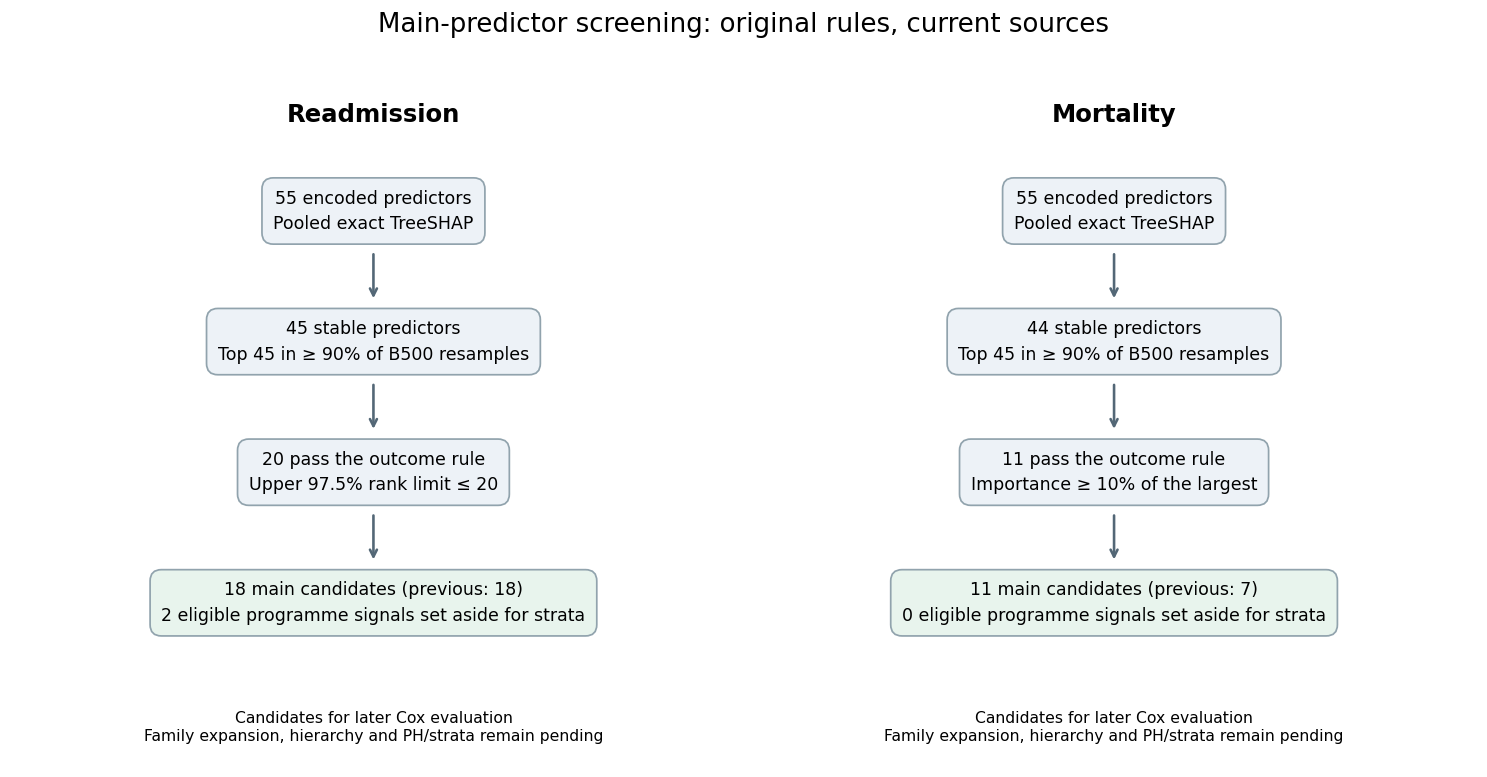

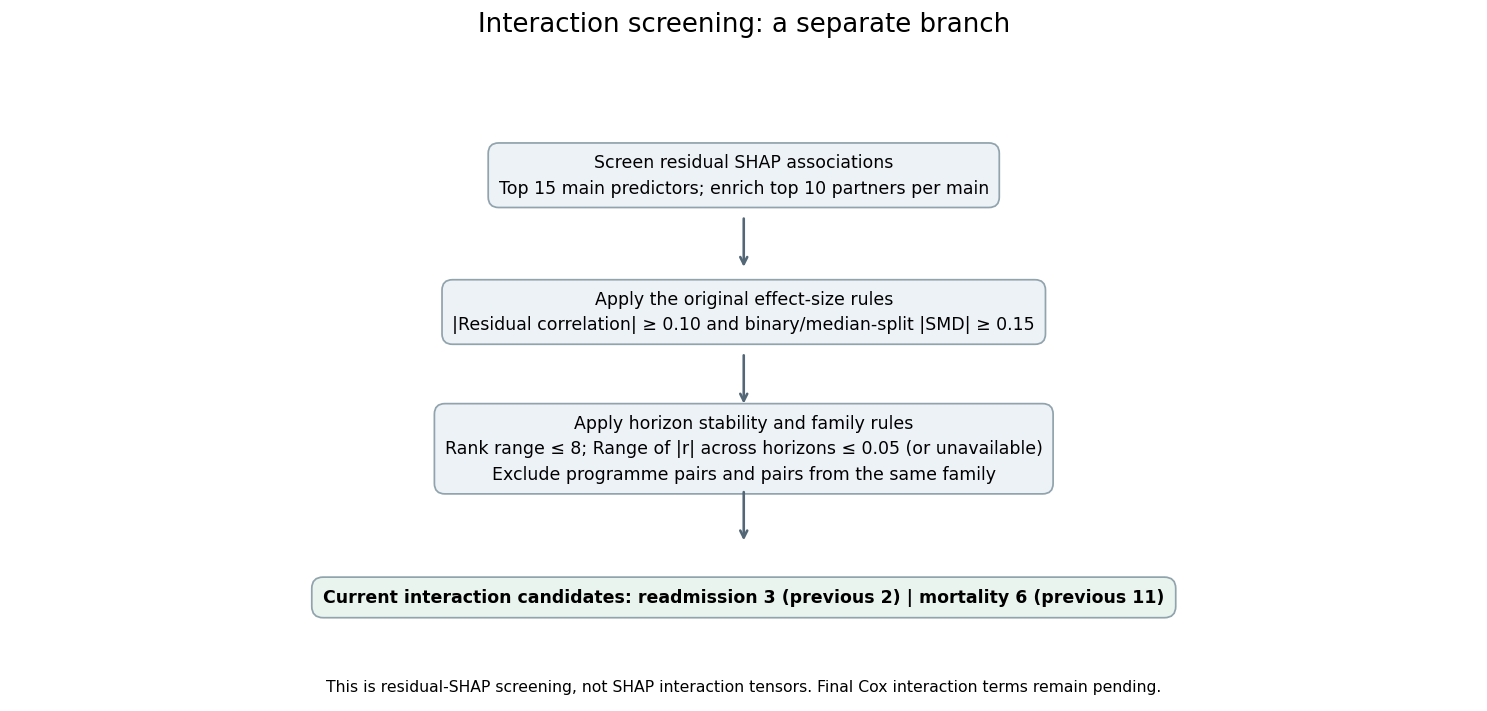

Outcome,Encoded predictors,Stable in top 45,Pass outcome rule,Programme signals reserved,Main candidates,Previous main candidates,Interaction candidates,Previous interaction candidates
Readmission,55,45,20,2,18,18,3,2
Death,55,44,11,0,11,7,6,11


These diagrams stay inside the notebook/HTML; no intermediate diagram files are exported.
Elapsed: 0.005 minutes


In [19]:
#| label: combined-selection-flowcharts
#| message: false
t0 = time.perf_counter()
# Derive every displayed count from the saved, reviewed selection tables.
import matplotlib.pyplot as plt
assert main_review_signature in settings["accepted_discrepancy_signatures"] and interaction_review_signature in settings["accepted_discrepancy_signatures"]
selection_counts = []
for outcome in ["Readmission", "Death"]:
    frame = predictor_table.loc[predictor_table["outcome"].eq(outcome)]
    old = historical_predictor_rebuilt.loc[historical_predictor_rebuilt["outcome"].eq(outcome)]
    selection_counts.append({"Outcome": outcome, "Encoded predictors": len(frame), "Stable in top 45": int(frame["stable_freq_ge_90pct"].sum()), "Pass outcome rule": int(frame["qualifies_main_rule"].sum()), "Programme signals reserved": int((frame["qualifies_main_rule"] & frame["programme_stratum_only"]).sum()), "Main candidates": int(frame["qualifies_etable3"].sum()), "Previous main candidates": int(old["qualifies_etable3"].sum()), "Interaction candidates": int(cox_interactions["outcome"].eq(outcome).sum()), "Previous interaction candidates": int(historical_eligible_interactions["outcome"].eq(outcome).sum())})
selection_counts = pd.DataFrame(selection_counts)
assert np.array_equal(selection_counts["Main candidates"], selection_counts["Pass outcome rule"] - selection_counts["Programme signals reserved"])
with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 10, "figure.dpi": 125}):
    fig, axes = plt.subplots(1, 2, figsize=(12, 6.2))
    for ax, row in zip(axes, selection_counts.to_dict("records")):
        ax.set(xlim=(0, 1), ylim=(0, 1))
        ax.axis("off")
        ax.set_title("Readmission" if row["Outcome"] == "Readmission" else "Mortality", fontsize=14, fontweight="bold", pad=12)
        rule = "Upper 97.5% rank limit \u2264 20" if row["Outcome"] == "Readmission" else "Importance \u2265 10% of the largest"
        steps = [f'{row["Encoded predictors"]} encoded predictors\nPooled exact TreeSHAP', f'{row["Stable in top 45"]} stable predictors\nTop 45 in \u2265 90% of B500 resamples', f'{row["Pass outcome rule"]} pass the outcome rule\n{rule}', f'{row["Main candidates"]} main candidates (previous: {row["Previous main candidates"]})\n{row["Programme signals reserved"]} eligible programme signals set aside for strata']
        ys = [.89, .68, .47, .26]
        for i, (y, text) in enumerate(zip(ys, steps)):
            ax.text(.5, y, text, transform=ax.transAxes, ha="center", va="center", linespacing=1.55, bbox={"boxstyle": "round,pad=.65", "facecolor": "#e8f4ed" if i == 3 else "#edf2f7", "edgecolor": "#91a3ad"})
            if i < len(ys) - 1:
                ax.annotate("", xy=(.5, ys[i+1]+.064), xytext=(.5, y-.064), arrowprops={"arrowstyle": "->", "color": "#536776", "lw": 1.5})
        ax.text(.5, .06, "Candidates for later Cox evaluation\nFamily expansion, hierarchy and PH/strata remain pending", transform=ax.transAxes, ha="center", va="center", fontsize=9)
    fig.suptitle("Main-predictor screening: original rules, current sources", fontsize=15, y=.995)
    fig.tight_layout(rect=(0, 0, 1, .96))
    plt.show()
    plt.close(fig)
    fig, ax = plt.subplots(figsize=(12, 5.7))
    ax.set(xlim=(0, 1), ylim=(0, 1))
    ax.axis("off")
    steps = [("Screen residual SHAP associations", "Top 15 main predictors; enrich top 10 partners per main"), ("Apply the original effect-size rules", "|Residual correlation| \u2265 0.10 and binary/median-split |SMD| \u2265 0.15"), ("Apply horizon stability and family rules", "Rank range \u2264 8; Range of |r| across horizons \u2264 0.05 (or unavailable)\nExclude programme pairs and pairs from the same family")]
    for y, (title, detail) in zip([.88, .65, .42], steps):
        ax.text(.5, y, title + "\n" + detail, ha="center", va="center", linespacing=1.55, bbox={"boxstyle": "round,pad=.6", "facecolor": "#edf2f7", "edgecolor": "#91a3ad"})
        ax.annotate("", xy=(.5, y-.16), xytext=(.5, y-.067), arrowprops={"arrowstyle": "->", "color": "#536776", "lw": 1.5})
    counts = selection_counts.set_index("Outcome")
    r, d = counts.loc["Readmission"], counts.loc["Death"]
    final_text = f'Current interaction candidates: readmission {r["Interaction candidates"]} (previous {r["Previous interaction candidates"]}) | mortality {d["Interaction candidates"]} (previous {d["Previous interaction candidates"]})'
    ax.text(.5, .17, final_text, ha="center", va="center", bbox={"boxstyle": "round,pad=.65", "facecolor": "#e8f4ed", "edgecolor": "#91a3ad"}, fontweight="bold")
    ax.text(.5, .02, "This is residual-SHAP screening, not SHAP interaction tensors. Final Cox interaction terms remain pending.", ha="center", va="center", fontsize=9)
    fig.suptitle("Interaction screening: a separate branch", fontsize=15, y=.99)
    fig.tight_layout(rect=(0, 0, 1, .95))
    plt.show()
    plt.close(fig)
show_table(selection_counts, "Counts behind the selection flowcharts; descriptive candidates, not final Cox coefficients")
print("These diagrams stay inside the notebook/HTML; no intermediate diagram files are exported.")
print(f"Elapsed: {(time.perf_counter() - t0) / 60:.3f} minutes")

In [20]:
#| label: combined-figure-reporting-helpers
#| message: false
t0 = time.perf_counter()
# Cache key figures separately from scientific models and preserve their source-code provenance.
from IPython.display import Image
import matplotlib.pyplot as plt
figure_exports = []
def figure_reporting_paths(stem, cell_label):
    # Bind cached approvals to the current pooled source and exact comparison content.
    assert analysis_signature == fingerprint(analysis_contract) and analysis_contract["pooled_signature"] == pooled_signature, "Stale analysis source."
    for comparison, stage, approved in [(main_comparison, "eTable3 and Figure2 SHAP screening", main_review_signature), (interaction_comparison, "eTable4 residual interaction screening", interaction_review_signature)]:
        current = fingerprint({"stage": stage, "analysis_signature": analysis_signature, "comparison_csv": comparison.to_csv(index=False, lineterminator="\n")})
        assert current == approved and current in settings["accepted_discrepancy_signatures"], "Stale or unapproved figure checkpoint."
    source = notebook_code(source_path("combined_notebook"), ["combined-figure-reporting-helpers", cell_label])
    contract = {"pooled_signature": pooled_signature, "analysis_signature": analysis_signature, "source_hash": fingerprint(source), "versions": {name: importlib.metadata.version(name) for name in ["numpy", "pandas", "matplotlib", "scipy"]}}
    signature = fingerprint(contract)
    folder = resolve_path(config["paths"]["figures"])
    folder.mkdir(parents=True, exist_ok=True)
    paths = {}
    for extension in ["png", "pdf"]:
        matches = sorted(folder.glob(f"{stem}_????-??-??_{signature}.{extension}"))
        assert len(matches) <= 1, f"Ambiguous figure artifact: {stem} / {signature}"
        paths[extension] = matches[0] if matches else folder / f"{stem}_{datetime.date.today().isoformat()}_{signature}.{extension}"
    return contract, signature, paths, artifact_path(stem + "_reporting", signature, ".pkl")
def show_figure_reporting(cache_path, contract):
    with cache_path.open("rb") as stream:
        cache = pickle.load(stream)
    assert cache["contract"] == contract, "Figure source contract changed."
    for item in cache["files"]:
        path = resolve_path(item["path"])
        assert path.is_file() and file_sha256(path) == item["sha256"], f"Figure file differs: {item['path']}"
        if path.suffix in [".png", ".pdf"]:
            figure_exports.append(path)
    display(Image(filename=str(resolve_path(cache["png"])), width=760))
    for caption, table in cache["tables"]:
        show_table(table, caption)
    show_table(pd.DataFrame(cache["files"]), "Verified figure artifacts; saved or reused")
    return cache
def save_figure_reporting(fig, paths, cache_path, contract, tables, extra_files=()):
    # Write compact print-ready artifacts once; subsequent runs verify and reuse them.
    assert not any(path.exists() for path in paths.values()), "Incomplete reporting bundle: inspect existing artifacts before replacing."
    files = []
    for extension, path in paths.items():
        temporary = path.with_suffix("." + extension + ".partial")
        with plt.rc_context({"pdf.fonttype": 42, "ps.fonttype": 42}):
            fig.savefig(temporary, format=extension, dpi=600, facecolor="white")
        temporary.replace(path)
        written.append(path)
        files.append({"path": path.relative_to(root).as_posix(), "bytes": path.stat().st_size, "sha256": file_sha256(path)})
    for path in extra_files:
        files.append({"path": path.relative_to(root).as_posix(), "bytes": path.stat().st_size, "sha256": file_sha256(path)})
    save_pickle({"contract": contract, "png": paths["png"].relative_to(root).as_posix(), "files": files, "tables": tables}, cache_path)
print("Figure-only caches preserve PNG/PDF files and compact display tables; they do not refit models or recalculate TreeSHAP.")
print(f"Elapsed: {(time.perf_counter() - t0) / 60:.3f} minutes")

Figure-only caches preserve PNG/PDF files and compact display tables; they do not refit models or recalculate TreeSHAP.
Elapsed: 0.000 minutes


## Figure 2. Predictor contributions
**Predictor contributions to gradient boosted survival models for first readmission to substance use disorder treatment (A, B) and all-cause mortality after discharge (C, D), 2010-2020, Chile.**

Read A/C as relative importance within each outcome and B/D as signed contributions to the model log hazard. Points to the right increase the model score; points to the left decrease it. Colour indicates lower to higher encoded feature values. Indicator coding starts at 0/1; pooled feature values can be fractional after averaging across imputations. The marker ‡ identifies predictors shown with their source numeric category coding; higher colour does not always mean a more favourable category. See eFigure 2 for category labels. Bars use the whole development cohort; beeswarms retain the original display-only cap of 4,000 participants. This plot describes model predictions and does not estimate causal effects.

The top 15 displayed predictors are not the complete eligible candidate list. The table below provides the reviewed caption maxima; the Word manuscript is unchanged.

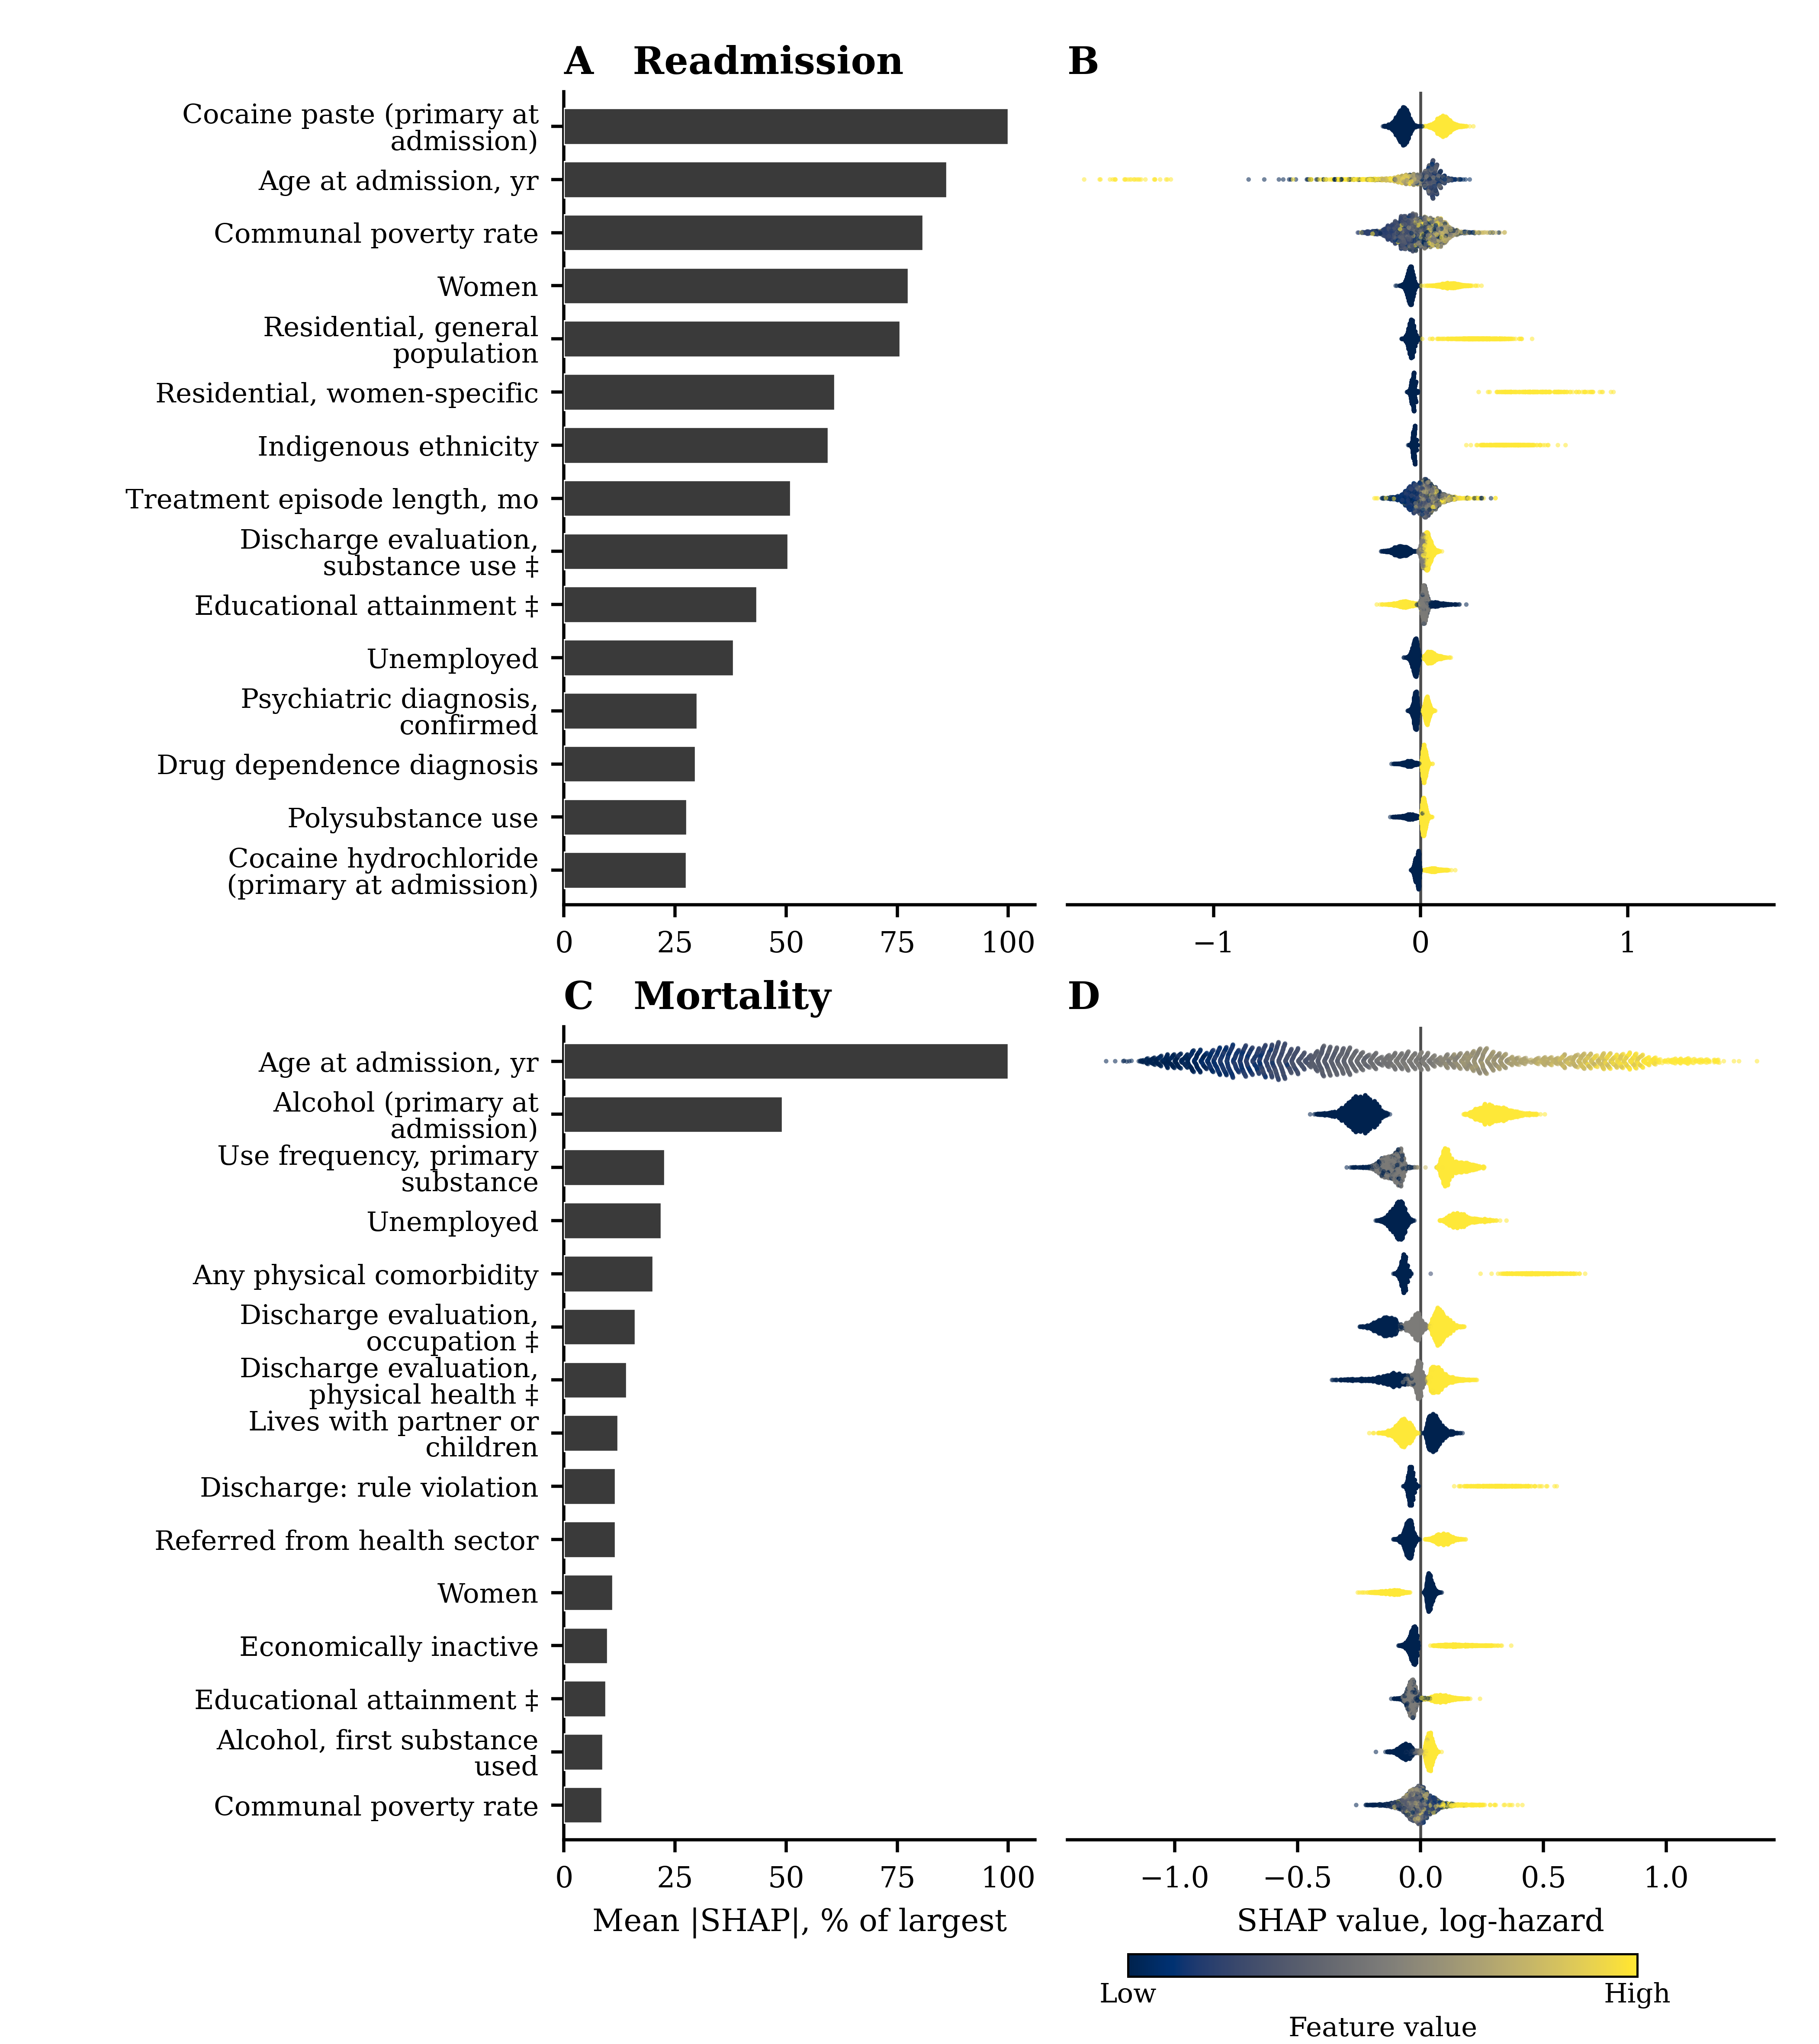

Outcome,Largest mean absolute SHAP,Beeswarm half-range,Plot seed,Sample cap
Readmission,0.096910,1.706750,42,4000
Mortality,0.541719,1.437598,42,4000


path,bytes,sha256
outputs/figures/figure2_xgboost_shap_2026-10-04_f694f4809b7c.png,1143384,f52242cbd86a13258de7661091cd2b40e18a7034e306489903dc7988a9e1be50
outputs/figures/figure2_xgboost_shap_2026-10-04_f694f4809b7c.pdf,376311,f78aba1bb743bb4048e6d9781ab036c8830b07fd7a933e4383c695e7fe5e3058


Importance uses every development participant; the original 4,000-person cap applies only to points displayed in each beeswarm.
Elapsed: 0.056 minutes


In [21]:
#| label: combined-figure2-shap
#| message: false
t0 = time.perf_counter()
# Require the exact approved comparisons before exporting the manuscript figure.
assert settings["mode"] == "full" and main_review_signature in settings["accepted_discrepancy_signatures"] and interaction_review_signature in settings["accepted_discrepancy_signatures"]
figure2_contract, figure2_signature, figure2_paths, figure2_cache_path = figure_reporting_paths("figure2_xgboost_shap", "combined-figure2-shap")
if not figure2_cache_path.exists():
    # Preserve the original Figure 2 statistics, labels and display sampling.
    import textwrap
    import matplotlib.pyplot as plt
    import matplotlib.gridspec as gridspec
    from matplotlib.cm import ScalarMappable
    from matplotlib.colors import Normalize
    for outcome in ("Readmission", "Death"):
        assert pooled_shap[outcome].index.equals(pooled_x.index) and pooled_shap[outcome].columns.equals(pooled_x.columns)
        assert np.isfinite(pooled_shap[outcome]).all().all()
    assert np.isfinite(pooled_x).all().all()
    EPI_X, EPI_FEATS = pooled_x, list(pooled_x.columns)
    EPI_SHAP = {"shap_r_all": pooled_shap["Readmission"].to_numpy(), "shap_d_all": pooled_shap["Death"].to_numpy()}
    EPI_TOP_N = 15
    EPI_MAX_BEE_N = 4000
    EPI_WIDTH_CM = 17.8
    EPI_HEIGHT_CM = 20.0
    EPI_BEE_CMAP = 'cividis'
    EPI_BAR_GRAY = '#3a3a3a'
    EPI_BAR_SCALE = 'relative'
    EPI_ANNOTATE_MAX = False
    EPI_SHOW_REL_REFERENCE = False
    EPI_XLABEL_BOTTOM_ONLY = True
    EPI_SHARED_BEE_XLIM = False
    EPI_SEED = 42
    EPI_LABELS = {'adm_age_rec3': 'Age at admission, yr', 'porc_pobr': 'Communal poverty rate', 'dit_m': 'Treatment episode length, mo', 'tenure_status_household': 'Housing precarity \u2021', 'prim_sub_freq_rec': 'Use frequency, primary substance', 'national_foreign': 'Foreign nationality', 'urbanicity_cat': 'Rural residence \u2021', 'ed_attainment_corr': 'Educational attainment \u2021', 'evaluacindelprocesoteraputico': 'Discharge evaluation, therapeutic process \u2021', 'eva_consumo': 'Discharge evaluation, substance use \u2021', 'eva_fam': 'Discharge evaluation, family \u2021', 'eva_relinterp': 'Discharge evaluation, interpersonal \u2021', 'eva_ocupacion': 'Discharge evaluation, occupation \u2021', 'eva_sm': 'Discharge evaluation, mental health \u2021', 'eva_fisica': 'Discharge evaluation, physical health \u2021', 'eva_transgnorma': 'Discharge evaluation, rule adherence \u2021', 'ethnicity': 'Indigenous ethnicity', 'dg_psiq_cie_10_instudy': 'Psychiatric diagnosis under study', 'dg_psiq_cie_10_dg': 'Psychiatric diagnosis, confirmed', 'dx_f3_mood': 'Mood disorder (F30-F39)', 'dx_f6_personality': 'Personality disorder (F60-F69)', 'dx_f_any_severe_mental': 'Severe mental disorder (F0, F2, F7-F9)', 'any_phys_dx': 'Any physical comorbidity', 'polysubstance_strict': 'Polysubstance use', 'sex_rec_woman': 'Women', 'cohabitation_family_of_origin': 'Lives with family of origin', 'cohabitation_with_couple_children': 'Lives with partner or children', 'cohabitation_others': 'Lives with others', 'sub_dep_icd10_status_drug_dependence': 'Drug dependence diagnosis', 'any_violence_1_domestic_violence_sex_abuse': 'Domestic violence or sexual abuse', 'tr_outcome_referral': 'Discharge: referral', 'tr_outcome_dropout': 'Discharge: dropout', 'tr_outcome_adm_discharge_rule_violation_undet': 'Discharge: rule violation', 'tr_outcome_adm_discharge_adm_reasons': 'Discharge: administrative', 'tr_outcome_other': 'Discharge: other', 'adm_motive_sanitary_sector': 'Referred from health sector', 'adm_motive_another_sud_facility_fonodrogas_senda_previene': 'Referred from another SUD service', 'adm_motive_justice_sector': 'Referred from justice sector', 'adm_motive_other': 'Referral, other source', 'first_sub_used_alcohol': 'Alcohol, first substance used', 'first_sub_used_cocaine_paste': 'Cocaine paste, first substance used', 'first_sub_used_cocaine_powder': 'Cocaine hydrochloride, first used', 'first_sub_used_other': 'Other, first substance used', 'primary_sub_mod_alcohol': 'Alcohol (primary at admission)', 'primary_sub_mod_cocaine_paste': 'Cocaine paste (primary at admission)', 'primary_sub_mod_cocaine_powder': 'Cocaine hydrochloride (primary at admission)', 'primary_sub_mod_others': 'Other substance (primary at admission)', 'tipo_de_vivienda_rec2_other_unknown': 'Dwelling type, other or unknown', 'plan_type_corr_pg_pr': 'Residential, general population', 'plan_type_corr_m_pr': 'Residential, women-specific', 'plan_type_corr_pg_pai': 'Intensive outpatient, general pop.', 'plan_type_corr_m_pai': 'Intensive outpatient, women-specific', 'occupation_condition_corr24_unemployed': 'Unemployed', 'occupation_condition_corr24_inactive': 'Economically inactive', 'marital_status_rec_single': 'Single', 'marital_status_rec_separated_divorced_annulled_widowed': 'Separated, divorced or widowed'}
    EPI_RC = {'font.family': 'serif', 'font.serif': ['Times New Roman', 'Times', 'Nimbus Roman', 'DejaVu Serif'], 'font.size': 8.5, 'axes.labelsize': 8.5, 'axes.titlesize': 10.5, 'xtick.labelsize': 8.0, 'ytick.labelsize': 8.0, 'axes.linewidth': 0.9, 'xtick.major.width': 0.9, 'ytick.major.width': 0.9, 'figure.dpi': 200, 'savefig.dpi': 600, 'pdf.fonttype': 42, 'ps.fonttype': 42}
    def epi_label(name):
        """Print label for a raw feature name, with a readable fallback."""
        return EPI_LABELS.get(name, str(name).replace("_", " ").capitalize())
    def epi_wrap(label, width=32):
        """Wrap a print label so it fits the left margin without colliding with the bars."""
        return "\n".join(textwrap.wrap(label, width=width, break_long_words=False, break_on_hyphens=False))
    def epi_swarm_offsets(vals, row_height=0.40, nbins=100):
        """Vertical jitter proportional to local density, mirroring the SHAP beeswarm layout."""
        n = vals.shape[0]
        if n == 0:
            return np.zeros(0)
        order = np.argsort(vals, kind="mergesort")
        v = vals[order]
        span = float(v[-1] - v[0])
        if span <= 0:
            return np.zeros(n)
        quant = np.round(nbins * (v - v[0]) / span)
        ys = np.zeros(n)
        layer = 0
        last_bin = -1.0
        for i in range(n):
            if quant[i] != last_bin:
                layer = 0
            ys[i] = np.ceil(layer / 2.0) * ((layer % 2) * 2 - 1)
            layer += 1
            last_bin = quant[i]
        peak = float(np.max(np.abs(ys)))
        if peak > 0:
            ys = ys * (0.90 * row_height / peak)
        out = np.zeros(n)
        out[order] = ys
        return out
    def epi_draw_beeswarm(ax, S_sub, X_sub, cmap, point_size=1.6, alpha=0.55):
        """Draw one beeswarm panel; colour = within-variable percentile-scaled feature value."""
        n_feat = S_sub.shape[1]
        for j in range(n_feat):
            y_base = n_feat - 1 - j
            sv = S_sub[:, j].astype(float)
            yj = y_base + epi_swarm_offsets(sv)
            fv = X_sub[:, j].astype(float)
            ok = np.isfinite(fv)
            if ok.sum() > 0:
                lo, hi = np.nanpercentile(fv[ok], [5, 95])
                if not np.isfinite(hi) or hi <= lo:
                    lo, hi = float(np.nanmin(fv[ok])), float(np.nanmax(fv[ok]))
                cvals = np.clip((fv - lo) / (hi - lo + 1e-12), 0.0, 1.0)
            else:
                cvals = np.full(fv.shape, 0.5)
            ax.scatter(sv[ok], yj[ok], c=cvals[ok], cmap=cmap, vmin=0.0, vmax=1.0,
                       s=point_size, linewidths=0.0, alpha=alpha, rasterized=True, zorder=3)
            if (~ok).sum() > 0:
                ax.scatter(sv[~ok], yj[~ok], color="#9a9a9a", s=point_size, linewidths=0.0,
                           alpha=alpha, rasterized=True, zorder=2)
        ax.axvline(0.0, color="0.30", lw=0.8, zorder=1)
        ax.set_ylim(-0.65, n_feat - 0.35)
    def epi_row(ax_bar, ax_bee, shap_key, letters, row_name, cmap, is_bottom_row):
        """Populate one outcome row; return its beeswarm half-range and its absolute |SHAP| maximum."""
        S = np.asarray(EPI_SHAP[shap_key], dtype=float)
        assert S.shape == EPI_X.shape, "SHAP and feature shape mismatch."
        n, p = S.shape
        Xd = EPI_X
        imp = np.abs(S).mean(axis=0)
        order = np.argsort(imp)[::-1][:min(EPI_TOP_N, p)]
        labels = [epi_label(EPI_FEATS[i]) for i in order]
        imp_top = imp[order]
        imp_max = float(imp_top.max())
        relative = EPI_BAR_SCALE == "relative"
        assert np.isfinite(imp_max) and imp_max > 0, "Relative importance requires a positive maximum."
        vals = 100.0 * imp_top / imp_max if relative else imp_top
        y_pos = np.arange(len(order))[::-1]
        ax_bar.barh(y_pos, vals, color=EPI_BAR_GRAY, edgecolor="white", linewidth=0.4, height=0.68, zorder=3)
        if relative:
            ax_bar.set_xlim(0.0, 106.0)
            ax_bar.set_xticks([0, 25, 50, 75, 100])
            bar_xlabel = "Mean |SHAP|, % of largest"
            if EPI_SHOW_REL_REFERENCE:
                ax_bar.axvline(10.0, ls=":", lw=0.9, color="0.35", zorder=4)
        else:
            bar_xlabel = "Mean |SHAP|, log-hazard"
        if EPI_ANNOTATE_MAX and relative:
            ax_bar.text(0.975, 0.015, f"largest = {imp_max:.3f}", transform=ax_bar.transAxes,
                        ha="right", va="bottom", fontsize=6.5, color="0.25")
        ax_bar.set_yticks(y_pos)
        ax_bar.set_yticklabels([epi_wrap(x, width=28) for x in labels], fontsize=7.5, linespacing=1.0)
        ax_bar.set_ylim(-0.65, len(order) - 0.35)
        ax_bar.spines["top"].set_visible(False)
        ax_bar.spines["right"].set_visible(False)
        ax_bar.set_title(f"{letters[0]}   {row_name}", loc="left", fontweight="bold", fontsize=10.5, pad=5)
        rng = np.random.RandomState(EPI_SEED)
        idx = rng.choice(n, size=min(n, EPI_MAX_BEE_N), replace=False) if n > EPI_MAX_BEE_N else np.arange(n)
        S_bee = S[np.ix_(idx, order)]
        X_bee = Xd.to_numpy(dtype=float)[np.ix_(idx, order)]
        epi_draw_beeswarm(ax_bee, S_bee, X_bee, cmap)
        ax_bee.set_yticks(y_pos)
        ax_bee.set_yticklabels([])
        ax_bee.tick_params(left=False)
        ax_bee.spines["top"].set_visible(False)
        ax_bee.spines["right"].set_visible(False)
        ax_bee.spines["left"].set_visible(False)
        ax_bee.set_title(letters[1], loc="left", fontweight="bold", fontsize=10.5, pad=5)
        lim = float(np.nanmax(np.abs(S_bee))) * 1.05
        ax_bee.set_xlim(-lim, lim)
        # A and C carry the same x-label, B and D carry the same one; print each only once, at the bottom.
        show_labels = is_bottom_row or not EPI_XLABEL_BOTTOM_ONLY
        ax_bar.set_xlabel(bar_xlabel if show_labels else "")
        ax_bee.set_xlabel("SHAP value, log-hazard" if show_labels else "")
        return lim, imp_max
    assert all(name in EPI_LABELS for name in EPI_FEATS), "An encoded predictor needs a reviewed print label."
    with plt.rc_context(EPI_RC):
        fig = plt.figure(figsize=(EPI_WIDTH_CM / 2.54, EPI_HEIGHT_CM / 2.54))
        gs = gridspec.GridSpec(2, 2, figure=fig, width_ratios=[1.0, 1.5], left=0.310, right=0.975, top=0.955, bottom=0.100, wspace=0.055, hspace=0.150)
        axes = [fig.add_subplot(gs[row, col]) for row in range(2) for col in range(2)]
        cmap = plt.get_cmap(EPI_BEE_CMAP)
        lim_r, max_r = epi_row(axes[0], axes[1], "shap_r_all", ("A", "B"), "Readmission", cmap, False)
        lim_d, max_d = epi_row(axes[2], axes[3], "shap_d_all", ("C", "D"), "Mortality", cmap, True)
        cax = fig.add_axes([0.62, 0.033, 0.28, 0.011])
        cb = fig.colorbar(ScalarMappable(norm=Normalize(0, 1), cmap=cmap), cax=cax, orientation="horizontal")
        cb.set_ticks([0, 1], labels=["Low", "High"])
        cb.outline.set_linewidth(0.6)
        cb.ax.tick_params(length=0, labelsize=7.5, pad=1.5)
        cb.set_label("Feature value", fontsize=7.5, labelpad=2)
    # Check real feature labels before saving; wrapping changes presentation only.
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    for axis in [axes[0], axes[2]]:
        boxes = [tick.get_window_extent(renderer) for tick in axis.get_yticklabels()]
        assert all(box.x0 >= 0 and box.x1 <= fig.bbox.width and box.y0 >= 0 and box.y1 <= fig.bbox.height for box in boxes), "Figure 2 label is clipped."
        assert not any(left.overlaps(right) for left, right in zip(boxes, boxes[1:])), "Figure 2 adjacent labels overlap."
    figure2_caption_values = pd.DataFrame({"Outcome": ["Readmission", "Mortality"], "Largest mean absolute SHAP": [max_r, max_d], "Beeswarm half-range": [lim_r, lim_d], "Plot seed": [EPI_SEED, EPI_SEED], "Sample cap": [EPI_MAX_BEE_N, EPI_MAX_BEE_N]})
    for outcome, actual in [("Readmission", max_r), ("Death", max_d)]:
        expected = predictor_table.loc[predictor_table["outcome"].eq(outcome), "mean_abs_shap_log_hazard"].max()
        assert np.isclose(actual, expected, rtol=1e-12, atol=1e-12), "Figure 2 importance differs from its reviewed source."
    save_figure_reporting(fig, figure2_paths, figure2_cache_path, figure2_contract, [("Figure 2 caption values; reviewed source maxima", figure2_caption_values)])
    plt.close(fig)
figure2_reporting = show_figure_reporting(figure2_cache_path, figure2_contract)
figure2_caption_values = figure2_reporting["tables"][0][1]
print("Importance uses every development participant; the original 4,000-person cap applies only to points displayed in each beeswarm.")
print(f"Elapsed: {(time.perf_counter() - t0) / 60:.3f} minutes")

In [22]:
#| label: combined-functional-form-source-export
#| message: false
t0 = time.perf_counter()
# Retain the direct eFigure2 source and original descriptive quadratic check without the unused cubic bootstrap.
assert "main_review_signature" in globals() and "interaction_review_signature" in globals()
functional_predictors = ["adm_age_rec3", "porc_pobr", "dit_m", "tenure_status_household", "urbanicity_cat", "evaluacindelprocesoteraputico", "eva_consumo", "eva_fam", "eva_relinterp", "eva_ocupacion", "eva_sm", "eva_fisica", "eva_transgnorma", "prim_sub_freq_rec", "ed_attainment_corr"]
assert set(functional_predictors).issubset(pooled_x.columns)
functional_path = artifact_path("eFigure2_SHAP_functional_source", analysis_signature, ".parquet")
functional_summary_path = artifact_path("xgb_combined_functional_summary", analysis_signature, ".pkl")
if functional_path.exists() and functional_summary_path.exists():
    with functional_summary_path.open("rb") as stream:
        functional_cache = pickle.load(stream)
    assert functional_cache["contract"] == analysis_contract
    functional_summary = functional_cache["summary"]
else:
    frames, summaries = [], []
    for outcome in ["Readmission", "Death"]:
        for feature in functional_predictors:
            x = pooled_x[feature].to_numpy(dtype=float)
            y = pooled_shap[outcome][feature].to_numpy(dtype=float)
            valid = np.isfinite(x) & np.isfinite(y)
            x, y = x[valid], y[valid]
            frames.append(pd.DataFrame({"Feature_Value": x, "SHAP_Impact": y, "Predictor": feature, "Outcome": outcome, "Scope": "Aggregated_All_Times"}))
            linear = np.column_stack([np.ones(len(x)), x])
            quadratic = np.column_stack([np.ones(len(x)), x, x ** 2])
            rss1 = np.sum((y - linear @ np.linalg.lstsq(linear, y, rcond=None)[0]) ** 2)
            rss2 = np.sum((y - quadratic @ np.linalg.lstsq(quadratic, y, rcond=None)[0]) ** 2)
            f_value = ((rss1 - rss2) / (rss2 / (len(x) - 3))) if len(x) >= 10 and rss2 > 0 and rss1 >= rss2 else np.nan
            p_value = float(fisher_f.sf(f_value, 1, len(x) - 3)) if np.isfinite(f_value) else np.nan
            q10, q50, q90 = np.quantile(y, [0.10, 0.50, 0.90])
            summaries.append({"Outcome": outcome, "Predictor": feature, "N": len(x), "Mean_SHAP": float(y.mean()), "MeanAbs_SHAP": float(np.abs(y).mean()), "Q10": q10, "Q50": q50, "Q90": q90, "F_linear_vs_quad": f_value, "P_linear_vs_quad": p_value, "Nonlinear_p_lt_.05": bool(p_value < 0.05) if np.isfinite(p_value) else False, "Corr_X_SHAP": float(np.corrcoef(x, y)[0, 1]) if x.std() > 0 and y.std() > 0 else np.nan})
    functional_source = pd.concat(frames, ignore_index=True)
    assert len(functional_source) == len(pooled_x) * len(functional_predictors) * 2
    temporary = functional_path.with_suffix(".parquet.partial")
    functional_source.to_parquet(temporary, index=False)
    temporary.replace(functional_path)
    written.append(functional_path)
    functional_summary = pd.DataFrame(summaries)
    save_pickle({"contract": analysis_contract, "summary": functional_summary}, functional_summary_path)
    del functional_source, frames
show_table(functional_summary, "Original descriptive linear-versus-quadratic check; Cox functional-form decisions remain downstream")
print("The rank bootstrap remains B500. Unused magnitude, direction, and duplicate cubic-curve bootstrap intervals are omitted with their traceability record.")
print(f"Functional source: {functional_path.relative_to(root).as_posix()}")
print(f"Elapsed: {(time.perf_counter() - t0) / 60:.3f} minutes")


Outcome,Predictor,N,Mean_SHAP,MeanAbs_SHAP,Q10,Q50,Q90,F_linear_vs_quad,P_linear_vs_quad,Nonlinear_p_lt_.05,Corr_X_SHAP
Readmission,adm_age_rec3,70521,-0.010801,0.083499,-0.120517,0.032752,0.085284,50274.957385,0.000000,True,-0.502872
Readmission,porc_pobr,70521,-0.014594,0.078314,-0.135260,-0.017187,0.105671,1109.624512,0.000000,True,0.403541
Readmission,dit_m,70521,0.010772,0.049453,-0.064066,0.009790,0.088917,7174.733444,0.000000,True,0.470031
Readmission,tenure_status_household,70521,0.002038,0.015685,-0.020694,-0.000681,0.028780,12510.107406,0.000000,True,-0.558887
Readmission,urbanicity_cat,70521,0.001886,0.011621,-0.011809,-0.003674,0.026290,3956.414254,0.000000,True,0.719369
Readmission,evaluacindelprocesoteraputico,70521,-0.001363,0.021559,-0.051686,0.009635,0.022582,60062.272518,0.000000,True,0.816354
Readmission,eva_consumo,70521,-0.008133,0.048814,-0.107460,0.016944,0.048329,65493.105168,0.000000,True,0.899749
Readmission,eva_fam,70521,-0.001585,0.015687,-0.038122,0.005637,0.017034,83863.765687,0.000000,True,0.670530
Readmission,eva_relinterp,70521,0.001557,0.011002,-0.013763,0.000682,0.017858,23893.857163,0.000000,True,-0.670898
Readmission,eva_ocupacion,70521,0.000119,0.014254,-0.020423,-0.002097,0.021637,5542.336139,0.000000,True,0.780625


The rank bootstrap remains B500. Unused magnitude, direction, and duplicate cubic-curve bootstrap intervals are omitted with their traceability record.
Functional source: outputs/objects/eFigure2_SHAP_functional_source_2026-10-04_5258d5cd9527.parquet
Elapsed: 0.000 minutes


## eFigure 2. Functional patterns
Continuous predictors use up to 25 quantile groups with median SHAP and interquartile range. Categorical predictors use rounded pooled feature values for display, with level medians and interquartile ranges calculated on all observations. Only density/cloud displays are capped and trimmed as in the original figure. These spreads are not confidence intervals. The displayed delta is the peak-to-trough difference between group medians, on each outcome's model log-hazard scale. It does not by itself choose a spline or establish nonlinearity in Cox.

The numerical summaries were controlled against the original R rules on a separate synthetic fixture before use. Python density sampling and typography can differ from R; the quantile/median/IQR definitions are preserved.

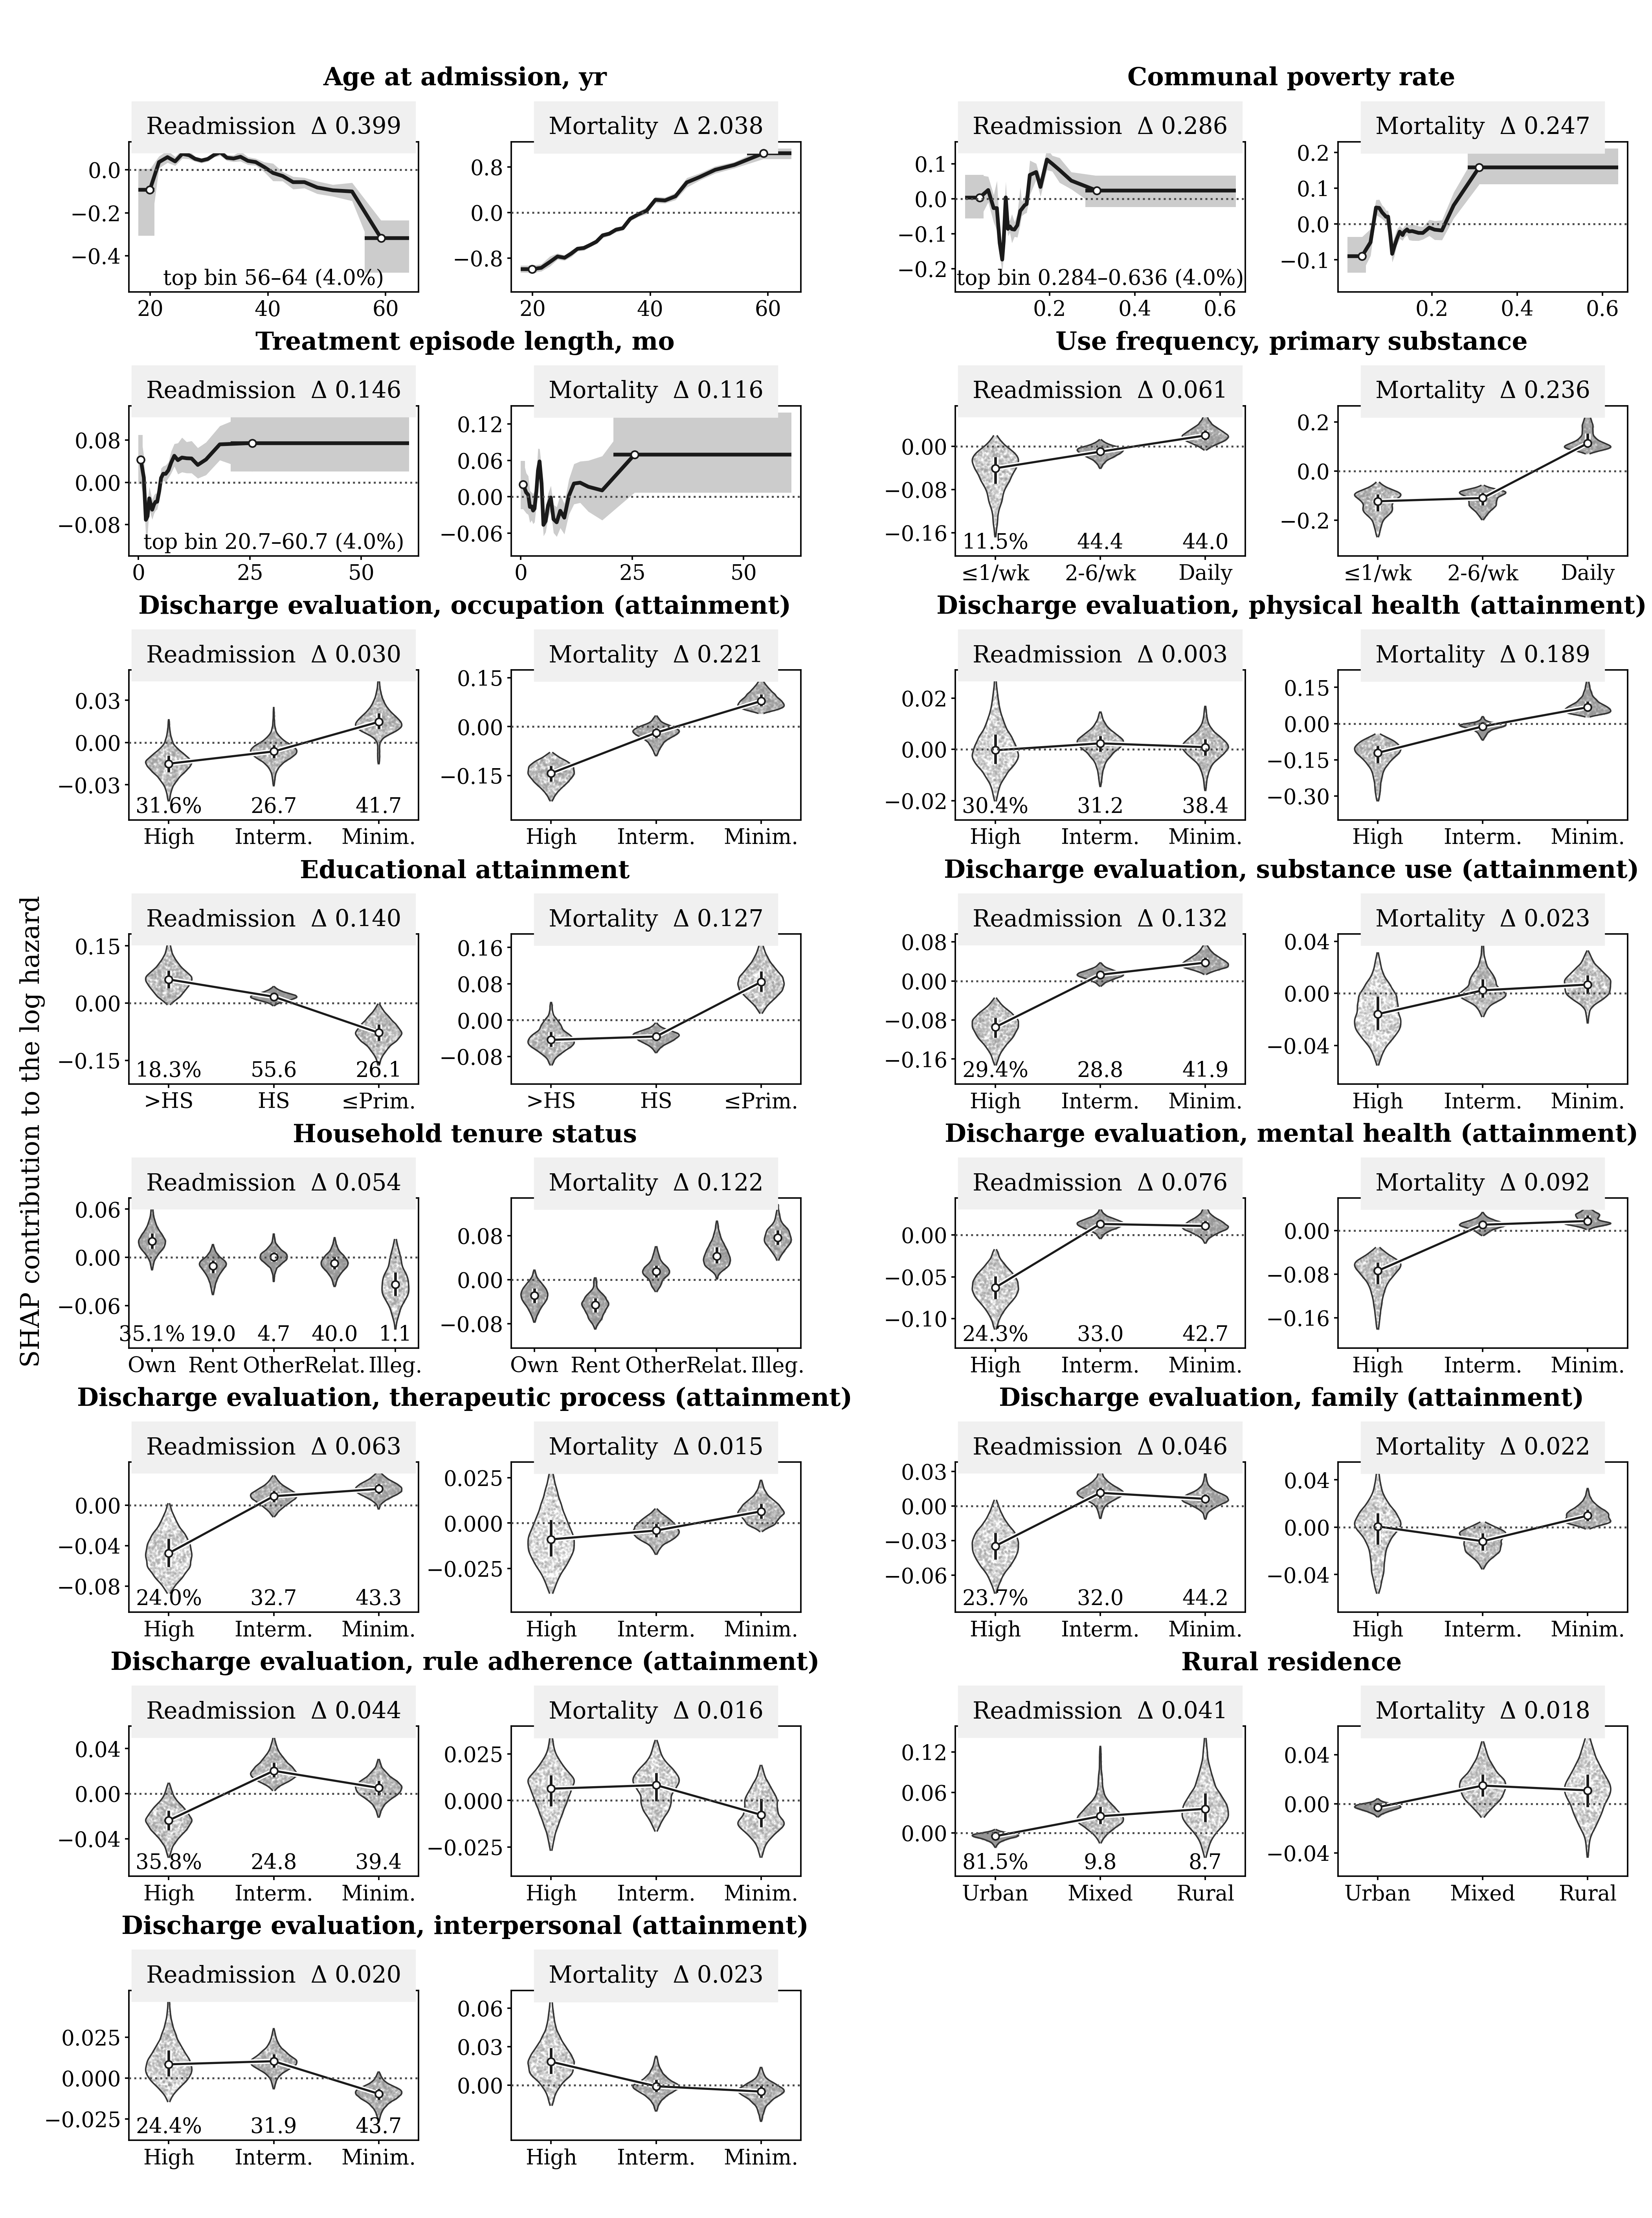

Predictor,Outcome,Median_swing,Groups,Support,Exact_integer_percent
adm_age_rec3,Readmission,0.399420,25,quantile groups,NaN
adm_age_rec3,Death,2.037970,25,quantile groups,NaN
dit_m,Readmission,0.145520,25,quantile groups,NaN
dit_m,Death,0.115806,25,quantile groups,NaN
porc_pobr,Readmission,0.286144,25,quantile groups,NaN
porc_pobr,Death,0.247326,25,quantile groups,NaN
ed_attainment_corr,Readmission,0.139562,3,rounded levels,99.690872
ed_attainment_corr,Death,0.127269,3,rounded levels,99.690872
eva_consumo,Readmission,0.131976,3,rounded levels,99.985820
eva_consumo,Death,0.022662,3,rounded levels,99.985820


Predictor,Outcome,Level,Full_N,After_display_clip_N,Violin_N,Cloud_N,Bandwidth
ed_attainment_corr,Death,0,12914,12654,12654,1000,0.003771
ed_attainment_corr,Death,1,39196,38412,20000,1000,0.001768
ed_attainment_corr,Death,2,18411,18041,18041,1000,0.004625
ed_attainment_corr,Readmission,0,12914,12654,12654,1000,0.005139
ed_attainment_corr,Readmission,1,39196,38412,20000,1000,0.001353
ed_attainment_corr,Readmission,2,18411,18041,18041,1000,0.004496
eva_consumo,Death,0,20700,20286,20000,1000,0.002416
eva_consumo,Death,1,20278,19872,19872,1000,0.001475
eva_consumo,Death,2,29543,28951,20000,1000,0.001403
eva_consumo,Readmission,0,20700,20286,20000,1000,0.003944


path,bytes,sha256
outputs/figures/efigure2_xgboost_functional_forms_2026-10-04_588995d1edf6.png,2805428,b671a396e6be982fb5298299acfb74ad794e37f59178295b075dafacce0bd913
outputs/figures/efigure2_xgboost_functional_forms_2026-10-04_588995d1edf6.pdf,727066,1305a1a5c08eda734a69826bd080ab75d8287aa7882f3b1c7f6d46fb2ec7896c
outputs/tables/eFigure2_functional_form_summaries_2026-10-04_588995d1edf6.csv,31801,4129691f0acc1f5c95a9e684e7e2517cb13fb369c1c1408f43b7ad2c6f47e09e


Continuous panels use up to 25 quantile groups; categorical panels use rounded display levels. Bands and bars are IQRs of SHAP contributions, not confidence intervals. Python/R density sampling and rasterization are not pixel-identical. Cox functional-form decisions remain downstream.
Elapsed: 0.142 minutes


In [23]:
#| label: combined-efigure2-functional-forms
#| message: false
t0 = time.perf_counter()
# Preserve the accepted screening scope before describing the functional patterns.
assert settings["mode"] == "full" and main_review_signature in settings["accepted_discrepancy_signatures"] and interaction_review_signature in settings["accepted_discrepancy_signatures"]
assert functional_path.is_file() and functional_summary_path.is_file()
efigure2_contract, efigure2_signature, efigure2_paths, efigure2_cache_path = figure_reporting_paths("efigure2_xgboost_functional_forms", "combined-efigure2-functional-forms")
if not efigure2_cache_path.exists():
    # Reproduce the R figure's plotted medians, IQRs, quantile bins and categorical display rules.
    import matplotlib.pyplot as plt
    import matplotlib.gridspec as gridspec
    from matplotlib.ticker import MaxNLocator, ScalarFormatter
    from scipy.stats import gaussian_kde
    import textwrap
    EF2_CONT = ["adm_age_rec3", "dit_m", "porc_pobr"]
    EF2_ORD = ["ed_attainment_corr", "eva_consumo", "eva_fam", "eva_fisica", "eva_ocupacion", "eva_relinterp", "eva_sm", "eva_transgnorma", "evaluacindelprocesoteraputico", "prim_sub_freq_rec", "tenure_status_household", "urbanicity_cat"]
    EF2_LABELS = {"adm_age_rec3": "Age at admission, yr", "dit_m": "Treatment episode length, mo", "porc_pobr": "Communal poverty rate", "ed_attainment_corr": "Educational attainment", "prim_sub_freq_rec": "Use frequency, primary substance", "tenure_status_household": "Household tenure status", "urbanicity_cat": "Rural residence"}
    for name, domain in {"eva_consumo": "substance use", "eva_fam": "family", "eva_fisica": "physical health", "eva_ocupacion": "occupation", "eva_relinterp": "interpersonal", "eva_sm": "mental health", "eva_transgnorma": "rule adherence", "evaluacindelprocesoteraputico": "therapeutic process"}.items():
        EF2_LABELS[name] = f"Discharge evaluation, {domain} (attainment)"
    EF2_TICKS = {name: ["High", "Interm.", "Minim."] for name in EF2_ORD if name.startswith("eva")}
    EF2_TICKS.update({"ed_attainment_corr": [">HS", "HS", "\u2264Prim."], "prim_sub_freq_rec": ["\u22641/wk", "2-6/wk", "Daily"], "tenure_status_household": ["Own", "Rent", "Other", "Relat.", "Illeg."], "urbanicity_cat": ["Urban", "Mixed", "Rural"]})
    EF2_OUTCOMES = {"Readmission": "Readmission", "Death": "Mortality"}
    def ef2_summary(feature_values, shap_values, continuous):
        x, y = np.asarray(feature_values, dtype=float), np.asarray(shap_values, dtype=float)
        assert x.ndim == y.ndim == 1 and x.shape == y.shape and len(x) > 0
        assert np.isfinite(x).all() and np.isfinite(y).all()
        if continuous:
            n_bins = min(25, len(np.unique(x)))
            assert n_bins > 1, "A continuous display requires at least two distinct predictor values."
            breaks = np.unique(np.quantile(x, np.linspace(0, 1, n_bins + 1), method="linear"))
            group = np.asarray(pd.cut(x, breaks, include_lowest=True, labels=False))
            assert np.isfinite(group).all()
        else:
            group = np.rint(x).astype(int)
        rows = []
        for level in np.unique(group):
            selected = group == level
            xv, yv = x[selected], y[selected]
            q25, med, q75 = np.quantile(yv, [.25, .5, .75], method="linear")
            rows.append({"Group": int(level), "X": float(np.median(xv)) if continuous else int(level), "X_min": float(xv.min()), "X_max": float(xv.max()), "Median_SHAP": med, "Q25_SHAP": q25, "Q75_SHAP": q75, "N": len(xv), "Distinct_X": len(np.unique(xv))})
        return pd.DataFrame(rows)
    # Require the same aligned, complete current source matrices used by Figure 2.
    assert set(EF2_CONT + EF2_ORD).issubset(pooled_x.columns)
    for outcome in EF2_OUTCOMES:
        assert pooled_shap[outcome].index.equals(pooled_x.index) and pooled_shap[outcome].columns.equals(pooled_x.columns)
    efigure2_summaries, ef2_groups, ef2_caption = [], {}, []
    for predictor in EF2_CONT + EF2_ORD:
        x = pooled_x[predictor].to_numpy(dtype=float)
        for outcome in EF2_OUTCOMES:
            summary = ef2_summary(x, pooled_shap[outcome][predictor].to_numpy(), predictor in EF2_CONT)
            summary.insert(0, "Outcome", outcome)
            summary.insert(0, "Predictor", predictor)
            assert summary["N"].sum() == len(pooled_x)
            if predictor in EF2_ORD:
                assert set(summary["Group"]).issubset(range(len(EF2_TICKS[predictor]))), "Rounded display level is outside the original dictionary."
            ef2_groups[predictor, outcome] = summary
            efigure2_summaries.append(summary)
            ef2_caption.append({"Predictor": predictor, "Outcome": outcome, "Median_swing": float(summary["Median_SHAP"].max() - summary["Median_SHAP"].min()), "Groups": len(summary), "Support": "quantile groups" if predictor in EF2_CONT else "rounded levels", "Exact_integer_percent": np.nan if predictor in EF2_CONT else float(100 * np.mean(np.abs(x - np.rint(x)) < 1e-9))})
    efigure2_summaries = pd.concat(efigure2_summaries, ignore_index=True)
    efigure2_caption = pd.DataFrame(ef2_caption)
    max_swing = efigure2_caption.groupby("Predictor")["Median_swing"].max()
    ef2_order = sorted(EF2_CONT, key=lambda name: (-max_swing[name], name)) + sorted(EF2_ORD, key=lambda name: (-max_swing[name], name))
    # Match the original capped density samples and bandwidth formula; Python and R random samples differ.
    rng = np.random.RandomState(20260820)
    ef2_density, ef2_display_audit = {}, []
    for predictor in sorted(EF2_ORD):
        levels = np.rint(pooled_x[predictor].to_numpy(dtype=float)).astype(int)
        for outcome in sorted(EF2_OUTCOMES):
            y = pooled_shap[outcome][predictor].to_numpy(dtype=float)
            for level in sorted(np.unique(levels)):
                full = y[levels == level]
                lo, hi = np.quantile(full, [.01, .99], method="linear")
                clipped = full if lo >= hi else full[(full >= lo) & (full <= hi)]
                violin = clipped[np.sort(rng.choice(len(clipped), 20000, replace=False))] if len(clipped) > 20000 else clipped
                cloud = violin[rng.choice(len(violin), 1000, replace=False)] if len(violin) > 1000 else violin
                grid, density, cloud_scale = np.array([]), np.array([]), np.ones(len(cloud))
                bandwidth = np.nan
                if len(violin) > 1 and np.std(violin, ddof=1) > 0:
                    sd = np.std(violin, ddof=1)
                    spread = min(sd, np.subtract(*np.quantile(violin, [.75, .25], method="linear")) / 1.34)
                    spread = spread if spread > 0 else sd
                    bandwidth = 0.9 * spread * len(violin) ** (-.2) * 1.15
                    grid = np.linspace(violin.min(), violin.max(), 512)
                    density = gaussian_kde(violin, bw_method=bandwidth / sd)(grid)
                    if len(violin) >= 8:
                        at_cloud = np.interp(cloud, grid, density)
                        cloud_scale = at_cloud / at_cloud.max()
                jitter = rng.uniform(-1, 1, len(cloud)) * .22 * cloud_scale
                ef2_density[predictor, outcome, level] = (violin, cloud, jitter, grid, density)
                ef2_display_audit.append({"Predictor": predictor, "Outcome": outcome, "Level": int(level), "Full_N": len(full), "After_display_clip_N": len(clipped), "Violin_N": len(violin), "Cloud_N": len(cloud), "Bandwidth": bandwidth})
    # Keep the R figure's panel order, free scales, full continuous x range and left-panel prevalence footers.
    ef2_rc = {"font.family": "serif", "font.serif": ["Times New Roman", "Times", "DejaVu Serif"], "font.size": 6.4, "axes.linewidth": .45, "xtick.major.width": .45, "ytick.major.width": .45, "xtick.major.size": 1.2, "ytick.major.size": 1.2, "pdf.fonttype": 42, "figure.dpi": 180}
    with plt.rc_context(ef2_rc):
        fig = plt.figure(figsize=(17.8 / 2.54, 23.9 / 2.54))
        outer = gridspec.GridSpec(8, 2, figure=fig, left=.078, right=.985, top=.936, bottom=.035, wspace=.23, hspace=.76)
        for panel, predictor in enumerate(ef2_order):
            inner = outer[panel // 2, panel % 2].subgridspec(1, 2, wspace=.32)
            pair_axes = []
            for side, (outcome, outcome_label) in enumerate(EF2_OUTCOMES.items()):
                ax = fig.add_subplot(inner[0, side])
                pair_axes.append(ax)
                summary = ef2_groups[predictor, outcome]
                median, q25, q75 = (summary[name].to_numpy() for name in ["Median_SHAP", "Q25_SHAP", "Q75_SHAP"])
                x = summary["X"].to_numpy()
                y_bounds = [0., *q25, *q75]
                if predictor in EF2_CONT:
                    ax.fill_between(x, q25, q75, color=".80", linewidth=0)
                    ax.plot(x, median, color=".1", linewidth=1.15)
                    for edge in [summary.iloc[0], summary.iloc[-1]]:
                        ax.fill_between([edge.X_min, edge.X_max], edge.Q25_SHAP, edge.Q75_SHAP, color=".80", linewidth=0)
                        ax.hlines(edge.Median_SHAP, edge.X_min, edge.X_max, color=".1", linewidth=1.15)
                        ax.scatter([edge.X], [edge.Median_SHAP], s=5, facecolor="white", edgecolor=".1", linewidth=.5, zorder=5)
                    xmin, xmax = float(summary.X_min.min()), float(summary.X_max.max())
                    ax.set_xlim(xmin - .035 * (xmax - xmin), xmax + .035 * (xmax - xmin))
                    ticks = MaxNLocator(nbins=3, min_n_ticks=3).tick_values(xmin, xmax)
                    ax.set_xticks(ticks[(ticks >= xmin) & (ticks <= xmax)])
                    if side == 0:
                        edge = summary.iloc[-1]
                        digits = 3 if predictor == "porc_pobr" else 1 if predictor == "dit_m" else 0
                        footer = f"top bin {edge.X_min:.{digits}f}\u2013{edge.X_max:.{digits}f} ({100 * edge.N / len(pooled_x):.1f}%)"
                        ax.text(.5, .02, footer, transform=ax.transAxes, ha="center", va="bottom", fontsize=6.4)
                else:
                    for level in summary["Group"]:
                        violin, cloud, jitter, grid, density = ef2_density[predictor, outcome, level]
                        ax.scatter(level + jitter, cloud, s=.55, color=".58", alpha=.25, linewidth=0, rasterized=True)
                        if len(density):
                            width = .22 * density / density.max()
                            ax.plot(level - width, grid, color=".2", linewidth=.45)
                            ax.plot(level + width, grid, color=".2", linewidth=.45)
                        y_bounds.extend([float(violin.min()), float(violin.max())])
                    if predictor != "tenure_status_household":
                        ax.plot(x, median, color="white", linewidth=1.5, zorder=3)
                        ax.plot(x, median, color=".1", linewidth=.65, zorder=4)
                    ax.vlines(x, q25, q75, color="white", linewidth=1.8, zorder=3)
                    ax.vlines(x, q25, q75, color=".1", linewidth=.8, zorder=4)
                    ax.scatter(x, median, s=5, facecolor="white", edgecolor=".1", linewidth=.5, zorder=5)
                    ax.set_xlim(x.min() - .38, x.max() + .38)
                    ax.set_xticks(x, labels=[EF2_TICKS[predictor][int(level)] for level in x])
                    if side == 0:
                        for i, (level, n) in enumerate(zip(x, summary["N"])):
                            ax.text(level, .02, f"{100 * n / len(pooled_x):.1f}" + ("%" if i == 0 else ""), transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=6.4)
                ymin, ymax = min(y_bounds), max(y_bounds)
                if ymax <= ymin:
                    ymin, ymax = ymin - 1e-6, ymax + 1e-6
                span = ymax - ymin
                ax.set_ylim(ymin - .155 * span, ymax + .055 * span)
                ax.axhline(0, color=".3", linewidth=.6, linestyle=":", zorder=6)
                ticks = MaxNLocator(nbins=3, min_n_ticks=3).tick_values(ymin, ymax)
                ax.set_yticks(ticks[(ticks >= ymin) & (ticks <= ymax)])
                formatter = ScalarFormatter(useOffset=False)
                formatter.set_scientific(False)
                ax.yaxis.set_major_formatter(formatter)
                ax.tick_params(pad=1.2, labelsize=6.4)
                swing = float(median.max() - median.min())
                ax.set_title(f"{outcome_label}  \u0394 {swing:.3f}", fontsize=7.1, pad=2.4, backgroundcolor=".94")
            left, right = pair_axes[0].get_position(), pair_axes[1].get_position()
            title = "\n".join(textwrap.wrap(EF2_LABELS[predictor], width=68))
            fig.text((left.x0 + right.x1) / 2, left.y1 + .023, title, ha="center", va="bottom", fontsize=7.6, fontweight="bold")
        fig.text(.012, .49, "SHAP contribution to the log hazard", rotation=90, ha="left", va="center", fontsize=7.8)
    # Save the direct numerical source and preserve display-only diagnostics in the small reporting cache.
    efigure2_summary_path = save_analysis_csv(efigure2_summaries, "eFigure2_functional_form_summaries", efigure2_signature)
    save_figure_reporting(fig, efigure2_paths, efigure2_cache_path, efigure2_contract, [("eFigure 2: median peak-to-trough values; quantile and level supports differ", efigure2_caption), ("eFigure 2 display-only trimming and sampling; medians/IQRs use all rows", pd.DataFrame(ef2_display_audit))], extra_files=[efigure2_summary_path])
    plt.close(fig)
efigure2_reporting = show_figure_reporting(efigure2_cache_path, efigure2_contract)
efigure2_caption = efigure2_reporting["tables"][0][1]
efigure2_summary_path = next(table_dir.glob(f"eFigure2_functional_form_summaries_????-??-??_{efigure2_signature}.csv"))
print("Continuous panels use up to 25 quantile groups; categorical panels use rounded display levels. Bands and bars are IQRs of SHAP contributions, not confidence intervals. Python/R density sampling and rasterization are not pixel-identical. Cox functional-form decisions remain downstream.")
print(f"Elapsed: {(time.perf_counter() - t0) / 60:.3f} minutes")

In [24]:
#| label: combined-resource-and-preparation-status
#| message: false
t0 = time.perf_counter()
# Report executed work and distinguish resource-pilot timing from complete cohort analysis.
encoded_fold.cache_clear()
completed_development.cache_clear()
gc.collect()
planned_models = settings["folds"] * int(config["imputation"]["n_imputations"]) * len(accepted_winners)
matrix_bytes = len(development_data) * len(encoded_features) * np.dtype(np.float32).itemsize
show_table(pd.DataFrame({"Item": ["Cohort models in the complete source bundle", "New cohort fits in this execution", "New imputers", "New rank-bootstrap replicates", "One float32 SHAP matrix (MiB)", "Current Python RSS (GiB)", "Available RAM (GiB)", "Current execution elapsed (minutes)"], "Value": [planned_models, cohort_work["model_fits"], 0, globals().get("new_rank_bootstrap_replicates", 0), matrix_bytes / 2**20, psutil.Process().memory_info().rss / 2**30, psutil.virtual_memory().available / 2**30, (time.perf_counter() - run_started) / 60]}), "Measured execution status; original full-computation resources are preserved separately")
preparation_status = {"status": ("figures_complete_table1_pending" if "efigure2_reporting" in globals() else "full_treeshap_complete_reporting_pending") if settings["mode"] == "full" else ("pilot_complete_full_run_pending" if settings["mode"] == "pilot" else "full_compute_preflight_complete"), "kernel": Path(sys.prefix).name, "threads": threads, "development_rows": len(development_data), "encoded_features": len(encoded_features), "historical_bundle_tag": settings["historical_bundle_tag"], "verified_fold_imputation_pairs": len(fold_checks), "fold_signature": fold_signature, "winner_signatures": {name: bundle["signature"] for name, bundle in accepted_winners.items()}, "tree_policy": settings["tree_policy"], "cohort_model_fits": cohort_work["model_fits"], "cohort_shap_evaluations": cohort_work["shap_calls"], "cohort_shap_rows": cohort_work["shap_rows"], "pilot_implemented": True, "pilot_results": pilot_rows, "cohort_bootstrap_replicates": globals().get("new_rank_bootstrap_replicates", 0), "new_imputation_fits": 0, "full_compute_implemented": True, "full_compute_executed": settings["mode"] == "full", "full_analysis_implemented": False, "full_analysis_executed": False, "completed_models": len(full_rows), "rank_analysis_available": "rank_result" in globals(), "main_review_passed": "main_review_signature" in globals(), "interaction_review_passed": "interaction_review_signature" in globals(), "table1_review": "deferred_by_investigator", "figure_reporting_implemented": True, "figure_reporting_executed": "figure2_reporting" in globals() and "efigure2_reporting" in globals(), "functional_source_available": "functional_path" in globals() and functional_path.is_file(), "selection_flowcharts_executed": "selection_counts" in globals(), "figure_exports": [p.relative_to(root).as_posix() for p in globals().get("figure_exports", [])]}
print(json.dumps(preparation_status, sort_keys=True))
print(f"Elapsed: {(time.perf_counter() - t0) / 60:.3f} minutes")


Item,Value
Cohort models in the complete source bundle,50.000000
New cohort fits in this execution,0.000000
New imputers,0.000000
New rank-bootstrap replicates,0.000000
One float32 SHAP matrix (MiB),14.795895
Current Python RSS (GiB),3.564934
Available RAM (GiB),52.249729
Current execution elapsed (minutes),0.959530


{"cohort_bootstrap_replicates": 0, "cohort_model_fits": 0, "cohort_shap_evaluations": 0, "cohort_shap_rows": 0, "completed_models": 50, "development_rows": 70521, "encoded_features": 55, "figure_exports": ["outputs/figures/figure2_xgboost_shap_2026-10-04_f694f4809b7c.png", "outputs/figures/figure2_xgboost_shap_2026-10-04_f694f4809b7c.pdf", "outputs/figures/efigure2_xgboost_functional_forms_2026-10-04_588995d1edf6.png", "outputs/figures/efigure2_xgboost_functional_forms_2026-10-04_588995d1edf6.pdf"], "figure_reporting_executed": true, "figure_reporting_implemented": true, "fold_signature": "6a22bc017c7c", "full_analysis_executed": false, "full_analysis_implemented": false, "full_compute_executed": true, "full_compute_implemented": true, "functional_source_available": true, "historical_bundle_tag": "20260306_1821", "interaction_review_passed": true, "kernel": "surv", "main_review_passed": true, "new_imputation_fits": 0, "pilot_implemented": true, "pilot_results": [], "rank_analysis_avail

## Session info


In [25]:
#| label: combined-session-info
#| message: false
t0 = time.perf_counter()
# Record the installed environment used for these controls.
packages = ["numpy", "pandas", "pyarrow", "xgboost", "shap", "scipy", "matplotlib", "scikit-learn", "scikit-survival", "psutil", "threadpoolctl"]
show_table(pd.DataFrame({"Package": packages, "Version": [importlib.metadata.version(name) for name in packages]}), "Session package versions")
show_table(pd.DataFrame(threadpool_info()), "Native thread pools")
print(f"Python: {platform.python_version()}; platform: {platform.system()} {platform.release()}; environment: {Path(sys.prefix).name}")
print(f"Elapsed: {(time.perf_counter() - t0) / 60:.3f} minutes")


Package,Version
numpy,2.0.1
pandas,3.0.0
pyarrow,15.0.2
xgboost,3.1.3
shap,0.50.0
scipy,1.16.0
matplotlib,3.10.8
scikit-learn,1.8.0
scikit-survival,0.27.0
psutil,7.2.2


user_api,internal_api,num_threads,prefix,filepath,version,threading_layer
blas,mkl,2,mkl_rt,C:\Users\andre\miniconda3\envs\surv\Library\bin\mkl_rt.2.dll,2023.1-Product,intel
openmp,openmp,2,vcomp,C:\Users\andre\miniconda3\envs\surv\vcomp140.dll,NaN,NaN
openmp,openmp,2,libiomp,C:\Users\andre\miniconda3\envs\surv\Library\bin\libiomp5md.dll,NaN,NaN


Python: 3.11.14; platform: Windows 10; environment: surv
Elapsed: 0.001 minutes


## Files written and checkpoint


In [26]:
#| label: combined-written-files-and-checkpoint
#| message: false
t0 = time.perf_counter()
# List only files actually created in outputs by this execution.
manifest = pd.DataFrame([{"Path": path.relative_to(root).as_posix(), "Bytes": path.stat().st_size} for path in dict.fromkeys(written)], columns=["Path", "Bytes"])
show_table(manifest, "Files written in outputs")
print("See the recorded execution and investigator-checkpoint status above. This manifest lists only files written by this execution; reused objects appear in the source tables. Figure completion is recorded above. Table 1 remains its own deferred checkpoint; final Cox evaluation has not run here.")
print(f"Elapsed: {(time.perf_counter() - t0) / 60:.3f} minutes")


Path,Bytes
outputs/figures/figure2_xgboost_shap_2026-10-04_f694f4809b7c.png,1143384
outputs/figures/figure2_xgboost_shap_2026-10-04_f694f4809b7c.pdf,376311
outputs/objects/figure2_xgboost_shap_reporting_2026-10-04_f694f4809b7c.pkl,1865
outputs/tables/eFigure2_functional_form_summaries_2026-10-04_588995d1edf6.csv,31801
outputs/figures/efigure2_xgboost_functional_forms_2026-10-04_588995d1edf6.png,2805428
outputs/figures/efigure2_xgboost_functional_forms_2026-10-04_588995d1edf6.pdf,727066
outputs/objects/efigure2_xgboost_functional_forms_reporting_2026-10-04_588995d1edf6.pkl,12172


See the recorded execution and investigator-checkpoint status above. This manifest lists only files written by this execution; reused objects appear in the source tables. Figure completion is recorded above. Table 1 remains its own deferred checkpoint; final Cox evaluation has not run here.
Elapsed: 0.000 minutes
